# Avance 5. Modelo final

## Equipo 41

**Proyecto:** Detección de ocultamiento de mercancía en video para retail

**Integrantes:**
- Jesús Alberto Jiménez Ramos
- Nélida Silva Cabrera
- José Luis Tinajero Guerrero

**Empresa:** BLOCK NETWORKS S.A. DE C.V. (BNext)

**Asesor:** Dr. Guillermo Mota Medina

**Programa:** Maestría en Inteligencia Artificial Aplicada  
**Tecnológico de Monterrey**

**Fecha:** Octubre de 2026

## 1. Objetivo

El objetivo de este avance es evaluar estrategias de ensamble para determinar si la combinación de modelos o representaciones desarrollados en las etapas anteriores permite mejorar el desempeño alcanzado por el mejor modelo individual del proyecto.

El Avance 4 permitió comparar diferentes arquitecturas para reconocimiento de acciones en video y seleccionar **R(2+1)D-18/H5** como el modelo individual de referencia con base principalmente en Average Precision. En este avance, dicho modelo se utilizará como punto de comparación para evaluar si estrategias de ensamble homogéneas y heterogéneas pueden aprovechar información complementaria y reducir algunas de las limitaciones observadas en los modelos individuales.

La evaluación considerará tanto el desempeño predictivo como el comportamiento de falsos positivos y falsos negativos, los tiempos de entrenamiento e inferencia y la complejidad adicional introducida por cada alternativa. Estos criterios permitirán seleccionar un modelo final considerando las características del problema de detección de ocultamiento de mercancía y el uso previsto de las predicciones como apoyo para generar alertas sujetas a revisión humana.

La selección final se realizará mediante un protocolo común de evaluación, conservando las particiones experimentales definidas previamente y evitando utilizar el conjunto de prueba para ajustar hiperparámetros, pesos de combinación o umbrales de decisión.

## 2. Relación entre la rúbrica y el diseño experimental

La rúbrica del Avance 5 establece como elementos principales la construcción de al menos cuatro modelos de ensamble, la inclusión de estrategias homogéneas y heterogéneas, la comparación con el mejor modelo individual de la fase anterior y la selección de un modelo final sustentada en métricas de desempeño y costo computacional.

Debido a que este proyecto trabaja con clips de video y representaciones espacio-temporales aprendidas por redes neuronales, algunos criterios requieren una adaptación al dominio. La adaptación conserva el propósito de la rúbrica, pero evita tratar directamente los frames de video como si fueran variables tabulares independientes.

| Criterio de la rúbrica | Aplicación en este proyecto |
|---|---|
| Al menos cuatro ensambles | Se evaluarán Random Forest, AdaBoost, Soft Voting uniforme y Blending. |
| Estrategias homogéneas | Random Forest y AdaBoost se aplicarán sobre embeddings obtenidos mediante R(2+1)D-18 preentrenado en Kinetics-400 y sin ajuste con las etiquetas del proyecto. Los estimadores que forman cada ensamble pertenecen a una misma familia de algoritmos. |
| Estrategias heterogéneas | Soft Voting y Blending combinarán las probabilidades producidas por R(2+1)D-18/H5 y MC3-18/H5, las dos mejores configuraciones individuales optimizadas en el Avance 4. |
| Uso de los mejores modelos individuales previos | R(2+1)D-18/H5 y MC3-18/H5, seleccionados durante el Avance 4, participarán en los ensambles heterogéneos. |
| Optimización de hiperparámetros | Cada estrategia será evaluada mediante un espacio de búsqueda acotado y utilizando únicamente los datos permitidos para entrenamiento y validación. |
| Comparación con el mejor modelo individual | R(2+1)D-18/H5 se conservará como referencia para determinar si el aumento de complejidad de los ensambles produce una mejora justificable. |
| Métrica principal | Average Precision continuará como criterio principal para conservar comparabilidad con los avances anteriores. |
| Métricas adicionales | Se considerarán PR-AUC, ROC-AUC, EER, precision, recall, specificity y F1-score, además de los conteos TP, TN, FP y FN. |
| Tiempos de entrenamiento | Se registrará el tiempo de entrenamiento de los ensambles y, cuando corresponda, el costo requerido para generar las representaciones o predicciones de los modelos base. |
| Selección del modelo final | La selección considerará desempeño, tipos de error, costo computacional y alineación con el uso previsto por BNext. |
| Gráficas | Se generarán al menos cuatro visualizaciones relevantes del modelo seleccionado, acompañadas por una interpretación de sus implicaciones. |

STG-NF no se incorporará directamente a los ensambles de este avance. Aunque fue evaluado en el Avance 4, utiliza un conjunto de datos diferente, ventanas de pose como unidad de análisis y un enfoque de detección de anomalías. Por ello, sus scores no están alineados directamente con las probabilidades por clip producidas por los modelos RGB.

## 3. Punto de partida del Avance 5

El Avance 5 continúa a partir del protocolo experimental y de los modelos obtenidos en el Avance 4. Para mantener la comparabilidad entre ambas etapas, se conservarán sin modificaciones el dataset v2, sus particiones experimentales y los checkpoints seleccionados de los modelos RGB.

### 3.1 Dataset y particiones

El dataset v2 mantiene los 11 casos identificados previamente como ambiguos fuera de la evaluación binaria. Las observaciones elegibles permanecen distribuidas de la siguiente manera:

| Partición | Total | Sin ocultamiento | Ocultamiento |
|---|---:|---:|---:|
| Train | 702 | 570 | 132 |
| Validation | 136 | 106 | 30 |
| Test | 136 | 119 | 17 |

Los grupos experimentales permanecen separados entre `train`, `validation` y `test`. Esta condición se conservará durante todos los experimentos del Avance 5 para evitar que clips relacionados aparezcan en más de una partición.

### 3.2 Modelo individual de referencia

El ajuste de hiperparámetros del Avance 4 identificó **R(2+1)D-18/H5** como el modelo individual con mejor desempeño en `validation`.

Los dos modelos finalistas optimizados obtuvieron:

| Modelo | AP validation | PR-AUC | ROC-AUC | EER |
|---|---:|---:|---:|---:|
| R(2+1)D-18/H5 | 0.7554 | 0.7684 | 0.8668 | 0.2299 |
| MC3-18/H5 | 0.7134 | 0.7112 | 0.8302 | 0.2701 |

R(2+1)D-18/H5 se conservará como **modelo individual de referencia** para determinar si las estrategias de ensamble aportan una mejora suficiente para justificar su complejidad adicional.

### 3.3 Referencia de desempeño en test

Después de congelar su configuración y seleccionar el threshold utilizando `validation`, R(2+1)D-18/H5 fue evaluado en `test v2`.

El modelo obtuvo un Average Precision de **0.7551**. Con el threshold experimental de **0.9971**, alcanzó una precision de **0.7857**, recall de **0.6471** y specificity de **0.9748**, con **3 falsos positivos y 6 falsos negativos**.

Estos resultados se conservarán como referencia histórica del mejor modelo individual.

Debe considerarse que `test v2` ya fue utilizado para la evaluación final del Avance 4. Por esta razón, durante el Avance 5 no se utilizará información de `test` para seleccionar hiperparámetros, pesos de combinación, meta-modelos o thresholds. Las decisiones de diseño deberán realizarse utilizando únicamente la información permitida de entrenamiento y validación.

### 3.4 Modelos base disponibles

Para los ensambles heterogéneos se utilizarán los dos modelos individuales optimizados con mejor desempeño obtenidos en el Avance 4:

- **R(2+1)D-18/H5**, como mejor modelo individual.
- **MC3-18/H5**, como segundo modelo optimizado.

MViT-V2-S también fue evaluado en el Avance 4 y obtuvo un Average Precision de 0.6473. Sin embargo, este resultado corresponde a su configuración inicial y no a una etapa de optimización equivalente a la aplicada posteriormente a R(2+1)D-18 y MC3-18. Por esta razón, no se utilizará como modelo base en los ensambles principales del Avance 5.

Esta decisión permite que Soft Voting y Blending combinen modelos seleccionados bajo condiciones experimentales comparables y mantiene alineación con el criterio de utilizar los modelos individuales de mejor rendimiento de la fase previa.

## 4. Definiciones y decisiones de modelado

### 4.1 Unidad de análisis

La unidad de análisis se mantiene como el **clip de video** utilizado en los avances anteriores. Cada clip corresponde a una observación independiente del clasificador y recibe una etiqueta binaria:

- `0`: sin ocultamiento.
- `1`: ocultamiento.

Esta unidad permite mantener correspondencia directa entre las observaciones utilizadas por los diferentes modelos RGB y es necesaria para combinar posteriormente sus predicciones.

### 4.2 Embeddings

Un **embedding** es una representación numérica interna generada por una red neuronal a partir del clip de entrada.

Para un clip $x_i$, una red de video puede representarse de forma simplificada como:
$$
z_i = f_{\theta}(x_i)
$$
donde:

- $x_i$ es el clip de video.
- $f_{\theta}$ representa el backbone de la red.
- $z_i$ es el embedding generado antes del clasificador final.

Para los ensambles homogéneos de este avance se extraerán embeddings mediante **R(2+1)D-18 preentrenado en Kinetics-400 y sin fine-tuning con las etiquetas del proyecto**.

Esta decisión evita utilizar como extractor el modelo R(2+1)D-18/H5, cuya representación ya fue ajustada utilizando las etiquetas de `train`. Emplear directamente esos embeddings dentro de la validación cruzada de Random Forest y AdaBoost podría introducir fuga de información entre los folds internos.

La finalidad es utilizar una representación espacio-temporal obtenida del video como entrada para modelos de ensamble clásicos, sin utilizar directamente los pixeles de los frames como variables.

### 4.3 Probabilidades de los modelos base

Después del embedding, el clasificador final transforma la representación interna en scores de clase y posteriormente en una probabilidad de `ocultamiento`.

De forma simplificada:
$$
x_i
\rightarrow
z_i
\rightarrow
P(y_i = 1 \mid x_i)
$$
Para cada clip, los modelos base seleccionados producirán probabilidades como:
$$
p_{R(2+1)D},\quad
p_{MC3}
$$
Estas probabilidades constituyen las entradas de los ensambles heterogéneos.

El embedding conserva una representación multidimensional del contenido del clip, mientras que la probabilidad constituye una salida resumida del clasificador para una clase específica.

### 4.4 Ensambles homogéneos

Los ensambles homogéneos combinan estimadores pertenecientes a una misma familia de algoritmos.

En este avance se evaluarán dos estrategias:

- **Random Forest**, basado en múltiples árboles de decisión entrenados mediante una estrategia de bagging.
- **AdaBoost**, basado en una secuencia de estimadores donde los modelos posteriores buscan corregir errores cometidos por los estimadores anteriores.

Ambos modelos recibirán como entrada embeddings extraídos mediante **R(2+1)D-18 preentrenado en Kinetics-400 y sin fine-tuning con las etiquetas del proyecto**.

El flujo puede representarse como:
$$
x_i
\rightarrow
z_i
\rightarrow
g(z_i)
\rightarrow
P(y_i = 1)
$$
donde:

- $x_i$ corresponde al clip de video.
- $z_i$ corresponde al embedding generado por R(2+1)D-18 preentrenado en Kinetics-400.
- $g(\cdot)$ corresponde al modelo de ensamble.
- $P(y_i = 1)$ corresponde a la probabilidad estimada de `ocultamiento`.

Random Forest y AdaBoost no procesarán directamente los frames RGB. Primero, el backbone de video transformará cada clip en una representación numérica. Posteriormente, cada algoritmo de ensamble aprenderá una función de clasificación utilizando esa representación.

Esta configuración permite aplicar métodos clásicos de ensamble sobre representaciones espacio-temporales de video y, al mismo tiempo, mantener independiente la validación cruzada interna respecto al fine-tuning supervisado realizado en los modelos H5.

### 4.5 Ensambles heterogéneos

Los ensambles heterogéneos combinan modelos con arquitecturas diferentes con el propósito de aprovechar información potencialmente complementaria.

En este proyecto se utilizarán:

- **R(2+1)D-18/H5**.
- **MC3-18/H5**.

Ambos modelos procesan clips RGB y fueron optimizados durante el Avance 4, pero emplean arquitecturas espacio-temporales diferentes para representar la información del video.

R(2+1)D-18/H5 obtuvo el mejor desempeño individual en `validation`, mientras que MC3-18/H5 fue el segundo modelo optimizado con mejor resultado. Su selección permite cumplir con el criterio de utilizar los mejores modelos individuales de la fase previa en los ensambles heterogéneos.

Aunque ambos modelos pertenecen a la familia de redes convolucionales de video, sus diferencias arquitectónicas pueden producir errores distintos sobre las mismas observaciones. Por esta razón, Soft Voting y Blending evaluarán si la combinación de sus probabilidades aporta información complementaria y mejora el desempeño respecto al mejor modelo individual.

### 4.6 Soft Voting uniforme

El **Soft Voting** combina directamente las probabilidades generadas por los modelos base. En este avance se utilizarán R(2+1)D-18/H5 y MC3-18/H5 con el mismo peso.

La probabilidad del ensamble se define como:
$$
p_{\text{SoftVoting}}(x)=
\frac{
p_{\text{R(2+1)D}}(x)+
p_{\text{MC3}}(x)
}{2}
$$
Por lo tanto, cada modelo contribuye con un peso de 0.5.

Los pesos no se optimizarán utilizando `validation`. Esta decisión evita introducir un ajuste adicional sobre una partición que ya fue utilizada durante la selección de los checkpoints H5 y permite evaluar una estrategia de combinación simple sin parámetros adicionales aprendidos.

El desempeño del ensamble se comparará con el de los modelos individuales utilizando Average Precision como métrica principal y las métricas complementarias definidas para este avance.

### 4.7 Blending

En **Blending**, las probabilidades generadas por los modelos base se utilizan como variables de entrada de un segundo modelo denominado **meta-modelo**.

En este avance se utilizarán las probabilidades producidas por R(2+1)D-18/H5 y MC3-18/H5:

$$
[p_{R(2+1)D}, p_{MC3}]
\rightarrow
g(\cdot)
\rightarrow
p_{\text{Blending}}
$$

donde:

- $p_{R(2+1)D}$ corresponde a la probabilidad generada por R(2+1)D-18/H5.
- $p_{MC3}$ corresponde a la probabilidad generada por MC3-18/H5.
- $g(\cdot)$ corresponde a un meta-modelo de regresión logística.
- $p_{\text{Blending}}$ representa la probabilidad final estimada por el ensamble.

A diferencia de Soft Voting, donde las probabilidades se combinan mediante pesos fijos, Blending aprende a partir de los datos cómo utilizar conjuntamente las salidas de los modelos base.

Debido a que `validation` ya participó en la selección de los checkpoints H5, el desempeño del meta-modelo no se estimará entrenándolo y evaluándolo directamente sobre las mismas observaciones. La evaluación principal se realizará mediante predicciones out-of-fold generadas con `StratifiedGroupKFold` dentro de `validation`, preservando `grupo_experimental`.

Después de obtener esta evaluación, el meta-modelo definitivo podrá ajustarse utilizando toda la partición `validation` y permanecerá congelado antes de su evaluación sobre `test`.

### 4.8 Exclusión de STG-NF de los ensambles directos

STG-NF no se incorporará directamente al soft voting o al blending desarrollados en este avance.

El modelo STG-NF utiliza:

- Ventanas temporales de pose.
- Coordenadas corporales como representación.
- Un enfoque de detección de anomalías.

En contraste, los modelos R(2+1)D-18, MC3-18 y MViT-V2-S utilizan:

- Clips RGB.
- Información visual espacio-temporal.
- Clasificación binaria supervisada.

Además, los experimentos con STG-NF fueron realizados utilizando conjuntos y unidades de análisis diferentes.

Para realizar soft voting o blending se requiere que las predicciones de todos los modelos correspondan a la misma observación:
$$
x_i
\rightarrow
[p_1, p_2, p_3]
$$
En el protocolo experimental actual no existe esta correspondencia directa entre las ventanas de pose utilizadas por STG-NF y los clips RGB utilizados por los demás modelos.

Por esta razón, sus scores no se combinarán directamente con las probabilidades de los modelos RGB.

Esta exclusión no implica que el enfoque de pose carezca de valor para el problema. Significa únicamente que su incorporación requeriría un diseño de fusión diferente que permita alinear ambas representaciones de manera experimentalmente válida.

### 4.9 Score, probabilidad y threshold

Los modelos generan inicialmente un score o una probabilidad continua asociada con la clase `ocultamiento`.

Posteriormente, un **threshold** transforma esta salida continua en una decisión binaria.

La regla de decisión puede expresarse como:

$$
\hat{y} =
\begin{cases}
1, & p \geq t \\
0, & p < t
\end{cases}
$$

donde:

- $p$ representa la probabilidad estimada de `ocultamiento`.
- $t$ representa el threshold seleccionado.
- $\hat{y}$ representa la clase predicha.

Por esta razón se distinguen dos decisiones:

1. evaluar qué tan bien el modelo separa u ordena los casos positivos y negativos;
2. seleccionar posteriormente un punto de operación para transformar sus scores en decisiones binarias.

Modificar el threshold no modifica los parámetros aprendidos por el modelo. Únicamente cambia la frontera utilizada para convertir sus scores en decisiones.

Por ejemplo, aumentar $t$ normalmente hace más estricta la condición necesaria para producir una predicción positiva. Esto puede disminuir el número de falsos positivos, pero también puede aumentar el número de falsos negativos.

Esta relación resulta especialmente relevante para el caso de BNext, debido a que las predicciones positivas se utilizarían como apoyo para generar alertas sujetas a revisión humana.

### 4.10 Resumen del diseño de ensambles

El diseño experimental del Avance 5 puede resumirse en dos rutas principales.

**Ruta basada en representaciones:**
$$
\text{Clip RGB}
\rightarrow
\text{R(2+1)D-18 preentrenado en Kinetics-400}
\rightarrow
\text{Embedding}
\rightarrow
\begin{cases}
\text{Random Forest} \\
\text{AdaBoost}
\end{cases}
\rightarrow
p_{\text{ocultamiento}}
$$
En esta ruta, R(2+1)D-18 se utiliza únicamente como extractor de características y no se ajusta con las etiquetas del proyecto. Esto permite evaluar Random Forest y AdaBoost sobre representaciones obtenidas sin contaminación derivada del fine-tuning supervisado realizado en el Avance 4.

**Ruta basada en predicciones:**
$$
\text{Clip RGB}
\rightarrow
\begin{cases}
\text{R(2+1)D-18/H5} \\
\text{MC3-18/H5}
\end{cases}
\rightarrow
[p_1,p_2]
\rightarrow
\begin{cases}
\text{Soft Voting uniforme} \\
\text{Blending}
\end{cases}
\rightarrow
p_{\text{ocultamiento}}
$$
La primera ruta evalúa ensambles homogéneos construidos sobre una representación espacio-temporal fija.

La segunda ruta evalúa si las predicciones de los dos mejores modelos individuales optimizados del Avance 4 contienen información complementaria que pueda aprovecharse mediante Soft Voting o Blending.

## 5. Criterios de calidad experimental

El diseño experimental del Avance 5 busca que las diferencias observadas entre el mejor modelo individual y los ensambles puedan atribuirse principalmente a la estrategia de combinación utilizada. Para ello se conservarán las mismas particiones, etiquetas y criterios de evaluación establecidos en el Avance 4.

### 5.1 Control de datos y particiones

Se utilizará el mismo dataset v2 congelado en el Avance 4, identificado mediante el SHA 256:

`b85d6b55e8c32420a4df5a0fb9a10e558105beee47f1d4a98ad83d63fcbda21e`

Los 63 grupos experimentales permanecen separados entre `train`, `validation` y `test`, evitando que clips relacionados con una misma secuencia aparezcan en más de una partición.

Cada conjunto conservará una función específica:

1. `Train` se utilizará para ajustar Random Forest y AdaBoost. La selección de sus hiperparámetros se realizará mediante validación cruzada que preserve `grupo_experimental`.
2. `Validation` se utilizará para evaluar los ensambles antes de acceder a `test`, seleccionar los thresholds y realizar la evaluación out-of-fold del meta-modelo utilizado en Blending. Después de esta evaluación, el meta-modelo definitivo podrá ajustarse utilizando toda esta partición.
3. `Test` se utilizará únicamente para evaluar configuraciones previamente congeladas en este avance.

Soft Voting utilizará pesos uniformes de 0.5 y no realizará optimización adicional de pesos sobre `validation`.

Aunque `test v2` ya fue observado durante el Avance 4, sus etiquetas y resultados no se utilizarán en el Avance 5 para seleccionar modelos, hiperparámetros, thresholds o configuraciones de ensamble.

### 5.2 Prevención de data leakage

Para los ensambles homogéneos, los embeddings se obtendrán mediante R(2+1)D-18 preentrenado en Kinetics-400 y sin fine-tuning con las etiquetas del proyecto. Esta decisión evita que el extractor de características haya aprendido previamente a partir de las etiquetas de las observaciones que posteriormente participan en la validación cruzada de Random Forest y AdaBoost.

Los embeddings conservarán `clip_id`, etiqueta, partición y `grupo_experimental` para mantener su trazabilidad. Los embeddings de `validation` y `test` no se utilizarán para entrenar Random Forest o AdaBoost.

Para los ensambles heterogéneos se utilizarán los checkpoints congelados de R(2+1)D-18/H5 y MC3-18/H5. Sus probabilidades se generarán sobre las mismas observaciones y se alinearán mediante `clip_id` antes de realizar cualquier combinación.

Soft Voting utilizará pesos uniformes y no ajustará parámetros adicionales sobre `validation`.

En Blending se evitará entrenar y evaluar el meta-modelo sobre las mismas observaciones. La evaluación se realizará mediante `StratifiedGroupKFold` dentro de `validation`, preservando `grupo_experimental`, y utilizando predicciones out-of-fold para estimar su desempeño antes de ajustar el meta-modelo definitivo.

### 5.3 Comparabilidad y reproducibilidad

Todos los modelos se evaluarán con las mismas observaciones elegibles, etiquetas y funciones de métricas. Average Precision continuará como métrica principal para mantener comparabilidad con los avances anteriores.

La búsqueda de hiperparámetros será acotada para reducir el riesgo de adaptar excesivamente las configuraciones al conjunto de validación.

Se registrarán los principales elementos necesarios para reproducir los experimentos:

1. versión y SHA 256 del dataset
2. semilla aleatoria
3. checkpoints utilizados
4. hiperparámetros
5. configuración seleccionada
6. tiempos de entrenamiento e inferencia
7. versiones principales de las bibliotecas
8. threshold seleccionado
9. archivos de embeddings y probabilidades

### 5.4 Costo computacional y alcance de los resultados

Una mejora en las métricas deberá analizarse junto con el costo adicional del ensamble.

Los ensambles heterogéneos requieren ejecutar varios modelos base antes de producir una predicción final. Por esta razón se considerarán tanto el tiempo adicional del ensamble como el costo conjunto de inferencia de los modelos que lo forman.

Los resultados obtenidos representan evidencia experimental dentro del conjunto de datos disponible. No constituyen por sí mismos evidencia suficiente de desempeño operativo en tiendas reales. La selección final deberá considerar las métricas, los tipos de error, el costo computacional y las limitaciones del dataset.

## 6. Métricas de evaluación

La evaluación del Avance 5 conservará las métricas utilizadas en el Avance 4 para mantener comparabilidad entre el mejor modelo individual y los modelos de ensamble.

### 6.1 Métrica principal

**Average Precision (AP)** continuará como la métrica principal para seleccionar y ordenar los modelos.

$$
AP = \sum_n (R_n - R_{n-1})P_n
$$

donde $P_n$ y $R_n$ representan precision y recall en diferentes niveles de decisión.

AP resume el comportamiento de precision y recall a través de múltiples thresholds. Esto resulta adecuado para el proyecto debido al desbalance entre `ocultamiento` y `sin_ocultamiento` y permite comparar la capacidad de discriminación antes de seleccionar un punto de operación específico.

### 6.2 Métricas complementarias independientes del threshold

**PR AUC** representa el área bajo la curva Precision Recall. Se reportará junto con AP para caracterizar el comportamiento del modelo sobre la clase positiva.

**ROC AUC** mide la capacidad de separar positivos y negativos considerando múltiples thresholds. Un valor mayor indica una mejor capacidad discriminativa.

**Equal Error Rate (EER)** representa aproximadamente el punto donde la tasa de falsos positivos y la tasa de falsos negativos son iguales. En esta métrica un valor menor representa un mejor resultado.

Estas métricas permiten comparar modelos sin depender todavía de un threshold operativo concreto.

### 6.3 Métricas dependientes del threshold

Una vez seleccionado un threshold se calcularán las siguientes métricas:

$$
Precision = \frac{TP}{TP + FP}
$$

$$
Recall = \frac{TP}{TP + FN}
$$

$$
Specificity = \frac{TN}{TN + FP}
$$

$$
F1 =
2
\frac{Precision \cdot Recall}
{Precision + Recall}
$$

**Precision** indica qué proporción de las alertas generadas corresponde realmente a eventos positivos.

**Recall** indica qué proporción de los eventos reales de ocultamiento fue detectada.

**Specificity** indica qué proporción de los casos reales `sin_ocultamiento` fue correctamente descartada.

**F1** resume el equilibrio entre precision y recall para un threshold específico.

También se reportarán los valores absolutos de **TP, TN, FP y FN**. Estos conteos son especialmente importantes para interpretar el modelo en el contexto de BNext. Los falsos positivos se relacionan con alertas innecesarias y los falsos negativos representan eventos de ocultamiento que el sistema no detecta.

Accuracy se conservará únicamente como referencia descriptiva. Debido al desbalance de clases, no se utilizará como criterio principal para seleccionar los ensambles.

### 6.4 Métricas computacionales

La comparación incluirá también el costo computacional de cada alternativa.

Se registrarán, cuando corresponda:

1. Tiempo de entrenamiento.
2. Tiempo de generación de embeddings o probabilidades.
3. Velocidad o tiempo de inferencia.
4. Cantidad de modelos base requeridos durante inferencia.

Este análisis permitirá determinar si una posible mejora predictiva de los ensambles justifica el aumento de complejidad respecto a R(2+1)D-18/H5 utilizado de forma individual.

## 7. Preparación reproducible del entorno

Antes de iniciar los experimentos de ensamble se configura y verifica el entorno de ejecución. Esta sección establece las condiciones necesarias para reproducir los resultados y confirma que el notebook puede acceder a los recursos del proyecto sin depender de rutas personales.

### 7.1 Configuración global

Se cargan las bibliotecas principales, se fija la semilla experimental y se establece el control que impide ejecutar entrenamientos costosos de manera accidental durante `Restart Kernel + Run All`.

In [1]:
# ============================================================
# Librerías y configuración global
# ============================================================

from pathlib import Path
import os
import sys
import random

import numpy as np
import pandas as pd

import torch
import torchvision
import sklearn


SEED = 42

# Evita entrenamientos costosos durante Restart Kernel + Run All
RUN_TRAINING = False

GENERAR_ARTEFACTOS_A5 = False

GENERAR_MODELOS_A5 = False


def fijar_semilla(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)


fijar_semilla(SEED)

torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

### 7.2 Localización del repositorio

El notebook localiza automáticamente la raíz del repositorio a partir de su estructura interna. Esto permite utilizar rutas relativas y ejecutar la libreta desde diferentes entornos sin incorporar rutas personales o absolutas.

In [2]:
# ============================================================
# Localización de la raíz del repositorio
# ============================================================

MARCADOR_REPOSITORIO = (
    Path("Datos")
    / "Preparacion_Datasets"
    / "avance4_split_ground_truth_v2.csv"
)


def find_repo_root():
    candidatos = []

    repo_env = os.environ.get("MNA_REPO_DIR")

    if repo_env:
        candidatos.append(Path(repo_env))

    candidatos.extend(
        [
            Path.cwd(),
            *Path.cwd().parents
        ]
    )

    for candidato in candidatos:
        if (candidato / MARCADOR_REPOSITORIO).is_file():
            return candidato.resolve()

    raise RuntimeError(
        "No se pudo localizar la raíz del repositorio. "
        "Ejecute el notebook desde el repositorio o "
        "defina la variable MNA_REPO_DIR."
    )


REPO_DIR = find_repo_root()

if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))

print("Repositorio localizado correctamente")

Repositorio localizado correctamente


### 7.3 Verificación del entorno experimental

Se registra la configuración básica del entorno en el que se ejecutarán los experimentos, incluyendo versiones de las principales bibliotecas, disponibilidad de CUDA, dispositivo de cómputo y configuración determinista de cuDNN.

Esta información permite identificar cambios de entorno que pudieran afectar la reproducibilidad de los resultados.

In [3]:
# ============================================================
# Dispositivo y versiones del entorno
# ============================================================

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
    nombre_dispositivo = torch.cuda.get_device_name(0)

    memoria_total_gb = (
        torch.cuda.get_device_properties(0).total_memory
        / (1024 ** 3)
    )
else:
    DEVICE = torch.device("cpu")
    nombre_dispositivo = "CPU"
    memoria_total_gb = np.nan


print("=== ENTORNO EXPERIMENTAL ===")
print("Semilla:", SEED)
print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Scikit-learn:", sklearn.__version__)
print("CUDA disponible:", torch.cuda.is_available())
print("Dispositivo:", DEVICE)
print("Hardware:", nombre_dispositivo)

if torch.cuda.is_available():
    print(
        "Memoria GPU total:",
        f"{memoria_total_gb:.2f} GB"
    )

print(
    "cuDNN deterministic:",
    torch.backends.cudnn.deterministic
)

print(
    "cuDNN benchmark:",
    torch.backends.cudnn.benchmark
)
print("Entrenamiento habilitado:", RUN_TRAINING)

=== ENTORNO EXPERIMENTAL ===
Semilla: 42
Python: 3.12.3
NumPy: 2.5.2
Pandas: 3.0.6
PyTorch: 2.14.1+cu126
Torchvision: 0.29.1+cu126
Scikit-learn: 1.9.1
CUDA disponible: True
Dispositivo: cuda
Hardware: NVIDIA GeForce RTX 3050 6GB Laptop GPU
Memoria GPU total: 6.00 GB
cuDNN deterministic: True
cuDNN benchmark: False
Entrenamiento habilitado: False


In [4]:
from Scripts.validar_artefactos_avance5 import (
    validar_avance4
)

tabla_artefactos = validar_avance4(REPO_DIR)

display(tabla_artefactos)

(          modelo                       archivo  epoch    val_ap  \
 0  R(2+1)D-18/H5     r2plus1d_18_avance4_h5.pt      7  0.755428   
 1      MC3-18/H5          mc3_18_avance4_h5.pt      6  0.713355   
 2      MViT-V2-S  mvit_v2_s_avance4_inicial.pt      9  0.647266   
 
            estado  
 0              OK  
 1              OK  
 2  OK (histórico)  ,
 {'sha256': 'b85d6b55e8c32420a4df5a0fb9a10e558105beee47f1d4a98ad83d63fcbda21e',
  'n_registros': 974,
  'n_grupos': 63,
  'particiones': {'test': 136, 'train': 702, 'val': 136},
  'estado': 'OK'})

## 8. Recuperación y validación de artefactos del Avance 4

Los ensambles del Avance 5 reutilizan el dataset v2 y artefactos generados durante el Avance 4. Antes de utilizarlos se verificará que el dataset corresponda exactamente a la versión congelada, que las particiones mantengan su independencia y que los checkpoints requeridos para los experimentos actuales estén disponibles y sean compatibles.

R(2+1)D-18/H5 y MC3-18/H5 constituyen artefactos requeridos para los ensambles heterogéneos. Si alguno falta o presenta inconsistencias, la ejecución se detendrá.

MViT-V2-S se conserva únicamente como antecedente experimental del Avance 4. Su checkpoint se validará si está disponible, pero su ausencia o incompatibilidad no impedirá la ejecución del Avance 5.

La lógica detallada de validación se mantendrá en `Scripts/`, mientras que el notebook mostrará las decisiones experimentales y los resultados necesarios para comprobar la trazabilidad y compatibilidad de los artefactos utilizados.

### Validación de artefactos heredados

Se ejecuta la validación del dataset y de los artefactos provenientes del Avance 4 antes de utilizarlos en los ensambles.

La comprobación incluye:

- la identidad del dataset mediante su SHA 256
- la cantidad esperada de observaciones elegibles
- la cantidad de grupos experimentales
- la distribución de `train`, `validation` y `test`
- la disponibilidad y compatibilidad de R(2+1)D-18/H5 y MC3-18/H5
- la validación opcional de MViT-V2-S como antecedente histórico

La ejecución se detendrá si se detecta alguna inconsistencia en el dataset o en los artefactos requeridos. Una incidencia relacionada únicamente con MViT-V2-S se registrará en la tabla de validación, pero no bloqueará la ejecución del Avance 5.

In [5]:
import importlib

import Scripts.validar_artefactos_avance5 as validar_avance5

importlib.reload(validar_avance5)

tabla_artefactos, resumen_dataset = (
    validar_avance5.validar_avance4(REPO_DIR)
)

display(tabla_artefactos)

print("Dataset v2 validado:", resumen_dataset["n_registros"], "clips elegibles")
print("Grupos experimentales:", resumen_dataset["n_grupos"])
print("Particiones:", resumen_dataset["particiones"])

,modelo,archivo,epoch,val_ap,estado
0,R(2+1)D-18/H5,r2plus1d_18_avance4_h5.pt,7,0.755428,OK
1,MC3-18/H5,mc3_18_avance4_h5.pt,6,0.713355,OK
2,MViT-V2-S,mvit_v2_s_avance4_inicial.pt,9,0.647266,OK (histórico)


Dataset v2 validado: 974 clips elegibles
Grupos experimentales: 63
Particiones: {'test': 136, 'train': 702, 'val': 136}


### 8.1 Resultado de la validación de artefactos

La validación confirmó que el dataset corresponde a la versión v2 esperada y mantiene 974 clips elegibles distribuidos en 63 grupos experimentales. Las particiones conservan 702 observaciones en `train`, 136 en `validation` y 136 en `test`.

Los checkpoints requeridos de R(2+1)D-18/H5 y MC3-18/H5 se localizaron correctamente y contienen la información esperada. La metadata almacenada en los checkpoints registra un Average Precision histórico en `validation` de 0.7554 para R(2+1)D-18/H5 y 0.7134 para MC3-18/H5. Estos valores corresponden al cierre del Avance 4 y se conservan como referencia de procedencia de los artefactos. En las comparaciones del Avance 5 se utilizan las métricas recalculadas a partir de las predicciones reproducidas en esta etapa.

El checkpoint de MViT-V2-S también se encuentra disponible y fue validado correctamente. Se conserva únicamente como antecedente histórico del Avance 4, con un Average Precision de 0.6473 correspondiente a su configuración inicial. Debido a que no fue sometido a una etapa de optimización equivalente a H5, no se utilizará como componente de los ensambles principales.

La validación permite continuar con la generación y recuperación de los artefactos del Avance 5 manteniendo trazabilidad sobre el dataset, las particiones y los modelos base seleccionados.

## 9. Generación de artefactos para los ensambles

Los modelos de ensamble utilizarán representaciones y predicciones generadas de acuerdo con las dos rutas experimentales definidas previamente.

Para los ensambles homogéneos se extraerán embeddings mediante R(2+1)D-18 preentrenado en Kinetics-400 y sin fine-tuning con las etiquetas del proyecto. Estos vectores se utilizarán como variables de entrada para Random Forest y AdaBoost.

Para los ensambles heterogéneos se utilizarán las probabilidades de ocultamiento generadas por R(2+1)D-18/H5 y MC3-18/H5 sobre las mismas observaciones. Estas probabilidades constituirán las entradas para Soft Voting y Blending.

Los artefactos se persistirán junto con `clip_id`, etiqueta, partición y `grupo_experimental` para mantener su trazabilidad. En esta etapa se generarán únicamente los artefactos necesarios para `train` y `validation`. Los correspondientes a `test` se producirán únicamente después de congelar las decisiones de modelado aplicables.

### 9.1 Extracción de representaciones con R(2+1)D-18 preentrenado

Los ensambles Random Forest y AdaBoost utilizarán como variables de entrada representaciones obtenidas con R(2+1)D-18 preentrenado en Kinetics-400.

Para evitar que la validación cruzada interna de estos ensambles utilice características previamente ajustadas con las etiquetas del conjunto de entrenamiento del proyecto, en esta etapa no se empleará el checkpoint H5. El backbone preentrenado se utilizará únicamente como extractor de características y sus parámetros permanecerán congelados.

La capa final de clasificación se sustituye por una operación identidad, obteniendo para cada clip una representación de 512 características. Estas representaciones servirán posteriormente como entrada para Random Forest y AdaBoost.

In [6]:
SPLIT_V2_PATH = REPO_DIR / "Datos" / "Preparacion_Datasets" / "avance4_split_ground_truth_v2.csv"

df_split_v2 = pd.read_csv(SPLIT_V2_PATH)
df_elegibles_v2 = df_split_v2.loc[df_split_v2["elegible_avance4"]].copy()

df_train_v2 = df_elegibles_v2.loc[df_elegibles_v2["split"] == "train"].reset_index(drop=True)
df_val_v2 = df_elegibles_v2.loc[df_elegibles_v2["split"] == "val"].reset_index(drop=True)

df_test_v2 = df_elegibles_v2.loc[
    df_elegibles_v2["split"] == "test"
].reset_index(drop=True)

print("Train:", len(df_train_v2), "clips")
print("Validation:", len(df_val_v2), "clips")
print("Train únicos:", df_train_v2["clip_id"].nunique())
print("Validation únicos:", df_val_v2["clip_id"].nunique())
print("Test:", len(df_test_v2), "clips")
print("Test únicos:", df_test_v2["clip_id"].nunique())
print("Test positivos:", int(df_test_v2["clase_binaria"].sum()))
print("Grupos test:", df_test_v2["grupo_experimental"].nunique())

Train: 702 clips
Validation: 136 clips
Train únicos: 702
Validation únicos: 136
Test: 136 clips
Test únicos: 136
Test positivos: 17
Grupos test: 8


In [7]:
import importlib
import Scripts.artefactos_avance5 as artefactos_avance5

importlib.reload(artefactos_avance5)

ARTEFACTOS_DIR = REPO_DIR / "Datos" / "Preparacion_Datasets" / "avance5_artefactos"

EMBEDDINGS_TRAIN_PATH = ARTEFACTOS_DIR / "embeddings_r2plus1d_kinetics_train.npz"
EMBEDDINGS_VAL_PATH = ARTEFACTOS_DIR / "embeddings_r2plus1d_kinetics_val.npz"

DIM_EMBEDDING_R2PLUS1D = 512

def embeddings_validos():
    try:
        artefactos_avance5.validar_embeddings_npz(
            EMBEDDINGS_TRAIN_PATH,
            split_esperado="train",
            n_esperado=len(df_train_v2),
            dim_esperada=DIM_EMBEDDING_R2PLUS1D
        )

        artefactos_avance5.validar_embeddings_npz(
            EMBEDDINGS_VAL_PATH,
            split_esperado="val",
            n_esperado=len(df_val_v2),
            dim_esperada=DIM_EMBEDDING_R2PLUS1D
        )

        return True

    except (FileNotFoundError, RuntimeError, ValueError):
        return False


EMBEDDINGS_DISPONIBLES = embeddings_validos()

print("Embeddings válidos disponibles:", EMBEDDINGS_DISPONIBLES)
print("Generación de artefactos habilitada:", GENERAR_ARTEFACTOS_A5)

Embeddings válidos disponibles: True
Generación de artefactos habilitada: False


In [8]:
if EMBEDDINGS_DISPONIBLES:
    modelo_r2plus1d_kinetics = None
    print("Extractor Kinetics no cargado. Se reutilizarán los embeddings existentes.")

else:
    if not GENERAR_ARTEFACTOS_A5:
        raise RuntimeError(
            "No existen embeddings válidos y GENERAR_ARTEFACTOS_A5=False. "
            "Active temporalmente GENERAR_ARTEFACTOS_A5=True para generarlos."
        )

    import torch.nn as nn
    from torchvision.models.video import r2plus1d_18, R2Plus1D_18_Weights

    PESOS_R2PLUS1D_KINETICS = R2Plus1D_18_Weights.DEFAULT

    modelo_r2plus1d_kinetics = r2plus1d_18(
        weights=PESOS_R2PLUS1D_KINETICS
    )

    assert modelo_r2plus1d_kinetics.fc.in_features == DIM_EMBEDDING_R2PLUS1D

    modelo_r2plus1d_kinetics.fc = nn.Identity()

    for parametro in modelo_r2plus1d_kinetics.parameters():
        parametro.requires_grad = False

    modelo_r2plus1d_kinetics = modelo_r2plus1d_kinetics.to(DEVICE).eval()

    print("Modelo:", "R(2+1)D-18 preentrenado en Kinetics-400")
    print("Dimensión del embedding:", DIM_EMBEDDING_R2PLUS1D)
    print("Clasificador para extracción:", modelo_r2plus1d_kinetics.fc)
    print(
        "Parámetros entrenables:",
        sum(
            p.numel()
            for p in modelo_r2plus1d_kinetics.parameters()
            if p.requires_grad
        )
    )

Extractor Kinetics no cargado. Se reutilizarán los embeddings existentes.


Para generar los embeddings se recuperan las mismas particiones de entrenamiento y validación utilizadas en el Avance 4. Solo se consideran los registros marcados como elegibles para el modelado.

El orden de las filas se conserva durante todo el proceso de extracción, ya que posteriormente se utilizará para asociar cada representación con su `clip_id`, grupo experimental, partición y etiqueta.

Para conservar las mismas condiciones de preprocesamiento del Avance 4, los clips se muestrean utilizando 16 frames distribuidos uniformemente y se aplica la transformación oficial de R(2+1)D-18.

Los loaders utilizados para generar embeddings mantienen `shuffle=False`. De esta forma, el orden de las representaciones obtenidas coincide con el orden de las filas de cada partición y puede conservarse la trazabilidad con los metadatos originales.

In [9]:
import os
import cv2

from torch.utils.data import Dataset, DataLoader
from torchvision.models import video as video_models


NUM_FRAMES = 16
BATCH_INFERENCIA = 16


def cargar_frames_rgb(video_path, num_frames=NUM_FRAMES):
    cap = cv2.VideoCapture(str(video_path))

    if not cap.isOpened():
        raise RuntimeError(f"No se pudo abrir el clip: {video_path.name}")

    n_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    if n_frames < num_frames:
        cap.release()
        raise RuntimeError(
            f"El clip {video_path.name} contiene {n_frames} frames y requiere al menos {num_frames}."
        )

    indices = np.round(np.linspace(0, n_frames - 1, num_frames)).astype(int)
    frames = []

    for idx in indices:
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(idx))
        ret, frame = cap.read()

        if not ret:
            cap.release()
            raise RuntimeError(
                f"No se pudo leer el frame {idx} del clip {video_path.name}"
            )

        frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        frames.append(
            torch.from_numpy(frame.copy()).permute(2, 0, 1)
        )

    cap.release()
    return torch.stack(frames, dim=0)


class VideoDatasetRGB(Dataset):
    def __init__(self, dataframe, clips_dir, transform):
        self.df = dataframe.reset_index(drop=True).copy()
        self.clips_dir = Path(clips_dir)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        fila = self.df.iloc[idx]
        video_path = self.clips_dir / fila["nombre_clip"]

        if not video_path.exists():
            raise FileNotFoundError(
                f"No se encontró el clip requerido: {video_path.name}"
            )

        clip = cargar_frames_rgb(video_path)

        if self.transform is not None:
            clip = self.transform(clip)

        etiqueta = torch.tensor(
            int(fila["clase_binaria"]),
            dtype=torch.long
        )

        return clip, etiqueta


if EMBEDDINGS_DISPONIBLES:
    CLIPS_DIR = None
    dataset_embeddings_train = None
    dataset_embeddings_val = None
    loader_embeddings_train = None
    loader_embeddings_val = None

    print(
        "Videos y DataLoaders no cargados. "
        "Se reutilizarán los embeddings existentes."
    )

else:
    if not GENERAR_ARTEFACTOS_A5:
        raise RuntimeError(
            "No existen embeddings válidos y GENERAR_ARTEFACTOS_A5=False. "
            "Active temporalmente GENERAR_ARTEFACTOS_A5=True para generarlos."
        )

    bnext_path = os.environ.get("BNEXT_CLIPS_DIR")

    if bnext_path is None:
        raise RuntimeError(
            "La variable de entorno BNEXT_CLIPS_DIR no está configurada."
        )

    CLIPS_DIR = Path(bnext_path)

    if not CLIPS_DIR.is_dir():
        raise RuntimeError(
            "El directorio configurado en BNEXT_CLIPS_DIR no está disponible."
        )

    transform_r2plus1d = PESOS_R2PLUS1D_KINETICS.transforms()

    dataset_embeddings_train = VideoDatasetRGB(
        df_train_v2,
        CLIPS_DIR,
        transform_r2plus1d
    )

    dataset_embeddings_val = VideoDatasetRGB(
        df_val_v2,
        CLIPS_DIR,
        transform_r2plus1d
    )

    loader_embeddings_train = DataLoader(
        dataset_embeddings_train,
        batch_size=BATCH_INFERENCIA,
        shuffle=False,
        num_workers=0,
        pin_memory=torch.cuda.is_available()
    )

    loader_embeddings_val = DataLoader(
        dataset_embeddings_val,
        batch_size=BATCH_INFERENCIA,
        shuffle=False,
        num_workers=0,
        pin_memory=torch.cuda.is_available()
    )

    print("Batches train:", len(loader_embeddings_train))
    print("Batches validation:", len(loader_embeddings_val))
    print("Shuffle:", False)

Videos y DataLoaders no cargados. Se reutilizarán los embeddings existentes.


Antes de generar todos los embeddings se verifica la salida del extractor sobre un batch de entrenamiento. Al sustituir el clasificador final por `Identity()`, cada clip debe producir directamente una representación interna de 512 características generada por R(2+1)D-18 preentrenado en Kinetics-400.

Esta comprobación permite verificar que la dimensión de salida y la configuración del extractor sean las esperadas antes de procesar las particiones completas. El extractor permanece sin fine-tuning con las etiquetas del proyecto.

In [10]:
if EMBEDDINGS_DISPONIBLES:
    print(
        "Prueba de extracción por batch omitida. "
        "Se reutilizarán embeddings previamente validados."
    )

else:
    batch_clips, batch_labels = next(iter(loader_embeddings_train))
    batch_clips = batch_clips.to(DEVICE, non_blocking=True)

    with torch.inference_mode():
        batch_embeddings = modelo_r2plus1d_kinetics(batch_clips)

    print("Forma de entrada:", tuple(batch_clips.shape))
    print("Forma de embeddings:", tuple(batch_embeddings.shape))
    print("Etiquetas:", tuple(batch_labels.shape))
    print(
        "Valores finitos:",
        bool(torch.isfinite(batch_embeddings).all())
    )

Prueba de extracción por batch omitida. Se reutilizarán embeddings previamente validados.


### Verificación del extractor de embeddings

Cuando los embeddings necesitan generarse, antes de procesar las particiones completas se verifica la salida del extractor sobre un batch de entrenamiento. Al sustituir el clasificador final de R(2+1)D-18 preentrenado en Kinetics-400 por `Identity()`, cada clip debe producir una representación de 512 características.

Esta comprobación permite detectar problemas de dimensiones, transformación o configuración antes de realizar la extracción completa.

Si los artefactos de embeddings ya existen y superan las validaciones de integridad, esta prueba se omite durante `Run All`. En ese caso se reutilizan directamente las representaciones persistidas para evitar acceso innecesario a los videos e inferencia adicional.

In [11]:
def extraer_embeddings(modelo, loader, device):
    embeddings_batches = []
    labels_batches = []

    modelo.eval()

    with torch.inference_mode():
        for clips, labels in loader:
            clips = clips.to(device, non_blocking=True)
            embeddings = modelo(clips)

            embeddings_batches.append(embeddings.cpu())
            labels_batches.append(labels.cpu())

    embeddings = torch.cat(embeddings_batches).numpy()
    labels = torch.cat(labels_batches).numpy()

    return embeddings, labels

Una vez verificada la configuración del extractor, se generan las representaciones para las particiones de entrenamiento y validación. Cada clip queda representado mediante un vector de 512 características producido por R(2+1)D-18 preentrenado en Kinetics-400 y sin fine-tuning con las etiquetas del proyecto.

Después de la extracción se verifica que el número de representaciones y sus etiquetas coincidan exactamente con las observaciones de las particiones originales antes de persistir los artefactos.

In [12]:
import time


RF_MODELO_PATH = ARTEFACTOS_DIR / "random_forest_modelo.joblib"
RF_BUSQUEDA_PATH = ARTEFACTOS_DIR / "random_forest_busqueda_cv.csv"
RF_RESUMEN_PATH = ARTEFACTOS_DIR / "random_forest_resumen.json"

RF_REG_MODELO_PATH = ARTEFACTOS_DIR / "random_forest_regularizado_modelo.joblib"
RF_REG_BUSQUEDA_PATH = ARTEFACTOS_DIR / "random_forest_regularizado_busqueda_cv.csv"
RF_REG_RESUMEN_PATH = ARTEFACTOS_DIR / "random_forest_regularizado_resumen.json"

ADABOOST_MODELO_PATH = ARTEFACTOS_DIR / "adaboost_modelo.joblib"
ADABOOST_BUSQUEDA_PATH = ARTEFACTOS_DIR / "adaboost_busqueda_cv.csv"
ADABOOST_RESUMEN_PATH = ARTEFACTOS_DIR / "adaboost_resumen.json"


if EMBEDDINGS_DISPONIBLES:
    datos_train = artefactos_avance5.cargar_embeddings_npz(
        EMBEDDINGS_TRAIN_PATH
    )

    datos_val = artefactos_avance5.cargar_embeddings_npz(
        EMBEDDINGS_VAL_PATH
    )

    embeddings_train = datos_train["embeddings"]
    labels_train = datos_train["label"]

    embeddings_val = datos_val["embeddings"]
    labels_val = datos_val["label"]

    print("Embeddings recuperados desde artefactos validados.")

else:
    inicio = time.perf_counter()

    embeddings_train, labels_train = extraer_embeddings(
        modelo_r2plus1d_kinetics,
        loader_embeddings_train,
        DEVICE
    )

    embeddings_val, labels_val = extraer_embeddings(
        modelo_r2plus1d_kinetics,
        loader_embeddings_val,
        DEVICE
    )

    tiempo_embeddings = time.perf_counter() - inicio

    assert np.array_equal(
        labels_train,
        df_train_v2["clase_binaria"].to_numpy()
    )

    assert np.array_equal(
        labels_val,
        df_val_v2["clase_binaria"].to_numpy()
    )

    artefactos_avance5.guardar_embeddings_npz(
        EMBEDDINGS_TRAIN_PATH,
        embeddings_train,
        df_train_v2["clip_id"],
        df_train_v2["grupo_experimental"],
        df_train_v2["split"],
        labels_train
    )

    artefactos_avance5.guardar_embeddings_npz(
        EMBEDDINGS_VAL_PATH,
        embeddings_val,
        df_val_v2["clip_id"],
        df_val_v2["grupo_experimental"],
        df_val_v2["split"],
        labels_val
    )

    EMBEDDINGS_DISPONIBLES = True

    print("Embeddings generados y almacenados.")
    print("Tiempo de extracción:", round(tiempo_embeddings, 2), "s")

Embeddings recuperados desde artefactos validados.


### Generación o recuperación de embeddings

Los ensambles homogéneos utilizarán representaciones de 512 características obtenidas mediante R(2+1)D-18 preentrenado en Kinetics-400 y sin fine-tuning con las etiquetas del proyecto.

Antes de realizar una nueva extracción, el notebook verifica si los artefactos correspondientes a `train` y `validation` ya existen y cumplen las condiciones esperadas de partición, número de observaciones y dimensión.

Si ambos artefactos son válidos, se recuperan directamente para evitar repetir el procesamiento de los videos. Si alguno falta o presenta inconsistencias, su regeneración solo se permite cuando `GENERAR_ARTEFACTOS_A5=True`.

Cuando se requiere generar los embeddings, las representaciones y etiquetas se extraen manteniendo el orden de las observaciones originales. Antes de persistirlas se comprueba que las etiquetas correspondan exactamente con las particiones utilizadas en el experimento.

In [13]:
validacion_embeddings_train = artefactos_avance5.validar_embeddings_npz(
    EMBEDDINGS_TRAIN_PATH,
    split_esperado="train",
    n_esperado=len(df_train_v2),
    dim_esperada=DIM_EMBEDDING_R2PLUS1D
)

validacion_embeddings_val = artefactos_avance5.validar_embeddings_npz(
    EMBEDDINGS_VAL_PATH,
    split_esperado="val",
    n_esperado=len(df_val_v2),
    dim_esperada=DIM_EMBEDDING_R2PLUS1D
)

datos_train = artefactos_avance5.cargar_embeddings_npz(EMBEDDINGS_TRAIN_PATH)
datos_val = artefactos_avance5.cargar_embeddings_npz(EMBEDDINGS_VAL_PATH)

embeddings_train = datos_train["embeddings"]
labels_train = datos_train["label"]

embeddings_val = datos_val["embeddings"]
labels_val = datos_val["label"]

assert np.array_equal(datos_train["clip_id"], df_train_v2["clip_id"].to_numpy())
assert np.array_equal(datos_val["clip_id"], df_val_v2["clip_id"].to_numpy())

assert np.array_equal(labels_train, df_train_v2["clase_binaria"].to_numpy())
assert np.array_equal(labels_val, df_val_v2["clase_binaria"].to_numpy())

assert np.isfinite(embeddings_train).all()
assert np.isfinite(embeddings_val).all()

display(pd.DataFrame([
    validacion_embeddings_train,
    validacion_embeddings_val
]))

,archivo,n_clips,dim_embedding,split,estado
0,embeddings_r2plus1d_kinetics_train.npz,702,512,train,OK
1,embeddings_r2plus1d_kinetics_val.npz,136,512,val,OK


### 9.2 Resultado de la preparación de embeddings

Los artefactos validados contienen 702 embeddings para `train` y 136 para `validation`. Cada clip está representado mediante un vector de 512 características obtenido con R(2+1)D-18 preentrenado en Kinetics-400 y sin fine-tuning con las etiquetas del proyecto.

La validación confirmó la correspondencia de los identificadores y etiquetas con las particiones originales, así como la ausencia de valores no finitos. Estas representaciones se utilizarán como variables de entrada para los ensambles homogéneos Random Forest y AdaBoost.

Durante una ejecución normal de `Run All`, estos artefactos se recuperan directamente si superan las validaciones de integridad. La extracción desde los videos solo se realiza cuando los artefactos no están disponibles y su generación ha sido habilitada explícitamente.

## 10. Ensamble homogéneo 1: Random Forest

### 10.1 Preparación de datos y estrategia de validación interna

Random Forest utilizará como variables de entrada los embeddings de 512 características obtenidos con R(2+1)D-18 preentrenado en Kinetics-400, sin fine-tuning sobre los datos del proyecto.

La optimización de hiperparámetros se realizará únicamente con la partición de `train`. Para la validación cruzada interna se utilizará `StratifiedGroupKFold`, empleando `grupo_experimental` como variable de agrupamiento y `clase_binaria` como variable de estratificación.

Esta estrategia busca mantener juntos dentro de cada fold los clips asociados con un mismo grupo experimental y, al mismo tiempo, conservar una distribución razonable de las clases entre los subconjuntos de entrenamiento y validación interna.

Una vez seleccionada la mejor configuración, el modelo se ajustará nuevamente con todos los ejemplos de `train` y posteriormente se evaluará sobre `validation`.

In [14]:
from sklearn.model_selection import StratifiedGroupKFold


X_train_rf = embeddings_train
y_train_rf = labels_train
grupos_train_rf = df_train_v2["grupo_experimental"].to_numpy()

X_val_rf = embeddings_val
y_val_rf = labels_val

cv_rf = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

print("X train:", X_train_rf.shape)
print("y train:", y_train_rf.shape)
print("Grupos train:", len(np.unique(grupos_train_rf)))
print("Folds:", cv_rf.get_n_splits())
print("X validation:", X_val_rf.shape)

X train: (702, 512)
y train: (702,)
Grupos train: 46
Folds: 5
X validation: (136, 512)


Antes de ejecutar la optimización de hiperparámetros, se revisará el comportamiento de `GroupKFold` como estrategia inicial de validación cruzada. La separación utilizará cinco folds y `grupo_experimental` como variable de agrupamiento, con el objetivo de evitar que clips relacionados aparezcan simultáneamente en los subconjuntos de entrenamiento y validación interna.

La distribución de la clase `ocultamiento` en cada fold se analizará antes de adoptar esta estrategia para la búsqueda de hiperparámetros.

In [15]:
from scipy.stats import randint
from sklearn.ensemble import RandomForestClassifier


rf_base = RandomForestClassifier(
    class_weight="balanced_subsample",
    random_state=SEED,
    n_jobs=-1
)

parametros_rf = {
    "n_estimators": randint(200, 801),
    "max_depth": [None, 5, 10, 15, 20],
    "min_samples_leaf": randint(3, 11),
    "max_features": ["sqrt", 0.05, 0.10, 0.20]
}

print("Hiperparámetros a optimizar:", list(parametros_rf.keys()))
print("Class weight:", rf_base.class_weight)

Hiperparámetros a optimizar: ['n_estimators', 'max_depth', 'min_samples_leaf', 'max_features']
Class weight: balanced_subsample


In [16]:
from sklearn.model_selection import GroupKFold


cv_rf_group = GroupKFold(n_splits=5)

distribucion_folds_rf = []

for fold, (idx_train, idx_val) in enumerate(
    cv_rf_group.split(
        X_train_rf,
        y_train_rf,
        groups=grupos_train_rf
    ),
    start=1
):
    grupos_fold_train = set(grupos_train_rf[idx_train])
    grupos_fold_val = set(grupos_train_rf[idx_val])

    assert grupos_fold_train.isdisjoint(grupos_fold_val)

    y_fold_train = y_train_rf[idx_train]
    y_fold_val = y_train_rf[idx_val]

    distribucion_folds_rf.append({
        "fold": fold,
        "train_total": len(idx_train),
        "train_negativos": int((y_fold_train == 0).sum()),
        "train_positivos": int((y_fold_train == 1).sum()),
        "val_total": len(idx_val),
        "val_negativos": int((y_fold_val == 0).sum()),
        "val_positivos": int((y_fold_val == 1).sum()),
        "val_prevalencia": float(y_fold_val.mean())
    })

display(pd.DataFrame(distribucion_folds_rf))

,fold,train_total,train_negativos,train_positivos,val_total,val_negativos,val_positivos,val_prevalencia
0,1,561,466,95,141,104,37,0.262411
1,2,561,443,118,141,127,14,0.099291
2,3,562,447,115,140,123,17,0.121429
3,4,562,454,108,140,116,24,0.171429
4,5,562,470,92,140,100,40,0.285714


### 10.2 Selección de la estrategia de validación cruzada

`GroupKFold` mantiene separados los grupos experimentales entre los pliegues de entrenamiento y validación interna. Sin embargo, la distribución observada mostró una variación importante en la proporción de ejemplos positivos entre los folds.

La prevalencia global de la clase `ocultamiento` en `train` es aproximadamente 18.8 %, mientras que con `GroupKFold` los folds de validación interna presentaron valores entre 9.9 % y 28.6 %. Esta variación puede introducir inestabilidad adicional en Average Precision debido a diferencias en la composición de cada fold.

Se evaluó `StratifiedGroupKFold` como alternativa, conservando la separación por `grupo_experimental` e intentando mantener una distribución de clases más uniforme. Con esta estrategia, la prevalencia de `ocultamiento` en los folds de validación interna se ubicó entre 14.7 % y 24.2 %, un intervalo más cercano a la prevalencia global de `train`.

Por este motivo, `StratifiedGroupKFold` se seleccionó como estrategia definitiva de validación cruzada para la optimización de Random Forest. La estratificación no elimina por completo las diferencias entre folds, ya que también debe respetarse la integridad de los grupos experimentales, pero reduce la variación observada respecto a `GroupKFold`.

In [17]:
distribucion_folds_rf_stratified = []

for fold, (idx_train, idx_val) in enumerate(
    cv_rf.split(
        X_train_rf,
        y_train_rf,
        groups=grupos_train_rf
    ),
    start=1
):
    grupos_fold_train = set(grupos_train_rf[idx_train])
    grupos_fold_val = set(grupos_train_rf[idx_val])

    assert grupos_fold_train.isdisjoint(grupos_fold_val)

    y_fold_train = y_train_rf[idx_train]
    y_fold_val = y_train_rf[idx_val]

    distribucion_folds_rf_stratified.append({
        "fold": fold,
        "train_total": len(idx_train),
        "train_negativos": int((y_fold_train == 0).sum()),
        "train_positivos": int((y_fold_train == 1).sum()),
        "val_total": len(idx_val),
        "val_negativos": int((y_fold_val == 0).sum()),
        "val_positivos": int((y_fold_val == 1).sum()),
        "val_prevalencia": float(y_fold_val.mean())
    })

display(pd.DataFrame(distribucion_folds_rf_stratified))

,fold,train_total,train_negativos,train_positivos,val_total,val_negativos,val_positivos,val_prevalencia
0,1,549,442,107,153,128,25,0.163399
1,2,564,457,107,138,113,25,0.181159
2,3,559,448,111,143,122,21,0.146853
3,4,574,473,101,128,97,31,0.242188
4,5,562,460,102,140,110,30,0.214286


Para comparar visualmente ambas estrategias de validación cruzada, se representa la prevalencia de la clase `ocultamiento` en el subconjunto de validación de cada fold. Como referencia se incluye la prevalencia global de la clase positiva en `train`.

Esta comparación permite evaluar si `StratifiedGroupKFold` reduce las diferencias en la composición de clases entre folds respecto a `GroupKFold`, manteniendo al mismo tiempo la separación por `grupo_experimental`.

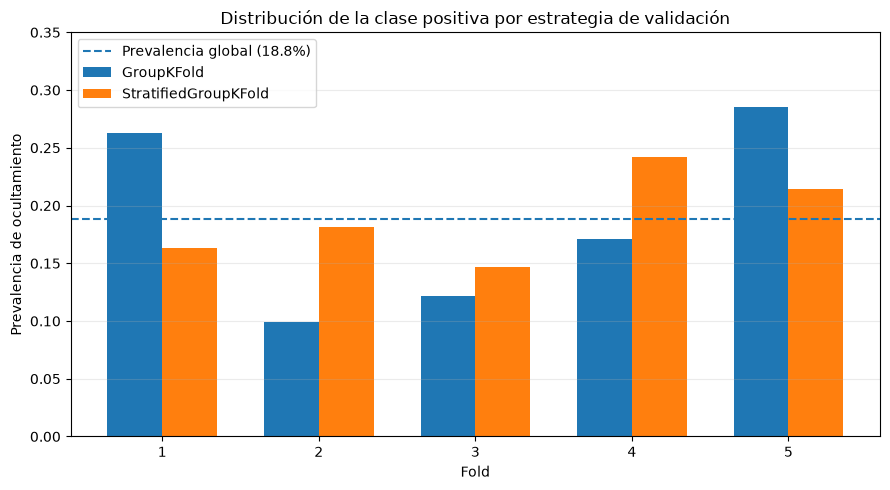

In [18]:
import matplotlib.pyplot as plt


df_folds_group = pd.DataFrame(distribucion_folds_rf)
df_folds_stratified = pd.DataFrame(distribucion_folds_rf_stratified)

folds = df_folds_group["fold"].to_numpy()
prevalencia_group = df_folds_group["val_prevalencia"].to_numpy()
prevalencia_stratified = df_folds_stratified["val_prevalencia"].to_numpy()
prevalencia_global = y_train_rf.mean()

ancho = 0.35

fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    folds - ancho / 2,
    prevalencia_group,
    width=ancho,
    label="GroupKFold"
)

ax.bar(
    folds + ancho / 2,
    prevalencia_stratified,
    width=ancho,
    label="StratifiedGroupKFold"
)

ax.axhline(
    prevalencia_global,
    linestyle="--",
    label=f"Prevalencia global ({prevalencia_global:.1%})"
)

ax.set_xlabel("Fold")
ax.set_ylabel("Prevalencia de ocultamiento")
ax.set_title("Distribución de la clase positiva por estrategia de validación")
ax.set_xticks(folds)
ax.set_ylim(0, 0.35)
ax.legend()
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

En la gráfica se observa que la prevalencia global de la clase `ocultamiento` en `train` es aproximadamente 18.8 %. Con `GroupKFold`, la prevalencia en los folds de validación presenta un rango amplio, entre 9.9 % y 28.6 %, mientras que con `StratifiedGroupKFold` se concentra entre 14.7 % y 24.2 %.

Aunque todavía existe variación entre los folds, `StratifiedGroupKFold` produce distribuciones de clase más cercanas a la prevalencia global de entrenamiento. Este comportamiento respalda su selección como estrategia de validación cruzada para la optimización de Random Forest, manteniendo además la separación por `grupo_experimental`.

### 10.3 Optimización inicial de hiperparámetros

La búsqueda evalúa 30 configuraciones de Random Forest mediante `StratifiedGroupKFold` de cinco pliegues, utilizando Average Precision como criterio de selección. Los grupos experimentales se proporcionan explícitamente durante el ajuste para evitar que clips relacionados aparezcan simultáneamente en los subconjuntos de entrenamiento y validación interna.

Además del desempeño medio de validación cruzada, se conservarán los resultados de entrenamiento de cada configuración para analizar posteriormente posibles diferencias entre el ajuste sobre los folds de entrenamiento y su capacidad de generalización interna.

In [19]:
import time
from sklearn.model_selection import RandomizedSearchCV


def artefactos_rf_validos():
    try:
        artefactos_avance5.validar_random_forest(
            RF_MODELO_PATH,
            RF_BUSQUEDA_PATH,
            RF_RESUMEN_PATH,
            n_train_esperado=len(X_train_rf),
            dim_embedding_esperada=X_train_rf.shape[1],
            n_iter_esperado=30,
            seed_esperada=SEED
        )
        return True

    except (FileNotFoundError, RuntimeError, ValueError):
        return False


if artefactos_rf_validos():
    modelo_rf, resultados_cv_rf, resumen_rf = artefactos_avance5.cargar_random_forest(
        RF_MODELO_PATH,
        RF_BUSQUEDA_PATH,
        RF_RESUMEN_PATH
    )

    print("Random Forest recuperado desde artefactos validados.")

elif GENERAR_MODELOS_A5:
    busqueda_rf = RandomizedSearchCV(
        estimator=rf_base,
        param_distributions=parametros_rf,
        n_iter=30,
        scoring="average_precision",
        cv=cv_rf,
        random_state=SEED,
        n_jobs=-1,
        refit=True,
        return_train_score=True,
        error_score="raise"
    )

    inicio_rf = time.perf_counter()

    busqueda_rf.fit(
        X_train_rf,
        y_train_rf,
        groups=grupos_train_rf
    )

    tiempo_busqueda_rf = time.perf_counter() - inicio_rf
    modelo_rf = busqueda_rf.best_estimator_

    best_params_rf = {
        clave: valor.item() if isinstance(valor, np.generic) else valor
        for clave, valor in busqueda_rf.best_params_.items()
    }

    resumen_rf = {
        "modelo": "RandomForestClassifier",
        "extractor": "r2plus1d_18_kinetics400",
        "scoring": "average_precision",
        "cv": "StratifiedGroupKFold",
        "n_splits": 5,
        "n_iter": 30,
        "seed": SEED,
        "class_weight": "balanced_subsample",
        "best_score_cv": float(busqueda_rf.best_score_),
        "best_params": best_params_rf,
        "tiempo_busqueda_s": float(tiempo_busqueda_rf),
        "tiempo_refit_s": float(busqueda_rf.refit_time_),
        "n_train": len(X_train_rf),
        "dim_embedding": X_train_rf.shape[1],
        "dataset_v2_sha256": validar_avance5.SHA_DATASET_V2
    }

    artefactos_avance5.guardar_random_forest(
        RF_MODELO_PATH,
        RF_BUSQUEDA_PATH,
        RF_RESUMEN_PATH,
        modelo_rf,
        busqueda_rf.cv_results_,
        resumen_rf
    )

    resultados_cv_rf = pd.DataFrame(busqueda_rf.cv_results_)

    print("Random Forest optimizado y artefactos almacenados.")

else:
    raise RuntimeError(
        "No existen artefactos válidos de Random Forest y "
        "GENERAR_MODELOS_A5=False. Active temporalmente "
        "GENERAR_MODELOS_A5=True para generarlos."
    )

Random Forest recuperado desde artefactos validados.


Los artefactos generados durante la optimización de Random Forest se recuperan y validan antes de utilizar el modelo en las etapas posteriores. Esta comprobación verifica la configuración experimental, la dimensión de los embeddings, el número de observaciones utilizadas y la disponibilidad de los resultados de validación cruzada.

Los resultados mostrados a continuación se obtienen directamente de los artefactos persistidos, por lo que pueden reproducirse sin ejecutar nuevamente la búsqueda de hiperparámetros.

In [20]:
validacion_rf = artefactos_avance5.validar_random_forest(
    RF_MODELO_PATH,
    RF_BUSQUEDA_PATH,
    RF_RESUMEN_PATH,
    n_train_esperado=len(X_train_rf),
    dim_embedding_esperada=X_train_rf.shape[1],
    n_iter_esperado=30,
    seed_esperada=SEED
)

modelo_rf, resultados_cv_rf, resumen_rf = artefactos_avance5.cargar_random_forest(
    RF_MODELO_PATH,
    RF_BUSQUEDA_PATH,
    RF_RESUMEN_PATH
)

display(pd.DataFrame([validacion_rf]))

print("Mejor Average Precision CV:", round(resumen_rf["best_score_cv"], 4))
print("Mejores hiperparámetros:", resumen_rf["best_params"])
print("Tiempo de búsqueda:", round(resumen_rf["tiempo_busqueda_s"], 2), "s")
print("Tiempo de ajuste final:", round(resumen_rf["tiempo_refit_s"], 4), "s")

,modelo,configuraciones,best_score_cv,dim_embedding,estado
0,RandomForestClassifier,30,0.524457,512,OK


Mejor Average Precision CV: 0.5245
Mejores hiperparámetros: {'max_depth': None, 'max_features': 0.2, 'min_samples_leaf': 4, 'n_estimators': 221}
Tiempo de búsqueda: 97.77 s
Tiempo de ajuste final: 1.047 s


In [21]:
columnas_rf = [
    "rank_test_score",
    "mean_train_score",
    "mean_test_score",
    "std_test_score",
    "mean_fit_time",
    "param_n_estimators",
    "param_max_depth",
    "param_min_samples_leaf",
    "param_max_features"
]

top_rf = (
    resultados_cv_rf[columnas_rf]
    .sort_values("rank_test_score")
    .head(10)
    .reset_index(drop=True)
)

top_rf["gap_train_cv"] = (
    top_rf["mean_train_score"] - top_rf["mean_test_score"]
)

display(top_rf)

,rank_test_score,mean_train_score,mean_test_score,std_test_score,mean_fit_time,param_n_estimators,param_max_depth,param_min_samples_leaf,param_max_features,gap_train_cv
0,1,0.999197,0.524457,0.180900,3.486968,221,NaN,4,0.2,0.474741
1,2,0.990120,0.519468,0.152030,2.730034,220,NaN,7,0.1,0.470651
2,3,0.993654,0.518484,0.173283,8.181293,708,15.0,6,0.1,0.475170
3,4,0.999983,0.517420,0.176895,6.901134,761,10.0,3,0.05,0.482563
4,5,0.977856,0.515940,0.163895,2.443591,264,NaN,9,sqrt,0.461917
5,6,1.000000,0.513069,0.172122,6.766856,591,10.0,3,0.1,0.486931
6,7,0.978570,0.512618,0.163283,8.733924,676,5.0,8,0.2,0.465952
7,8,1.000000,0.511632,0.168531,7.908468,543,NaN,3,0.1,0.488368
8,9,0.999345,0.511529,0.169056,8.096175,416,20.0,4,0.2,0.487816
9,10,0.999208,0.511056,0.172337,6.938246,587,NaN,4,0.1,0.488153


Los resultados muestran una diferencia importante entre el Average Precision obtenido en los folds de entrenamiento y el alcanzado en los folds internos de validación. Random Forest ajusta casi perfectamente los datos utilizados durante el entrenamiento, mientras que su desempeño disminuye de forma considerable al evaluar grupos no vistos, lo que indica un patrón de sobreajuste.

Las diez mejores configuraciones presentan resultados de validación cruzada relativamente cercanos. Entre la primera y la décima posición existe una diferencia de aproximadamente 0.0134 puntos de Average Precision, por lo que no se observa una combinación de hiperparámetros claramente superior al resto.

También se observa una variabilidad considerable entre los cinco folds. Aunque `StratifiedGroupKFold` redujo las diferencias en la proporción de clases, los grupos experimentales parecen conservar distintos niveles de dificultad.

Finalmente, limitar `max_depth` por sí solo no elimina la brecha entre entrenamiento y validación. Configuraciones con `max_depth` de 15, 10 y 5 mantienen diferencias de aproximadamente 0.4752, 0.4826 y 0.4660, respectivamente. Por esta razón, el control del sobreajuste requiere evaluar conjuntamente otros parámetros de regularización, particularmente `min_samples_leaf` y `max_features`.

### 10.4 Evaluación de regularización

A partir de la brecha observada entre el Average Precision de entrenamiento y validación cruzada, se realizará una segunda búsqueda enfocada en configuraciones más regularizadas.

En esta etapa se restringirá la profundidad de los árboles, se incrementará el número mínimo de observaciones por hoja y se limitará la cantidad de características consideradas en cada división. El número de árboles se mantendrá fijo, ya que su incremento afecta principalmente la estabilidad y el costo computacional del bosque, pero no constituye un mecanismo directo de regularización.

In [22]:
rf_regularizado_base = RandomForestClassifier(
    n_estimators=400,
    class_weight="balanced_subsample",
    random_state=SEED,
    n_jobs=-1
)

parametros_rf_regularizado = {
    "max_depth": [4, 5, 6, 8, 10, 12],
    "min_samples_leaf": [8, 10, 12, 15, 20],
    "max_features": ["sqrt", 0.05, 0.10]
}

print("Hiperparámetros regularizados:", list(parametros_rf_regularizado.keys()))
print("Número de árboles fijo:", rf_regularizado_base.n_estimators)
print("Class weight:", rf_regularizado_base.class_weight)

Hiperparámetros regularizados: ['max_depth', 'min_samples_leaf', 'max_features']
Número de árboles fijo: 400
Class weight: balanced_subsample


In [23]:
def artefactos_rf_reg_validos():
    try:
        artefactos_avance5.validar_random_forest(
            RF_REG_MODELO_PATH,
            RF_REG_BUSQUEDA_PATH,
            RF_REG_RESUMEN_PATH,
            n_train_esperado=len(X_train_rf),
            dim_embedding_esperada=X_train_rf.shape[1],
            n_iter_esperado=20,
            seed_esperada=SEED
        )
        return True

    except (FileNotFoundError, RuntimeError, ValueError):
        return False


if artefactos_rf_reg_validos():
    modelo_rf_reg, resultados_cv_rf_reg, resumen_rf_reg = (
        artefactos_avance5.cargar_random_forest(
            RF_REG_MODELO_PATH,
            RF_REG_BUSQUEDA_PATH,
            RF_REG_RESUMEN_PATH
        )
    )

    print("Random Forest regularizado recuperado desde artefactos validados.")

elif GENERAR_MODELOS_A5:
    busqueda_rf_reg = RandomizedSearchCV(
        estimator=rf_regularizado_base,
        param_distributions=parametros_rf_regularizado,
        n_iter=20,
        scoring="average_precision",
        cv=cv_rf,
        random_state=SEED,
        n_jobs=-1,
        refit=True,
        return_train_score=True,
        error_score="raise"
    )

    inicio_rf_reg = time.perf_counter()

    busqueda_rf_reg.fit(
        X_train_rf,
        y_train_rf,
        groups=grupos_train_rf
    )

    tiempo_busqueda_rf_reg = time.perf_counter() - inicio_rf_reg
    modelo_rf_reg = busqueda_rf_reg.best_estimator_

    best_params_rf_reg = {
        clave: valor.item() if isinstance(valor, np.generic) else valor
        for clave, valor in busqueda_rf_reg.best_params_.items()
    }

    resumen_rf_reg = {
        "modelo": "RandomForestClassifier",
        "extractor": "r2plus1d_18_kinetics400",
        "scoring": "average_precision",
        "cv": "StratifiedGroupKFold",
        "n_splits": 5,
        "n_iter": 20,
        "seed": SEED,
        "class_weight": "balanced_subsample",
        "best_score_cv": float(busqueda_rf_reg.best_score_),
        "best_params": best_params_rf_reg,
        "n_estimators_fijo": 400,
        "tiempo_busqueda_s": float(tiempo_busqueda_rf_reg),
        "tiempo_refit_s": float(busqueda_rf_reg.refit_time_),
        "n_train": len(X_train_rf),
        "dim_embedding": X_train_rf.shape[1],
        "dataset_v2_sha256": validar_avance5.SHA_DATASET_V2
    }

    artefactos_avance5.guardar_random_forest(
        RF_REG_MODELO_PATH,
        RF_REG_BUSQUEDA_PATH,
        RF_REG_RESUMEN_PATH,
        modelo_rf_reg,
        busqueda_rf_reg.cv_results_,
        resumen_rf_reg
    )

    resultados_cv_rf_reg = pd.DataFrame(busqueda_rf_reg.cv_results_)

    print("Random Forest regularizado optimizado y artefactos almacenados.")

else:
    raise RuntimeError(
        "No existen artefactos válidos del Random Forest regularizado y "
        "GENERAR_MODELOS_A5=False. Active temporalmente "
        "GENERAR_MODELOS_A5=True para generarlos."
    )

Random Forest regularizado recuperado desde artefactos validados.


Los artefactos correspondientes a la segunda búsqueda de Random Forest se recuperan y validan antes de comparar sus resultados con la búsqueda inicial. Esta comprobación permite confirmar que el modelo, los resultados de validación cruzada y la configuración experimental pueden reutilizarse sin repetir el proceso de optimización.

In [24]:
validacion_rf_reg = artefactos_avance5.validar_random_forest(
    RF_REG_MODELO_PATH,
    RF_REG_BUSQUEDA_PATH,
    RF_REG_RESUMEN_PATH,
    n_train_esperado=len(X_train_rf),
    dim_embedding_esperada=X_train_rf.shape[1],
    n_iter_esperado=20,
    seed_esperada=SEED
)

modelo_rf_reg, resultados_cv_rf_reg, resumen_rf_reg = (
    artefactos_avance5.cargar_random_forest(
        RF_REG_MODELO_PATH,
        RF_REG_BUSQUEDA_PATH,
        RF_REG_RESUMEN_PATH
    )
)

display(pd.DataFrame([validacion_rf_reg]))

print("Mejor Average Precision CV:", round(resumen_rf_reg["best_score_cv"], 4))
print("Mejores hiperparámetros:", resumen_rf_reg["best_params"])
print("Número de árboles:", resumen_rf_reg["n_estimators_fijo"])
print("Tiempo de búsqueda:", round(resumen_rf_reg["tiempo_busqueda_s"], 2), "s")
print("Tiempo de ajuste final:", round(resumen_rf_reg["tiempo_refit_s"], 4), "s")

,modelo,configuraciones,best_score_cv,dim_embedding,estado
0,RandomForestClassifier,20,0.520684,512,OK


Mejor Average Precision CV: 0.5207
Mejores hiperparámetros: {'min_samples_leaf': 8, 'max_features': 0.1, 'max_depth': 6}
Número de árboles: 400
Tiempo de búsqueda: 39.89 s
Tiempo de ajuste final: 1.4605 s


In [25]:
mejor_rf_inicial = (
    resultados_cv_rf
    .sort_values("rank_test_score")
    .iloc[0]
)

mejor_rf_reg = (
    resultados_cv_rf_reg
    .sort_values("rank_test_score")
    .iloc[0]
)

comparacion_rf = pd.DataFrame([
    {
        "busqueda": "Inicial",
        "mean_train_AP": mejor_rf_inicial["mean_train_score"],
        "mean_cv_AP": mejor_rf_inicial["mean_test_score"],
        "std_cv_AP": mejor_rf_inicial["std_test_score"],
        "gap_train_cv": (
            mejor_rf_inicial["mean_train_score"]
            - mejor_rf_inicial["mean_test_score"]
        )
    },
    {
        "busqueda": "Regularizada",
        "mean_train_AP": mejor_rf_reg["mean_train_score"],
        "mean_cv_AP": mejor_rf_reg["mean_test_score"],
        "std_cv_AP": mejor_rf_reg["std_test_score"],
        "gap_train_cv": (
            mejor_rf_reg["mean_train_score"]
            - mejor_rf_reg["mean_test_score"]
        )
    }
])

display(comparacion_rf)

,busqueda,mean_train_AP,mean_cv_AP,std_cv_AP,gap_train_cv
0,Inicial,0.999197,0.524457,0.180900,0.474741
1,Regularizada,0.982418,0.520684,0.172455,0.461733


Para visualizar el efecto de la regularización, se comparan el Average Precision medio obtenido en los folds de entrenamiento y en los folds de validación cruzada para la mejor configuración de cada búsqueda.

La comparación permite observar tanto la magnitud de la brecha entre entrenamiento y validación como el efecto real de las restricciones adicionales aplicadas durante la segunda búsqueda.

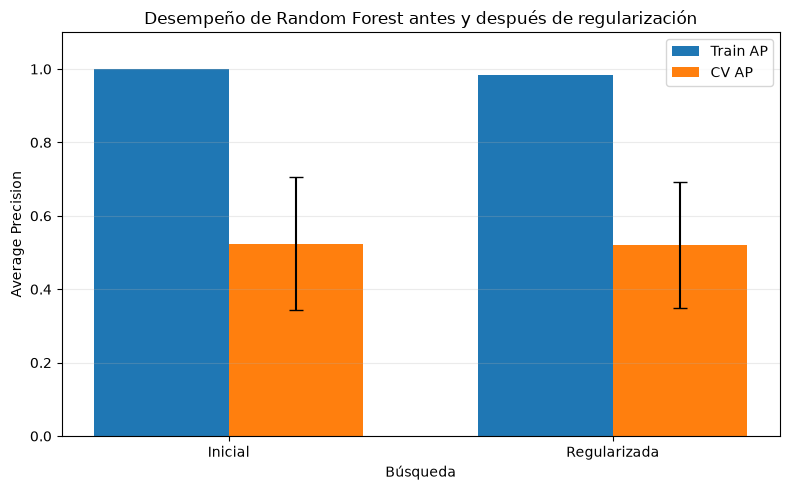

In [26]:
etiquetas = comparacion_rf["busqueda"].to_numpy()
ap_train = comparacion_rf["mean_train_AP"].to_numpy()
ap_cv = comparacion_rf["mean_cv_AP"].to_numpy()
std_cv = comparacion_rf["std_cv_AP"].to_numpy()

x = np.arange(len(etiquetas))
ancho = 0.35

fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(
    x - ancho / 2,
    ap_train,
    width=ancho,
    label="Train AP"
)

ax.bar(
    x + ancho / 2,
    ap_cv,
    width=ancho,
    yerr=std_cv,
    capsize=5,
    label="CV AP"
)

ax.set_xlabel("Búsqueda")
ax.set_ylabel("Average Precision")
ax.set_title("Desempeño de Random Forest antes y después de regularización")
ax.set_xticks(x)
ax.set_xticklabels(etiquetas)
ax.set_ylim(0, 1.1)
ax.legend()
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

Como se observa en la gráfica, la segunda búsqueda redujo de forma limitada el sobreajuste observado en Random Forest. El `gap_train_cv` disminuyó aproximadamente 0.0130 puntos, de 0.4747 a 0.4617, por lo que la estrategia de regularización produjo una mejora pequeña, pero no resolvió el problema principal.

También se observó una ligera reducción en la variabilidad entre folds, mientras que el Average Precision medio de validación cruzada disminuyó de 0.5245 a 0.5207. Esto indica que la regularización redujo ligeramente la brecha entre entrenamiento y validación, pero también produjo una pequeña disminución en el desempeño medio de validación cruzada, sin modificar de manera sustancial el comportamiento general del modelo.

Con base en estos resultados, no se justifica realizar una tercera búsqueda de hiperparámetros. La evidencia obtenida es suficiente para caracterizar el comportamiento de Random Forest y continuar con la selección de la configuración que se evaluará sobre `validation`.

### 10.5 Selección de la configuración de Random Forest

La búsqueda inicial se selecciona como configuración definitiva de Random Forest para su evaluación sobre `validation`, debido a que obtuvo el mayor Average Precision medio de validación cruzada, 0.5245 frente a 0.5207 de la búsqueda regularizada.

La búsqueda regularizada se conserva como evidencia del análisis de sobreajuste realizado, pero su ligera mejora en estabilidad no compensó la reducción observada en la métrica principal.

### 10.6 Evaluación sobre validation

La configuración seleccionada de Random Forest se evalúa sobre la partición `validation`, que no participó en la optimización interna de sus hiperparámetros. El modelo utiliza los embeddings preentrenados en Kinetics-400 recuperados previamente y genera una puntuación de probabilidad de `ocultamiento` para cada clip.

Estas puntuaciones se utilizarán para calcular las métricas de desempeño y comparar posteriormente Random Forest con los demás ensambles y con el mejor modelo individual del Avance 4.

In [27]:
prob_rf_val = modelo_rf.predict_proba(X_val_rf)[:, 1]

print("Predicciones:", prob_rf_val.shape)
print("Etiquetas:", y_val_rf.shape)
print("Valores finitos:", bool(np.isfinite(prob_rf_val).all()))
print("Probabilidad mínima:", round(float(prob_rf_val.min()), 4))
print("Probabilidad máxima:", round(float(prob_rf_val.max()), 4))

Predicciones: (136,)
Etiquetas: (136,)
Valores finitos: True
Probabilidad mínima: 0.0456
Probabilidad máxima: 0.8485


La evaluación inicial de Random Forest sobre `validation` utiliza métricas independientes de un threshold de clasificación. De esta forma se mide primero la capacidad del modelo para ordenar y separar ejemplos positivos y negativos sin introducir todavía una decisión sobre el punto de operación.

Se calculan Average Precision como métrica principal, PR-AUC y ROC-AUC como métricas complementarias, y EER como referencia del equilibrio entre falsos positivos y falsos negativos.

In [28]:
from sklearn.metrics import (
    average_precision_score,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
    auc
)


ap_rf_val = average_precision_score(y_val_rf, prob_rf_val)

precision_rf_val, recall_rf_val, _ = precision_recall_curve(
    y_val_rf,
    prob_rf_val
)

pr_auc_rf_val = auc(recall_rf_val, precision_rf_val)
roc_auc_rf_val = roc_auc_score(y_val_rf, prob_rf_val)

fpr_rf_val, tpr_rf_val, thresholds_roc_rf_val = roc_curve(
    y_val_rf,
    prob_rf_val
)

fnr_rf_val = 1 - tpr_rf_val
indice_eer_rf_val = np.nanargmin(np.abs(fpr_rf_val - fnr_rf_val))
eer_rf_val = (fpr_rf_val[indice_eer_rf_val] + fnr_rf_val[indice_eer_rf_val]) / 2

print("Average Precision:", round(ap_rf_val, 4))
print("PR-AUC:", round(pr_auc_rf_val, 4))
print("ROC-AUC:", round(roc_auc_rf_val, 4))
print("EER:", round(eer_rf_val, 4))

Average Precision: 0.5164
PR-AUC: 0.4959
ROC-AUC: 0.7519
EER: 0.2821


El Average Precision obtenido sobre `validation`, de 0.5164, es cercano al Average Precision medio de 0.5245 alcanzado durante la validación cruzada interna. Esta proximidad respalda que `StratifiedGroupKFold` proporcionó una estimación razonable del comportamiento de Random Forest sobre grupos no observados durante su ajuste.

Sin embargo, el Average Precision de `validation` continúa siendo muy inferior al valor cercano a 1.0 observado en los folds de entrenamiento, por lo que el patrón de sobreajuste permanece. Aun así, el desempeño fuera de muestra se mantiene relativamente estable alrededor de 0.52, lo que indica que la validación cruzada no produjo una estimación artificialmente optimista.

Las métricas calculadas hasta este punto caracterizan la capacidad de discriminación del modelo y todavía no definen un punto de operación específico.

### 10.7 Selección del threshold y punto de operación

El punto de operación de Random Forest se selecciona utilizando exclusivamente la partición `validation` y siguiendo el mismo criterio aplicado al modelo individual final del Avance 4.

Se evalúan como thresholds candidatos los scores únicos producidos por el modelo. La selección prioriza el mayor F1 y, en caso de empate, utiliza recall y precision como criterios sucesivos de desempate. Este procedimiento mantiene un criterio experimental común entre el modelo individual y los ensambles.

In [29]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score


thresholds_rf = np.unique(prob_rf_val)
resultados_threshold_rf = []

for threshold in thresholds_rf:
    pred_rf = (prob_rf_val >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val_rf,
        pred_rf,
        labels=[0, 1]
    ).ravel()

    precision = precision_score(
        y_val_rf,
        pred_rf,
        zero_division=0
    )

    recall = recall_score(
        y_val_rf,
        pred_rf,
        zero_division=0
    )

    f1 = f1_score(
        y_val_rf,
        pred_rf,
        zero_division=0
    )

    specificity = tn / (tn + fp) if (tn + fp) > 0 else np.nan

    resultados_threshold_rf.append({
        "threshold": float(threshold),
        "f1": float(f1),
        "recall": float(recall),
        "precision": float(precision),
        "specificity": float(specificity),
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp)
    })

df_thresholds_rf = pd.DataFrame(resultados_threshold_rf)

mejor_threshold_rf = (
    df_thresholds_rf
    .sort_values(
        ["f1", "recall", "precision"],
        ascending=[False, False, False]
    )
    .iloc[0]
)

THRESHOLD_RF = float(mejor_threshold_rf["threshold"])

print("Threshold seleccionado:", round(THRESHOLD_RF, 4))

display(
    mejor_threshold_rf
    .to_frame(name="valor")
    .T
    .style.format({
        "threshold": "{:.4f}",
        "f1": "{:.4f}",
        "recall": "{:.4f}",
        "precision": "{:.4f}",
        "specificity": "{:.4f}"
    })
)

Threshold seleccionado: 0.461


,threshold,f1,recall,precision,specificity,tn,fp,fn,tp
valor,0.4610,0.5455,0.5000,0.6000,0.9057,96.000000,10.000000,15.000000,15.000000


El threshold seleccionado fue 0.4610 y corresponde al punto de operación que obtuvo el mayor F1 sobre `validation` bajo el protocolo definido previamente.

En este punto de operación, Random Forest detecta únicamente la mitad de los casos positivos, con un recall de 0.5000, mientras que conserva una capacidad alta para rechazar correctamente los casos negativos, con una specificity de 0.9057. La matriz de confusión muestra 10 falsos positivos y 15 falsos negativos.

Los falsos positivos son especialmente relevantes para el contexto de BNext, debido a su preferencia cualitativa por reducir falsas alarmas que puedan generar revisiones innecesarias. Sin embargo, el número de falsos negativos también constituye una limitación importante, ya que el modelo deja sin detectar la mitad de los eventos de ocultamiento presentes en `validation`.

El threshold seleccionado debe interpretarse como un punto de operación experimental y no como un valor definitivo para una implementación en tienda.

## 11. Ensamble homogéneo 2: AdaBoost

AdaBoost utilizará los mismos embeddings de 512 características generados mediante R(2+1)D-18 preentrenado en Kinetics-400. Esto permite comparar ambos ensambles homogéneos utilizando una representación de entrada común y sin incorporar información de las etiquetas del proyecto durante la extracción de características.

A diferencia de Random Forest, que combina múltiples árboles entrenados de forma independiente sobre muestras y subconjuntos de características, AdaBoost construye los estimadores de manera secuencial y aumenta el peso de las observaciones clasificadas incorrectamente por los estimadores anteriores. Esta diferencia permite evaluar si un mecanismo de ensamble basado en boosting puede aprovechar mejor las representaciones espacio temporales obtenidas de los clips.

### 11.1 Preparación de datos y estrategia de validación

AdaBoost utilizará las mismas particiones `train` y `validation`, los mismos embeddings de 512 características y la misma variable `grupo_experimental` empleadas en Random Forest.

La optimización de hiperparámetros se realizará exclusivamente sobre `train` mediante `StratifiedGroupKFold` de cinco pliegues. Mantener esta estrategia permite preservar la separación entre grupos experimentales y utilizar un procedimiento de validación comparable entre los dos ensambles homogéneos.

### 11.2 Optimización de hiperparámetros

La optimización de AdaBoost se concentrará en tres aspectos: la complejidad del árbol base, el número máximo de estimadores y la tasa de aprendizaje. Los árboles base se mantendrán deliberadamente poco profundos, ya que AdaBoost combina secuencialmente clasificadores débiles y aumenta la atención sobre las observaciones clasificadas incorrectamente en iteraciones anteriores.

Se evaluarán diferentes valores de `max_depth` y `min_samples_leaf` para controlar la complejidad del estimador base. Además, se ajustarán `n_estimators` y `learning_rate`, parámetros que presentan un compromiso entre el número de etapas de boosting y la contribución individual de cada estimador.

Las configuraciones se evaluarán mediante `StratifiedGroupKFold` de cinco pliegues y Average Precision como métrica principal, manteniendo el mismo protocolo utilizado para Random Forest.

In [30]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import RandomizedSearchCV


arbol_base_adaboost = DecisionTreeClassifier(
    random_state=SEED
)

adaboost_base = AdaBoostClassifier(
    estimator=arbol_base_adaboost,
    random_state=SEED
)

parametros_adaboost = {
    "estimator__max_depth": [1, 2, 3],
    "estimator__min_samples_leaf": [2, 4, 8, 12],
    "n_estimators": [50, 100, 150, 200, 300, 400],
    "learning_rate": [0.01, 0.03, 0.10, 0.30, 0.50, 1.00]
}

busqueda_adaboost = RandomizedSearchCV(
    estimator=adaboost_base,
    param_distributions=parametros_adaboost,
    n_iter=30,
    scoring="average_precision",
    cv=cv_rf,
    refit=True,
    return_train_score=True,
    random_state=SEED,
    n_jobs=-1
)

In [31]:
def artefactos_adaboost_validos():
    try:
        artefactos_avance5.validar_adaboost(
            ADABOOST_MODELO_PATH,
            ADABOOST_BUSQUEDA_PATH,
            ADABOOST_RESUMEN_PATH,
            n_train_esperado=len(X_train_rf),
            dim_embedding_esperada=X_train_rf.shape[1],
            n_iter_esperado=30,
            seed_esperada=SEED,
            dataset_sha256_esperado=validar_avance5.SHA_DATASET_V2
        )
        return True

    except (
        FileNotFoundError,
        ValueError,
        TypeError,
        RuntimeError
    ):
        return False


if artefactos_adaboost_validos():
    modelo_adaboost, resultados_cv_adaboost, resumen_adaboost = (
        artefactos_avance5.cargar_adaboost(
            ADABOOST_MODELO_PATH,
            ADABOOST_BUSQUEDA_PATH,
            ADABOOST_RESUMEN_PATH
        )
    )

    print("AdaBoost recuperado desde artefactos validados.")

elif GENERAR_MODELOS_A5:
    busqueda_adaboost = RandomizedSearchCV(
        estimator=adaboost_base,
        param_distributions=parametros_adaboost,
        n_iter=30,
        scoring="average_precision",
        cv=cv_rf,
        refit=True,
        return_train_score=True,
        random_state=SEED,
        n_jobs=-1,
        error_score="raise"
    )

    inicio_adaboost = time.perf_counter()

    busqueda_adaboost.fit(
        X_train_rf,
        y_train_rf,
        groups=grupos_train_rf
    )

    tiempo_busqueda_adaboost = (
        time.perf_counter()
        - inicio_adaboost
    )

    modelo_adaboost = busqueda_adaboost.best_estimator_

    best_params_adaboost = {
        clave: valor.item() if isinstance(valor, np.generic) else valor
        for clave, valor in busqueda_adaboost.best_params_.items()
    }

    resumen_adaboost = {
        "modelo": "AdaBoostClassifier",
        "extractor": "r2plus1d_18_kinetics400",
        "scoring": "average_precision",
        "cv": "StratifiedGroupKFold",
        "n_splits": 5,
        "n_iter": 30,
        "seed": SEED,
        "best_score_cv": float(busqueda_adaboost.best_score_),
        "best_params": best_params_adaboost,
        "tiempo_busqueda_s": float(tiempo_busqueda_adaboost),
        "tiempo_refit_s": float(busqueda_adaboost.refit_time_),
        "n_train": len(X_train_rf),
        "dim_embedding": X_train_rf.shape[1],
        "dataset_v2_sha256": validar_avance5.SHA_DATASET_V2
    }

    artefactos_avance5.guardar_adaboost(
        ADABOOST_MODELO_PATH,
        ADABOOST_BUSQUEDA_PATH,
        ADABOOST_RESUMEN_PATH,
        modelo_adaboost,
        busqueda_adaboost.cv_results_,
        resumen_adaboost
    )

    resultados_cv_adaboost = pd.DataFrame(
        busqueda_adaboost.cv_results_
    )

    print("AdaBoost optimizado y artefactos almacenados.")

else:
    raise RuntimeError(
        "No existen artefactos válidos de AdaBoost y "
        "GENERAR_MODELOS_A5=False. Active temporalmente "
        "GENERAR_MODELOS_A5=True para generarlos."
    )

AdaBoost recuperado desde artefactos validados.


In [32]:
validacion_adaboost = artefactos_avance5.validar_adaboost(
    ADABOOST_MODELO_PATH,
    ADABOOST_BUSQUEDA_PATH,
    ADABOOST_RESUMEN_PATH,
    n_train_esperado=len(X_train_rf),
    dim_embedding_esperada=X_train_rf.shape[1],
    n_iter_esperado=30,
    seed_esperada=SEED,
    dataset_sha256_esperado=validar_avance5.SHA_DATASET_V2
)

display(pd.DataFrame([validacion_adaboost]))

,modelo,configuraciones_cv,dim_embedding,best_score_cv
0,AdaBoostClassifier,30,512,0.492138


In [33]:
mejor_adaboost = (
    resultados_cv_adaboost
    .sort_values("rank_test_score")
    .iloc[0]
)

resumen_mejor_adaboost = pd.DataFrame([{
    "mean_train_AP": mejor_adaboost["mean_train_score"],
    "mean_cv_AP": mejor_adaboost["mean_test_score"],
    "std_cv_AP": mejor_adaboost["std_test_score"],
    "gap_train_cv": (
        mejor_adaboost["mean_train_score"]
        - mejor_adaboost["mean_test_score"]
    ),
    "max_depth": mejor_adaboost["param_estimator__max_depth"],
    "min_samples_leaf": mejor_adaboost["param_estimator__min_samples_leaf"],
    "n_estimators": mejor_adaboost["param_n_estimators"],
    "learning_rate": mejor_adaboost["param_learning_rate"]
}])

display(resumen_mejor_adaboost)

,mean_train_AP,mean_cv_AP,std_cv_AP,gap_train_cv,max_depth,min_samples_leaf,n_estimators,learning_rate
0,1.0,0.492138,0.169994,0.507862,3,12,50,0.3


In [34]:
top10_adaboost = (
    resultados_cv_adaboost
    .sort_values("rank_test_score")
    .head(10)
    .copy()
)

top10_adaboost["gap_train_cv"] = (
    top10_adaboost["mean_train_score"]
    - top10_adaboost["mean_test_score"]
)

columnas_top10_adaboost = [
    "rank_test_score",
    "mean_train_score",
    "mean_test_score",
    "std_test_score",
    "gap_train_cv",
    "param_estimator__max_depth",
    "param_estimator__min_samples_leaf",
    "param_n_estimators",
    "param_learning_rate"
]

display(
    top10_adaboost[columnas_top10_adaboost]
    .style.format({
        "mean_train_score": "{:.4f}",
        "mean_test_score": "{:.4f}",
        "std_test_score": "{:.4f}",
        "gap_train_cv": "{:.4f}"
    })
)

,rank_test_score,mean_train_score,mean_test_score,std_test_score,gap_train_cv,param_estimator__max_depth,param_estimator__min_samples_leaf,param_n_estimators,param_learning_rate
6,1,1.0000,0.4921,0.1700,0.5079,3,12,50,0.300000
19,2,1.0000,0.4856,0.1831,0.5144,2,12,300,0.500000
26,3,0.9822,0.4787,0.1638,0.5034,2,2,100,0.100000
27,4,1.0000,0.4768,0.1723,0.5232,3,8,100,1.000000
4,5,1.0000,0.4728,0.1774,0.5272,3,8,150,1.000000
12,6,1.0000,0.4728,0.1838,0.5272,2,4,100,0.300000
16,7,1.0000,0.4673,0.1699,0.5327,3,8,300,0.300000
7,8,0.9725,0.4665,0.1642,0.5060,2,2,300,0.030000
0,9,1.0000,0.4630,0.1635,0.5370,3,12,300,0.500000
15,10,1.0000,0.4624,0.1878,0.5376,2,2,400,0.500000


### 11.3 Evaluación de regularización

Las diez mejores configuraciones de AdaBoost presentan una brecha elevada entre el Average Precision de entrenamiento y validación cruzada. El `gap_train_cv` se mantiene aproximadamente entre 0.50 y 0.54 y varias configuraciones alcanzan un Average Precision de entrenamiento igual a 1.0.

La mejor configuración obtiene un Average Precision medio de validación cruzada de 0.4921 y utiliza `min_samples_leaf=12`, el valor más restrictivo considerado en la búsqueda inicial. Esto indica que, incluso con restricciones sobre el árbol base, el ensamble continúa ajustándose con gran precisión a los folds de entrenamiento sin lograr una generalización equivalente sobre grupos no observados.

Dado que el desempeño de validación cruzada permanece alrededor de 0.49 y la brecha entre entrenamiento y validación es consistente entre las mejores configuraciones, no se realizará una segunda búsqueda de hiperparámetros. La evidencia obtenida es suficiente para caracterizar el comportamiento de AdaBoost con los embeddings congelados de Kinetics-400 y continuar con su evaluación sobre `validation`.

### 11.4 Evaluación sobre validation

La mejor configuración obtenida durante la búsqueda de hiperparámetros se evalúa sobre la partición `validation`, que no participó en la optimización interna de AdaBoost.

Esta evaluación permitirá comparar el desempeño fuera de muestra de AdaBoost con Random Forest y, posteriormente, con los ensambles heterogéneos y el mejor modelo individual del Avance 4. Average Precision se mantiene como métrica principal, complementada con PR-AUC, ROC-AUC y EER.

In [35]:
prob_adaboost_val = modelo_adaboost.predict_proba(
    X_val_rf
)[:, 1]

ap_adaboost_val = average_precision_score(
    y_val_rf,
    prob_adaboost_val
)

precision_adaboost_val, recall_adaboost_val, _ = precision_recall_curve(
    y_val_rf,
    prob_adaboost_val
)

pr_auc_adaboost_val = auc(
    recall_adaboost_val,
    precision_adaboost_val
)

roc_auc_adaboost_val = roc_auc_score(
    y_val_rf,
    prob_adaboost_val
)

fpr_adaboost_val, tpr_adaboost_val, thresholds_roc_adaboost_val = roc_curve(
    y_val_rf,
    prob_adaboost_val
)

fnr_adaboost_val = 1 - tpr_adaboost_val

indice_eer_adaboost_val = np.nanargmin(
    np.abs(fpr_adaboost_val - fnr_adaboost_val)
)

eer_adaboost_val = (
    fpr_adaboost_val[indice_eer_adaboost_val]
    + fnr_adaboost_val[indice_eer_adaboost_val]
) / 2

print("Average Precision:", round(ap_adaboost_val, 4))
print("PR-AUC:", round(pr_auc_adaboost_val, 4))
print("ROC-AUC:", round(roc_auc_adaboost_val, 4))
print("EER:", round(eer_adaboost_val, 4))

Average Precision: 0.5538
PR-AUC: 0.5442
ROC-AUC: 0.7698
EER: 0.2654


El resultado de `validation` es mejor que lo sugerido por la validación cruzada interna, con un Average Precision de 0.5538 frente a un CV AP de 0.4921. Esto sugiere que la validación cruzada produjo una estimación conservadora para esta partición, aunque no elimina la evidencia de sobreajuste observada durante el entrenamiento.

AdaBoost supera a Random Forest en `validation`, pero ambos permanecen por debajo de R(2+1)D-18/H5. Este comportamiento sugiere que los embeddings congelados de Kinetics-400 contienen información útil para separar las clases, pero los ensambles de árboles construidos sobre estas representaciones tienen menor capacidad de generalización que el modelo RGB ajustado específicamente para la tarea de ocultamiento.

Este resultado puede considerarse un hallazgo metodológico más que un experimento fallido y respalda la decisión de no invertir en búsquedas adicionales de hiperparámetros para AdaBoost.

### 11.5 Selección del threshold y punto de operación

El punto de operación de AdaBoost se selecciona utilizando exclusivamente la partición `validation` y siguiendo el mismo procedimiento aplicado al modelo individual final del Avance 4 y a Random Forest.

Se utilizan como candidatos los valores únicos de probabilidad estimados por el modelo sobre `validation`. Para cada threshold se calculan precision, recall, especificidad y F1. La selección se realiza ordenando primero por F1, después por recall y finalmente por precision.

Este procedimiento mantiene un criterio común entre los modelos evaluados y permite analizar posteriormente el comportamiento de AdaBoost en términos de falsos positivos y falsos negativos.

In [36]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score

resultados_threshold_adaboost = []

for threshold in np.unique(prob_adaboost_val):
    pred_adaboost_val = (prob_adaboost_val >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val_rf,
        pred_adaboost_val,
        labels=[0, 1]
    ).ravel()

    resultados_threshold_adaboost.append({
        "threshold": threshold,
        "precision": precision_score(
            y_val_rf,
            pred_adaboost_val,
            zero_division=0
        ),
        "recall": recall_score(
            y_val_rf,
            pred_adaboost_val,
            zero_division=0
        ),
        "specificity": tn / (tn + fp),
        "f1": f1_score(
            y_val_rf,
            pred_adaboost_val,
            zero_division=0
        ),
        "tn": tn,
        "fp": fp,
        "fn": fn,
        "tp": tp
    })

df_threshold_adaboost = pd.DataFrame(
    resultados_threshold_adaboost
)

mejor_threshold_adaboost = (
    df_threshold_adaboost
    .sort_values(
        ["f1", "recall", "precision"],
        ascending=False
    )
    .iloc[0]
)

display(pd.DataFrame([mejor_threshold_adaboost]))

,threshold,precision,recall,specificity,f1,tn,fp,fn,tp
83,0.323732,0.433962,0.766667,0.716981,0.554217,76.0,30.0,7.0,23.0


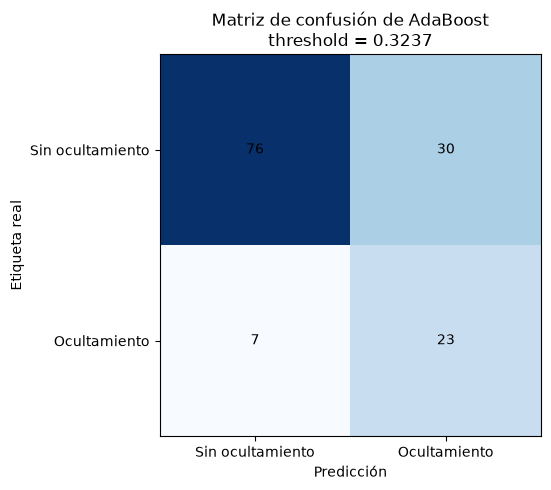

In [37]:
threshold_adaboost = float(
    mejor_threshold_adaboost["threshold"]
)

pred_adaboost_val = (
    prob_adaboost_val >= threshold_adaboost
).astype(int)

matriz_adaboost = confusion_matrix(
    y_val_rf,
    pred_adaboost_val,
    labels=[0, 1]
)

fig, ax = plt.subplots(figsize=(6, 5))

imagen = ax.imshow(
    matriz_adaboost,
    cmap="Blues"
)

for i in range(matriz_adaboost.shape[0]):
    for j in range(matriz_adaboost.shape[1]):
        ax.text(
            j,
            i,
            matriz_adaboost[i, j],
            ha="center",
            va="center"
        )

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(
    ["Sin ocultamiento", "Ocultamiento"]
)
ax.set_yticklabels(
    ["Sin ocultamiento", "Ocultamiento"]
)

ax.set_xlabel("Predicción")
ax.set_ylabel("Etiqueta real")
ax.set_title(
    f"Matriz de confusión de AdaBoost\n"
    f"threshold = {threshold_adaboost:.4f}"
)

plt.tight_layout()
plt.show()

Para AdaBoost, el threshold que maximiza F1 bajo el mismo protocolo utilizado para los modelos anteriores es 0.3237. Con este punto de operación se obtiene un F1 de 0.5542 y un recall de 0.7667. La matriz de confusión muestra que el modelo identifica correctamente 23 de los 30 casos de ocultamiento presentes en `validation`, mientras que 7 casos permanecen como falsos negativos.

Sin embargo, este incremento en sensibilidad está acompañado por 30 falsos positivos y una especificidad de 0.7170. La matriz de confusión permite observar directamente este comportamiento, ya que la reducción de falsos negativos se obtiene a costa de un número considerablemente mayor de alertas incorrectas.

Esta combinación de métricas representa un riesgo para BNext debido al número de falsas alarmas. Una alerta falsa puede generar una revisión innecesaria por parte del personal, por lo que el punto de operación seleccionado matemáticamente mediante F1 no necesariamente sería el más conveniente en un escenario operativo. El resultado muestra que AdaBoost favorece la detección de ocultamientos, pero con una reducción importante en la capacidad para descartar correctamente los casos sin ocultamiento.

Para visualizar el comportamiento observado durante la optimización, se comparan el Average Precision medio de entrenamiento y validación cruzada de las diez mejores configuraciones de AdaBoost.

Esta comparación permite observar si el elevado `gap_train_cv` corresponde únicamente a la configuración seleccionada o si representa un patrón consistente entre las alternativas con mejor desempeño.

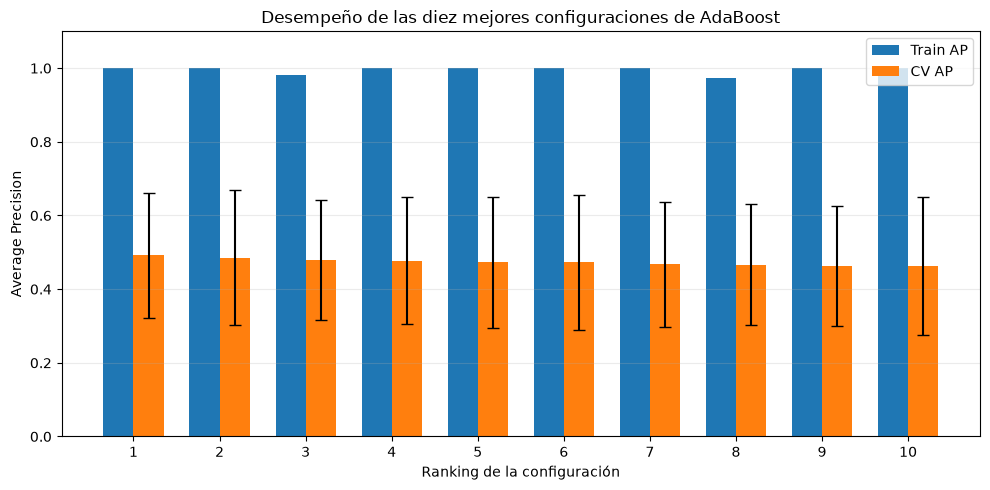

In [38]:
top10_adaboost_grafica = (
    resultados_cv_adaboost
    .sort_values("rank_test_score")
    .head(10)
    .copy()
)

ranks_adaboost = top10_adaboost_grafica["rank_test_score"].to_numpy()
ap_train_adaboost = top10_adaboost_grafica["mean_train_score"].to_numpy()
ap_cv_adaboost = top10_adaboost_grafica["mean_test_score"].to_numpy()
std_cv_adaboost = top10_adaboost_grafica["std_test_score"].to_numpy()

x = np.arange(len(ranks_adaboost))
ancho = 0.35

fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(
    x - ancho / 2,
    ap_train_adaboost,
    width=ancho,
    label="Train AP"
)

ax.bar(
    x + ancho / 2,
    ap_cv_adaboost,
    width=ancho,
    yerr=std_cv_adaboost,
    capsize=4,
    label="CV AP"
)

ax.set_xlabel("Ranking de la configuración")
ax.set_ylabel("Average Precision")
ax.set_title("Desempeño de las diez mejores configuraciones de AdaBoost")
ax.set_xticks(x)
ax.set_xticklabels(ranks_adaboost)
ax.set_ylim(0, 1.1)
ax.legend()
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

En la gráfica se observa que la brecha entre Train AP y CV AP se mantiene de forma consistente en las diez mejores configuraciones. Mientras el desempeño en entrenamiento permanece cercano a 1.0, el Average Precision de validación cruzada se mantiene aproximadamente entre 0.46 y 0.49.

Las barras de error muestran además una variabilidad considerable entre los folds. Este patrón confirma que el sobreajuste no depende de una sola combinación de hiperparámetros y respalda la decisión de no realizar una segunda búsqueda de optimización para AdaBoost.

## 12. Ensamble heterogéneo 1: Soft Voting

El primer ensamble heterogéneo combinará las probabilidades generadas por R(2+1)D-18/H5 y MC3-18/H5, los dos modelos individuales con mejor desempeño obtenidos en el Avance 4.

La combinación se realizará mediante Soft Voting uniforme, calculando el promedio de las probabilidades estimadas por ambos modelos. No se optimizarán pesos sobre `validation`, ya que utilizar esta misma partición para ajustar la combinación y posteriormente evaluarla produciría una estimación optimista del desempeño.

Esta configuración permite evaluar si la combinación de dos arquitecturas RGB con comportamientos diferentes mejora la capacidad de discriminación respecto al mejor modelo individual, manteniendo un procedimiento simple y sin parámetros adicionales ajustados sobre `validation`.

### 12.1 Recuperación y alineación de probabilidades

Soft Voting requiere que las probabilidades generadas por R(2+1)D-18/H5 y MC3-18/H5 correspondan exactamente a los mismos clips de `validation`. Por esta razón, las predicciones se almacenarán y alinearán mediante `clip_id` en lugar de asumir que el orden producido por los loaders es idéntico entre modelos.

A partir de los checkpoints validados del Avance 4 se generará un artefacto de predicciones que conservará `clip_id`, `grupo_experimental`, etiqueta real y las probabilidades de ocultamiento producidas por ambos modelos. Antes de utilizarlo se verificará que contenga las 136 observaciones esperadas, que no existan clips duplicados o faltantes, que las etiquetas y grupos correspondan con el dataset v2 y que todas las probabilidades sean finitas y se encuentren entre 0 y 1.

Este artefacto será la base común para Soft Voting y para los experimentos posteriores de Blending. Su generación no modifica los modelos ni utiliza las etiquetas de `validation` para ajustar parámetros.

In [39]:
PREDICCIONES_RGB_VAL_PATH = (
    ARTEFACTOS_DIR
    / "predicciones_rgb_h5_validation.csv"
)

PREDICCIONES_RGB_VAL_RESUMEN_PATH = (
    ARTEFACTOS_DIR
    / "predicciones_rgb_h5_validation_resumen.json"
)

print(PREDICCIONES_RGB_VAL_PATH.name)
print(PREDICCIONES_RGB_VAL_RESUMEN_PATH.name)

PREDICCIONES_R2_TEST_PATH = (
    ARTEFACTOS_DIR
    / "predicciones_r2plus1d_h5_test.csv"
)

PREDICCIONES_R2_TEST_RESUMEN_PATH = (
    ARTEFACTOS_DIR
    / "predicciones_r2plus1d_h5_test_resumen.json"
)

print(PREDICCIONES_R2_TEST_PATH.relative_to(REPO_DIR))
print(PREDICCIONES_R2_TEST_RESUMEN_PATH.relative_to(REPO_DIR))

predicciones_rgb_h5_validation.csv
predicciones_rgb_h5_validation_resumen.json
Datos/Preparacion_Datasets/avance5_artefactos/predicciones_r2plus1d_h5_test.csv
Datos/Preparacion_Datasets/avance5_artefactos/predicciones_r2plus1d_h5_test_resumen.json


In [40]:
CHECKPOINT_R2PLUS1D_H5_PATH = (
    REPO_DIR
    / "Notebooks"
    / "checkpoints"
    / "r2plus1d_18_avance4_h5.pt"
)

CHECKPOINT_MC3_H5_PATH = (
    REPO_DIR
    / "Notebooks"
    / "checkpoints"
    / "mc3_18_avance4_h5.pt"
)

print(
    "R(2+1)D-18/H5:",
    CHECKPOINT_R2PLUS1D_H5_PATH.exists()
)

print(
    "MC3-18/H5:",
    CHECKPOINT_MC3_H5_PATH.exists()
)

R(2+1)D-18/H5: True
MC3-18/H5: True


In [41]:
import importlib
import Scripts.artefactos_avance5 as artefactos_avance5

importlib.reload(artefactos_avance5)

try:
    validacion_predicciones_rgb = artefactos_avance5.validar_predicciones_rgb_validation(
        PREDICCIONES_RGB_VAL_PATH,
        PREDICCIONES_RGB_VAL_RESUMEN_PATH,
        df_val_v2,
        validar_avance5.SHA_DATASET_V2,
        CHECKPOINT_R2PLUS1D_H5_PATH,
        CHECKPOINT_MC3_H5_PATH
    )
    predicciones_rgb_validas = True
    error_predicciones_rgb = None

except (FileNotFoundError, ValueError, KeyError, RuntimeError, OSError) as exc:
    predicciones_rgb_validas = False
    error_predicciones_rgb = exc

print("Predicciones RGB válidas disponibles:", predicciones_rgb_validas)

if predicciones_rgb_validas:
    print(validacion_predicciones_rgb)

Predicciones RGB válidas disponibles: True
{'n_observaciones': 136, 'clips_unicos': 136, 'positivos': 30, 'p_r2plus1d_finitas': True, 'p_mc3_finitas': True, 'alineacion_dataset': True}


In [42]:
if predicciones_rgb_validas:
    transform_r2plus1d_h5 = None
    transform_mc3_h5 = None
    dataset_val_r2plus1d_h5 = None
    dataset_val_mc3_h5 = None
    loader_val_r2plus1d_h5 = None
    loader_val_mc3_h5 = None

    print(
        "Datasets y DataLoaders RGB no cargados. "
        "Se reutilizarán las predicciones existentes."
    )

else:
    if not GENERAR_ARTEFACTOS_A5:
        raise RuntimeError(
            "Las predicciones RGB no son válidas y "
            "GENERAR_ARTEFACTOS_A5=False."
        )

    ruta_clips_rgb = os.environ.get("BNEXT_CLIPS_DIR")

    if not ruta_clips_rgb:
        raise RuntimeError(
            "Defina BNEXT_CLIPS_DIR para regenerar las predicciones RGB."
        )

    CLIPS_DIR_RGB = Path(ruta_clips_rgb).expanduser().resolve()

    transform_r2plus1d_h5 = (
        video_models.R2Plus1D_18_Weights.DEFAULT.transforms()
    )

    transform_mc3_h5 = (
        video_models.MC3_18_Weights.DEFAULT.transforms()
    )

    dataset_val_r2plus1d_h5 = VideoDatasetRGB(
        df_val_v2,
        CLIPS_DIR_RGB,
        transform_r2plus1d_h5
    )

    dataset_val_mc3_h5 = VideoDatasetRGB(
        df_val_v2,
        CLIPS_DIR_RGB,
        transform_mc3_h5
    )

    loader_val_r2plus1d_h5 = DataLoader(
        dataset_val_r2plus1d_h5,
        batch_size=16,
        shuffle=False,
        num_workers=0,
        pin_memory=torch.cuda.is_available()
    )

    loader_val_mc3_h5 = DataLoader(
        dataset_val_mc3_h5,
        batch_size=16,
        shuffle=False,
        num_workers=0,
        pin_memory=torch.cuda.is_available()
    )

    print(
        "R(2+1)D-18/H5:",
        len(dataset_val_r2plus1d_h5),
        len(loader_val_r2plus1d_h5)
    )

    print(
        "MC3-18/H5:",
        len(dataset_val_mc3_h5),
        len(loader_val_mc3_h5)
    )

Datasets y DataLoaders RGB no cargados. Se reutilizarán las predicciones existentes.


In [43]:
if not predicciones_rgb_validas:
    import torch.nn as nn
    
    if not GENERAR_ARTEFACTOS_A5:
        raise RuntimeError(
            "Las predicciones RGB de validation no existen o son incompatibles. "
            "Active GENERAR_ARTEFACTOS_A5=True para generarlas."
        ) from error_predicciones_rgb

    checkpoint_r2plus1d_h5 = torch.load(
        CHECKPOINT_R2PLUS1D_H5_PATH,
        map_location="cpu",
        weights_only=False
    )

    checkpoint_mc3_h5 = torch.load(
        CHECKPOINT_MC3_H5_PATH,
        map_location="cpu",
        weights_only=False
    )

    modelo_r2plus1d_h5 = video_models.r2plus1d_18(weights=None)
    modelo_r2plus1d_h5.fc = nn.Linear(modelo_r2plus1d_h5.fc.in_features, 2)
    modelo_r2plus1d_h5.load_state_dict(checkpoint_r2plus1d_h5["model_state_dict"])
    modelo_r2plus1d_h5 = modelo_r2plus1d_h5.to(DEVICE).eval()

    modelo_mc3_h5 = video_models.mc3_18(weights=None)
    modelo_mc3_h5.fc = nn.Linear(modelo_mc3_h5.fc.in_features, 2)
    modelo_mc3_h5.load_state_dict(checkpoint_mc3_h5["model_state_dict"])
    modelo_mc3_h5 = modelo_mc3_h5.to(DEVICE).eval()

    resultado_r2plus1d_h5_val = artefactos_avance5.inferir_probabilidades_rgb(
        modelo_r2plus1d_h5,
        loader_val_r2plus1d_h5,
        DEVICE,
        usar_amp=True
    )

    resultado_mc3_h5_val = artefactos_avance5.inferir_probabilidades_rgb(
        modelo_mc3_h5,
        loader_val_mc3_h5,
        DEVICE,
        usar_amp=True
    )

    etiquetas_esperadas = df_val_v2["clase_binaria"].to_numpy(dtype=np.int64)

    if not np.array_equal(resultado_r2plus1d_h5_val["y_true"], etiquetas_esperadas):
        raise RuntimeError("Las etiquetas de R(2+1)D-18/H5 no coinciden con df_val_v2.")

    if not np.array_equal(resultado_mc3_h5_val["y_true"], etiquetas_esperadas):
        raise RuntimeError("Las etiquetas de MC3-18/H5 no coinciden con df_val_v2.")

    predicciones_rgb_val = df_val_v2[
        ["clip_id", "grupo_experimental"]
    ].reset_index(drop=True).copy()

    predicciones_rgb_val["label"] = etiquetas_esperadas
    predicciones_rgb_val["p_r2plus1d_h5"] = resultado_r2plus1d_h5_val["y_prob"]
    predicciones_rgb_val["p_mc3_h5"] = resultado_mc3_h5_val["y_prob"]


    resumen_predicciones_rgb = {
        "dataset_v2_sha256": validar_avance5.SHA_DATASET_V2,
        "split": "validation",
        "n_observaciones": len(predicciones_rgb_val),
        "checkpoint_r2plus1d_h5": CHECKPOINT_R2PLUS1D_H5_PATH.name,
        "checkpoint_r2plus1d_h5_sha256": validar_avance5.calcular_sha256(
            CHECKPOINT_R2PLUS1D_H5_PATH
        ),
        "checkpoint_mc3_h5": CHECKPOINT_MC3_H5_PATH.name,
        "checkpoint_mc3_h5_sha256": validar_avance5.calcular_sha256(
            CHECKPOINT_MC3_H5_PATH
        )
    }


    artefactos_avance5.guardar_predicciones_rgb_validation(
        PREDICCIONES_RGB_VAL_PATH,
        PREDICCIONES_RGB_VAL_RESUMEN_PATH,
        predicciones_rgb_val,
        resumen_predicciones_rgb
    )

    validacion_predicciones_rgb = artefactos_avance5.validar_predicciones_rgb_validation(
        PREDICCIONES_RGB_VAL_PATH,
        PREDICCIONES_RGB_VAL_RESUMEN_PATH,
        df_val_v2,
        validar_avance5.SHA_DATASET_V2
    )

    del modelo_r2plus1d_h5, modelo_mc3_h5
    del checkpoint_r2plus1d_h5, checkpoint_mc3_h5

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

else:
    predicciones_rgb_val, resumen_predicciones_rgb = (
        artefactos_avance5.cargar_predicciones_rgb_validation(
            PREDICCIONES_RGB_VAL_PATH,
            PREDICCIONES_RGB_VAL_RESUMEN_PATH
        )
    )

print("Predicciones RGB disponibles:", validacion_predicciones_rgb)

Predicciones RGB disponibles: {'n_observaciones': 136, 'clips_unicos': 136, 'positivos': 30, 'p_r2plus1d_finitas': True, 'p_mc3_finitas': True, 'alineacion_dataset': True}


### 12.2 Construcción del Soft Voting uniforme

El ensamble combina las probabilidades de R(2+1)D-18/H5 y MC3-18/H5 mediante un promedio aritmético:
$$
p_{\text{SoftVoting}}(x)=\frac{p_{\text{R(2+1)D}}(x)+p_{\text{MC3}}(x)}{2}
$$
Cada modelo recibe un peso de 0.5. Los pesos no se optimizan sobre `validation`, por lo que esta etapa no introduce parámetros adicionales ajustados con dicha partición. El objetivo es determinar si la combinación simple de las dos arquitecturas RGB reduce errores individuales y mejora la capacidad de discriminación respecto a los modelos que la componen.

In [44]:
predicciones_rgb_val["p_soft_voting"] = (
    predicciones_rgb_val["p_r2plus1d_h5"]
    + predicciones_rgb_val["p_mc3_h5"]
) / 2.0

prob_soft_voting_val = predicciones_rgb_val["p_soft_voting"].to_numpy(dtype=float)

assert len(prob_soft_voting_val) == 136
assert np.isfinite(prob_soft_voting_val).all()
assert ((prob_soft_voting_val >= 0) & (prob_soft_voting_val <= 1)).all()

print("Observaciones:", len(prob_soft_voting_val))
print("Probabilidades finitas:", np.isfinite(prob_soft_voting_val).all())
print("Rango válido:", ((prob_soft_voting_val >= 0) & (prob_soft_voting_val <= 1)).all())
print("Mínimo:", prob_soft_voting_val.min())
print("Máximo:", prob_soft_voting_val.max())

Observaciones: 136
Probabilidades finitas: True
Rango válido: True
Mínimo: 0.0010681949499999998
Máximo: 0.9999792599999999


In [45]:
y_val_soft_voting = predicciones_rgb_val["label"].to_numpy(dtype=np.int64)

ap_soft_voting_val = average_precision_score(
    y_val_soft_voting,
    prob_soft_voting_val
)

precision_soft_voting_val, recall_soft_voting_val, _ = precision_recall_curve(
    y_val_soft_voting,
    prob_soft_voting_val
)

pr_auc_soft_voting_val = auc(
    recall_soft_voting_val,
    precision_soft_voting_val
)

roc_auc_soft_voting_val = roc_auc_score(
    y_val_soft_voting,
    prob_soft_voting_val
)

fpr_soft_voting_val, tpr_soft_voting_val, _ = roc_curve(
    y_val_soft_voting,
    prob_soft_voting_val
)

fnr_soft_voting_val = 1 - tpr_soft_voting_val
indice_eer_soft_voting_val = np.nanargmin(
    np.abs(fpr_soft_voting_val - fnr_soft_voting_val)
)

eer_soft_voting_val = (
    fpr_soft_voting_val[indice_eer_soft_voting_val]
    + fnr_soft_voting_val[indice_eer_soft_voting_val]
) / 2

print("Average Precision:", round(ap_soft_voting_val, 4))
print("PR-AUC:", round(pr_auc_soft_voting_val, 4))
print("ROC-AUC:", round(roc_auc_soft_voting_val, 4))
print("EER:", round(eer_soft_voting_val, 4))

Average Precision: 0.7469
PR-AUC: 0.7437
ROC-AUC: 0.8591
EER: 0.1708


El Soft Voting obtuvo un Average Precision de 0.7469, por lo que no superó a R(2+1)D-18/H5, cuyo Average Precision reproducido en el Avance 5 fue de 0.7720. La diferencia entre ambos modelos es de aproximadamente 0.0251 puntos de AP, por lo que el ensamble se mantiene relativamente cercano al desempeño del mejor modelo individual.

El resultado más favorable del Soft Voting se observa en el EER, que disminuye de 0.2299 en R(2+1)D-18/H5 a 0.1708. Esto indica un mejor equilibrio entre las tasas de falsos positivos y falsos negativos en algún punto de operación.

Esta mejora en EER no es suficiente por sí sola para concluir que Soft Voting representa una alternativa superior. Para determinar su utilidad en el contexto de BNext será necesario analizar su matriz de confusión y las métricas dependientes del threshold, particularmente recall, specificity y precision.

In [46]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score

thresholds_soft_voting = np.unique(prob_soft_voting_val)

resultados_threshold_soft_voting = []

for threshold in thresholds_soft_voting:
    pred = (prob_soft_voting_val >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val_soft_voting,
        pred,
        labels=[0, 1]
    ).ravel()

    precision = precision_score(
        y_val_soft_voting,
        pred,
        zero_division=0
    )

    recall = recall_score(
        y_val_soft_voting,
        pred,
        zero_division=0
    )

    f1 = f1_score(
        y_val_soft_voting,
        pred,
        zero_division=0
    )

    specificity = tn / (tn + fp)

    resultados_threshold_soft_voting.append({
        "threshold": float(threshold),
        "f1": float(f1),
        "recall": float(recall),
        "precision": float(precision),
        "specificity": float(specificity),
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp)
    })

tabla_threshold_soft_voting = pd.DataFrame(
    resultados_threshold_soft_voting
).sort_values(
    ["f1", "recall", "precision"],
    ascending=[False, False, False]
).reset_index(drop=True)

mejor_threshold_soft_voting = tabla_threshold_soft_voting.iloc[0]

display(mejor_threshold_soft_voting.to_frame().T)

,threshold,f1,recall,precision,specificity,tn,fp,fn,tp
0,0.451761,0.695652,0.8,0.615385,0.858491,91.0,15.0,6.0,24.0


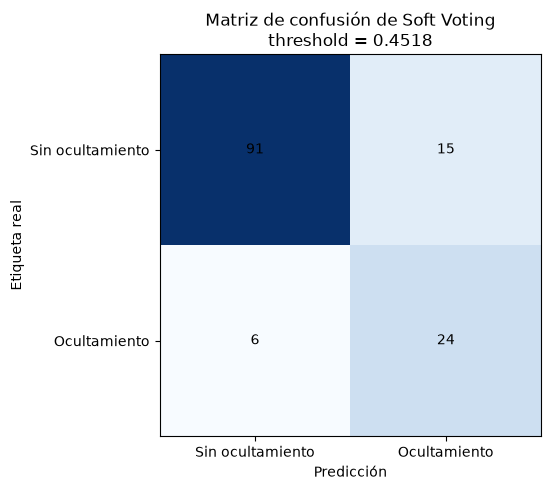

In [47]:
threshold_soft_voting = float(mejor_threshold_soft_voting["threshold"])
pred_soft_voting_val = (prob_soft_voting_val >= threshold_soft_voting).astype(int)

matriz_soft_voting = confusion_matrix(
    y_val_soft_voting,
    pred_soft_voting_val,
    labels=[0, 1]
)

fig, ax = plt.subplots(figsize=(6, 5))
imagen = ax.imshow(matriz_soft_voting, cmap="Blues")

for i in range(matriz_soft_voting.shape[0]):
    for j in range(matriz_soft_voting.shape[1]):
        ax.text(j, i, matriz_soft_voting[i, j], ha="center", va="center")

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(["Sin ocultamiento", "Ocultamiento"])
ax.set_yticklabels(["Sin ocultamiento", "Ocultamiento"])
ax.set_xlabel("Predicción")
ax.set_ylabel("Etiqueta real")
ax.set_title(f"Matriz de confusión de Soft Voting\nthreshold = {threshold_soft_voting:.4f}")

plt.tight_layout()
plt.show()

Con el threshold seleccionado de 0.4518, Soft Voting alcanza un recall de 0.8000. Esto representa una mejora en sensibilidad respecto al modelo individual de referencia, ya que identifica 24 de los 30 casos de ocultamiento presentes en `validation` y deja 6 falsos negativos. En términos prácticos, el modelo dejaría pasar aproximadamente dos ocultamientos de cada diez.

Sin embargo, esta mejora en recall está acompañada por 15 falsos positivos y una specificity de 0.8585. Para BNext este resultado representa una desventaja importante, ya que cada falsa alarma puede generar una revisión innecesaria por parte del personal de seguridad y, por lo tanto, un costo operativo asociado.

Considerando además que el Average Precision de Soft Voting fue 0.7469, inferior al 0.7720 reproducido para R(2+1)D-18/H5 en el Avance 5, los resultados no muestran una mejora suficiente para justificar por ahora la sustitución del modelo individual de referencia. Soft Voting incrementa la sensibilidad y reduce el EER, pero el control de falsos positivos continúa siendo un criterio relevante para la selección final del modelo.

### 12.3 Comparación mediante curvas Precision Recall

Para analizar el comportamiento de los modelos a través de distintos thresholds se comparan las curvas Precision Recall de R(2+1)D-18/H5, MC3-18/H5 y Soft Voting sobre la misma partición de `validation`.

Esta visualización permite determinar si el ensamble ofrece una ventaja consistente a lo largo de diferentes niveles de recall o si su desempeño favorable se concentra únicamente en determinados puntos de operación. La comparación complementa el Average Precision y ayuda a observar el compromiso entre detección de ocultamientos y generación de falsas alarmas.

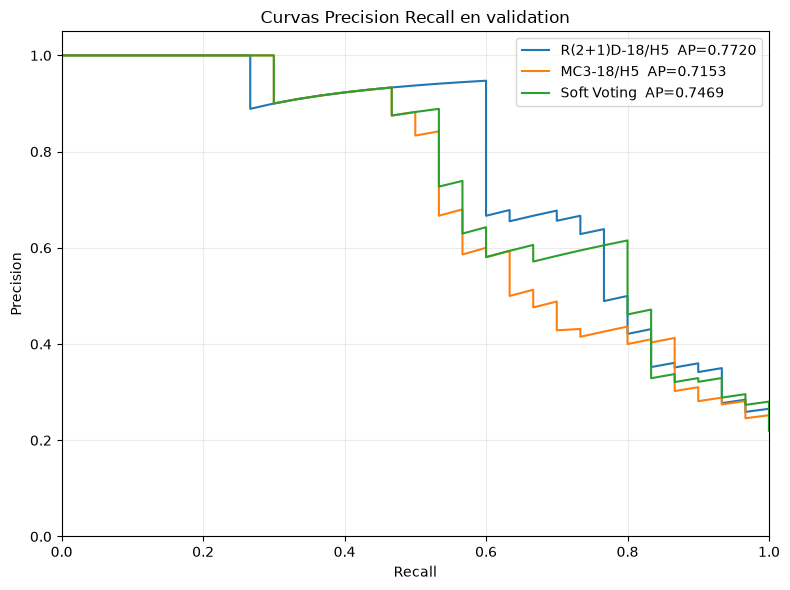

In [48]:
prob_r2plus1d_h5_val = predicciones_rgb_val["p_r2plus1d_h5"].to_numpy(dtype=float)
prob_mc3_h5_val = predicciones_rgb_val["p_mc3_h5"].to_numpy(dtype=float)

precision_r2, recall_r2, _ = precision_recall_curve(y_val_soft_voting, prob_r2plus1d_h5_val)
precision_mc3, recall_mc3, _ = precision_recall_curve(y_val_soft_voting, prob_mc3_h5_val)

ap_r2_curva = average_precision_score(y_val_soft_voting, prob_r2plus1d_h5_val)
ap_mc3_curva = average_precision_score(y_val_soft_voting, prob_mc3_h5_val)

fig, ax = plt.subplots(figsize=(8, 6))

ax.plot(recall_r2, precision_r2, label=f"R(2+1)D-18/H5  AP={ap_r2_curva:.4f}")
ax.plot(recall_mc3, precision_mc3, label=f"MC3-18/H5  AP={ap_mc3_curva:.4f}")
ax.plot(recall_soft_voting_val, precision_soft_voting_val, label=f"Soft Voting  AP={ap_soft_voting_val:.4f}")

ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Curvas Precision Recall en validation")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.05)
ax.grid(alpha=0.25)
ax.legend()

plt.tight_layout()
plt.show()

Las curvas Precision Recall muestran que ninguno de los tres modelos domina de forma consistente en todo el rango de recall. En la región de recall bajo y medio existen varios cruces y segmentos superpuestos entre R(2+1)D-18/H5, MC3-18/H5 y Soft Voting, por lo que la ventaja depende del punto de operación considerado.

Alrededor de un recall de 0.80, Soft Voting mantiene una precision superior a la de los dos modelos individuales. Este comportamiento es consistente con el punto de operación seleccionado, donde el ensamble alcanza un recall de 0.8000 y una precision de 0.6154.

Sin embargo, la ventaja observada en esta región no se mantiene a lo largo de toda la curva. Esto explica por qué el Average Precision global de Soft Voting, 0.7469, permanece por debajo del 0.7720 reproducido para R(2+1)D-18/H5 en el Avance 5. La diferencia es de aproximadamente 0.0251 puntos de AP. La gráfica confirma que el ensamble puede resultar favorable cuando se prioriza un recall elevado, aunque esta ventaja debe evaluarse junto con el aumento de falsos positivos observado en su matriz de confusión.

## 13. Ensamble heterogéneo 2: Blending

El segundo ensamble heterogéneo utilizará Blending para combinar las probabilidades producidas por R(2+1)D-18/H5 y MC3-18/H5. A diferencia de Soft Voting, donde ambos modelos reciben un peso fijo, Blending utilizará una regresión logística como meta-modelo para aprender la relación entre las probabilidades individuales y la clase objetivo.

Debido a que los checkpoints H5 fueron seleccionados previamente utilizando `validation`, entrenar y evaluar directamente el meta-modelo sobre toda esta partición produciría una estimación optimista. Para reducir este efecto, la evaluación principal del Blending se realizará mediante predicciones out-of-fold generadas con `StratifiedGroupKFold` dentro de `validation`.

La separación por `grupo_experimental` se conservará durante este procedimiento para evitar que clips relacionados aparezcan simultáneamente en los subconjuntos utilizados para ajustar y evaluar el meta-modelo. Una vez obtenida la evaluación out-of-fold, la regresión logística definitiva podrá ajustarse sobre todo `validation` para su posterior aplicación sobre `test`.

### 13.1 Control de reproducibilidad y ejecución

La implementación de Blending mantiene el mismo criterio de reproducibilidad utilizado en los demás ensambles del Avance 5. Las celdas se diseñan para ejecutarse secuencialmente desde un kernel limpio y sin depender de variables conservadas de ejecuciones anteriores.

Las operaciones que generan modelos o artefactos se mantienen protegidas mediante las banderas globales `GENERAR_MODELOS_A5` y `GENERAR_ARTEFACTOS_A5`. Cuando existe un artefacto compatible, este se valida y reutiliza. La regeneración solo se habilita de forma explícita.

Al finalizar esta sección se comprobará nuevamente la ejecución completa mediante `Restart Kernel + Run All` antes de continuar con la comparación final de modelos.

In [49]:
EPSILON_LOGIT = 1e-6

X_blend_prob_val = predicciones_rgb_val[
    ["p_r2plus1d_h5", "p_mc3_h5"]
].to_numpy(dtype=float)

X_blend_prob_segura_val = np.clip(
    X_blend_prob_val,
    EPSILON_LOGIT,
    1 - EPSILON_LOGIT
)

X_blend_val = np.log(
    X_blend_prob_segura_val
    / (1 - X_blend_prob_segura_val)
)

y_blend_val = predicciones_rgb_val[
    "label"
].to_numpy(dtype=np.int64)

grupos_blend_val = predicciones_rgb_val[
    "grupo_experimental"
].astype(str).to_numpy()

assert X_blend_val.shape == (136, 2)
assert len(y_blend_val) == 136
assert len(grupos_blend_val) == 136
assert np.isfinite(X_blend_val).all()

print("X_blend_val:", X_blend_val.shape)
print("Transformación de entrada: logit")
print("Grupos únicos:", np.unique(grupos_blend_val).size)
print("Positivos:", int(y_blend_val.sum()))
print(
    "Rango logits:",
    round(float(X_blend_val.min()), 4),
    round(float(X_blend_val.max()), 4)
)

X_blend_val: (136, 2)
Transformación de entrada: logit
Grupos únicos: 9
Positivos: 30
Rango logits: -7.7324 13.8155


In [50]:
BLEND_OOF_PATH = ARTEFACTOS_DIR / "blending_oof_validation.csv"
BLEND_MODELO_PATH = ARTEFACTOS_DIR / "blending_modelo.joblib"
BLEND_RESUMEN_PATH = ARTEFACTOS_DIR / "blending_resumen.json"

print("Predicciones OOF:", BLEND_OOF_PATH.name)
print("Meta-modelo:", BLEND_MODELO_PATH.name)
print("Resumen:", BLEND_RESUMEN_PATH.name)

Predicciones OOF: blending_oof_validation.csv
Meta-modelo: blending_modelo.joblib
Resumen: blending_resumen.json


In [51]:
artefactos_blend_existen = all(
    ruta.exists()
    for ruta in [
        BLEND_OOF_PATH,
        BLEND_MODELO_PATH,
        BLEND_RESUMEN_PATH
    ]
)

print("Artefactos de Blending disponibles:", artefactos_blend_existen)

Artefactos de Blending disponibles: True


In [52]:
try:
    validacion_blend = artefactos_avance5.validar_blending(
        BLEND_OOF_PATH,
        BLEND_MODELO_PATH,
        BLEND_RESUMEN_PATH,
        df_val_v2,
        validar_avance5.SHA_DATASET_V2,
        seed_esperado=SEED,
        n_splits_esperado=3
    )
    artefactos_blend_validos = True
    error_blend = None

except (FileNotFoundError, ValueError, KeyError, RuntimeError, OSError) as exc:
    artefactos_blend_validos = False
    validacion_blend = None
    error_blend = exc

print("Artefactos de Blending válidos:", artefactos_blend_validos)

if artefactos_blend_validos:
    print(validacion_blend)
else:
    print("Motivo:", error_blend)

Artefactos de Blending válidos: True
{'n_observaciones': 136, 'clips_unicos': 136, 'positivos': 30, 'folds': [np.int64(1), np.int64(2), np.int64(3)], 'probabilidades_finitas': True, 'modelo_n_features': 2, 'alineacion_dataset': True}


In [53]:
from sklearn.model_selection import StratifiedGroupKFold


cv_blend = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

distribucion_folds_blend = []

for fold, (idx_train, idx_val) in enumerate(
    cv_blend.split(
        X_blend_val,
        y_blend_val,
        groups=grupos_blend_val
    ),
    start=1
):
    grupos_train = set(grupos_blend_val[idx_train])
    grupos_val = set(grupos_blend_val[idx_val])

    assert grupos_train.isdisjoint(grupos_val)

    y_train_fold = y_blend_val[idx_train]
    y_val_fold = y_blend_val[idx_val]

    distribucion_folds_blend.append({
        "fold": fold,
        "train_total": len(idx_train),
        "train_positivos": int(y_train_fold.sum()),
        "train_negativos": int((y_train_fold == 0).sum()),
        "val_total": len(idx_val),
        "val_positivos": int(y_val_fold.sum()),
        "val_negativos": int((y_val_fold == 0).sum()),
        "grupos_train": len(grupos_train),
        "grupos_val": len(grupos_val),
        "val_prevalencia": float(y_val_fold.mean())
    })

display(pd.DataFrame(distribucion_folds_blend))

,fold,train_total,train_positivos,train_negativos,val_total,val_positivos,val_negativos,grupos_train,grupos_val,val_prevalencia
0,1,102,28,74,34,2,32,6,3,0.058824
1,2,104,28,76,32,2,30,8,1,0.062500
2,3,98,20,78,38,10,28,7,2,0.263158
3,4,119,19,100,17,11,6,8,1,0.647059
4,5,121,25,96,15,5,10,7,2,0.333333


In [54]:
cv_blend = StratifiedGroupKFold(
    n_splits=3,
    shuffle=True,
    random_state=SEED
)

distribucion_folds_blend = []

for fold, (idx_train, idx_val) in enumerate(
    cv_blend.split(
        X_blend_val,
        y_blend_val,
        groups=grupos_blend_val
    ),
    start=1
):
    grupos_train = set(grupos_blend_val[idx_train])
    grupos_val = set(grupos_blend_val[idx_val])

    assert grupos_train.isdisjoint(grupos_val)

    y_train_fold = y_blend_val[idx_train]
    y_val_fold = y_blend_val[idx_val]

    distribucion_folds_blend.append({
        "fold": fold,
        "train_total": len(idx_train),
        "train_positivos": int(y_train_fold.sum()),
        "train_negativos": int((y_train_fold == 0).sum()),
        "val_total": len(idx_val),
        "val_positivos": int(y_val_fold.sum()),
        "val_negativos": int((y_val_fold == 0).sum()),
        "grupos_train": len(grupos_train),
        "grupos_val": len(grupos_val),
        "val_prevalencia": float(y_val_fold.mean())
    })

display(pd.DataFrame(distribucion_folds_blend))

,fold,train_total,train_positivos,train_negativos,val_total,val_positivos,val_negativos,grupos_train,grupos_val,val_prevalencia
0,1,87,19,68,49,11,38,7,2,0.224490
1,2,85,18,67,51,12,39,5,4,0.235294
2,3,100,23,77,36,7,29,6,3,0.194444


### 13.2 Selección del número de folds para Blending

La evaluación del meta-modelo debe conservar la separación por `grupo_experimental`, por lo que se compararon configuraciones de `StratifiedGroupKFold` con 5 y 3 folds sobre los 136 clips de `validation`, que contienen 30 casos positivos distribuidos en 9 grupos experimentales.

Con 5 folds, aunque todos los subconjuntos conservaron ambas clases, la distribución resultó inestable. La prevalencia positiva en los folds de evaluación varió entre 5.9% y 64.7%. Además, dos folds quedaron formados por un solo grupo experimental y dos de ellos contenían únicamente 2 ejemplos positivos. En estas condiciones, la evaluación puede quedar fuertemente influida por las características particulares de uno o pocos grupos.

La configuración de 3 folds produjo una distribución más equilibrada. Los folds de evaluación contienen entre 2 y 4 grupos experimentales y entre 7 y 12 ejemplos positivos. Sus prevalencias positivas fueron 22.4%, 23.5% y 19.4%, valores cercanos a la prevalencia global de `validation`:
$$
\frac{30}{136} \approx 22.1\%
$$
Por esta razón se seleccionó `StratifiedGroupKFold` con 3 folds para generar las predicciones out-of-fold del Blending. Esta configuración mantiene separados los grupos experimentales y reduce la dependencia de folds con muy pocos casos positivos o dominados por un solo grupo.

### 13.3 Generación de predicciones out-of-fold y meta-modelo

El Blending utiliza una regresión logística como meta-modelo a partir de las salidas de R(2+1)D-18/H5 y MC3-18/H5. Antes del ajuste, las probabilidades de ambos modelos se transforman a escala logit mediante:
$$
\operatorname{logit}(p)=\log\left(\frac{p}{1-p}\right)
$$
Para evitar valores infinitos cuando una probabilidad es igual a 0 o 1, se aplica previamente un recorte numérico con $\epsilon=10^{-6}$. La transformación logit se utiliza como decisión de diseño debido a que las probabilidades producidas por los modelos base presentan valores concentrados cerca de los extremos 0 y 1. Al llevar estas probabilidades a una escala no acotada, se amplían las diferencias entre scores muy próximos a los extremos antes de utilizarlos como variables de entrada del meta-modelo. La regresión logística mantiene regularización L2, $C=0.1$ y `solver="liblinear"`.

La transformación logit se adoptó después de una exploración preliminar de alternativas de representación para las probabilidades de entrada realizada durante el desarrollo del experimento. Los resultados intermedios de esa exploración no se conservaron como artefactos comparables dentro del cuaderno. Por esta razón, el Average Precision OOF de 0.6812 debe interpretarse como el desempeño de la configuración finalmente seleccionada y puede contener cierto optimismo asociado con esta decisión de diseño tomada sobre la misma partición de `validation`.

Las probabilidades utilizadas para evaluar Blending se generan mediante el esquema `StratifiedGroupKFold` de 3 folds definido anteriormente. En cada fold, la regresión logística se ajusta exclusivamente con los grupos asignados al subconjunto de entrenamiento y produce probabilidades para los grupos reservados. De esta forma, cada observación recibe una predicción out-of-fold obtenida por un meta-modelo que no fue ajustado con esa observación.

Después de completar las predicciones out-of-fold, se ajusta un meta-modelo definitivo utilizando todo `validation`. Este último modelo no se utiliza para estimar el desempeño sobre `validation`, sino que se conserva como artefacto para su posterior evaluación sobre `test`.

La generación de estos artefactos está protegida mediante `GENERAR_MODELOS_A5`. En ejecuciones normales se reutilizan únicamente artefactos previamente validados.

In [55]:
import json
import joblib
import time

from sklearn.linear_model import LogisticRegression


if artefactos_blend_validos and not GENERAR_MODELOS_A5:
    oof_blend = pd.read_csv(BLEND_OOF_PATH)
    modelo_blend = joblib.load(BLEND_MODELO_PATH)

    with open(BLEND_RESUMEN_PATH, "r", encoding="utf-8") as archivo:
        resumen_blend = json.load(archivo)

    print("Artefactos de Blending recuperados y validados.")

elif GENERAR_MODELOS_A5:
    inicio_blend = time.perf_counter()

    prob_blend_oof = np.full(len(y_blend_val), np.nan, dtype=float)
    fold_blend_oof = np.zeros(len(y_blend_val), dtype=np.int64)

    for fold, (idx_train, idx_val) in enumerate(
        cv_blend.split(X_blend_val, y_blend_val, groups=grupos_blend_val),
        start=1
    ):
        grupos_train = set(grupos_blend_val[idx_train])
        grupos_val = set(grupos_blend_val[idx_val])

        assert grupos_train.isdisjoint(grupos_val)

        modelo_fold = LogisticRegression(
            C=0.1,
            l1_ratio=0.0,
            solver="liblinear",
            random_state=SEED
        )

        modelo_fold.fit(
            X_blend_val[idx_train],
            y_blend_val[idx_train]
        )

        prob_blend_oof[idx_val] = modelo_fold.predict_proba(
            X_blend_val[idx_val]
        )[:, 1]

        fold_blend_oof[idx_val] = fold

    assert np.isfinite(prob_blend_oof).all()
    assert set(fold_blend_oof) == {1, 2, 3}

    modelo_blend = LogisticRegression(
        C=0.1,
        l1_ratio=0.0,
        solver="liblinear",
        random_state=SEED
    )

    modelo_blend.fit(X_blend_val, y_blend_val)

    tiempo_blend = time.perf_counter() - inicio_blend

    oof_blend = predicciones_rgb_val[
        ["clip_id", "grupo_experimental", "label"]
    ].copy()

    oof_blend["fold"] = fold_blend_oof
    oof_blend["p_blending_oof"] = prob_blend_oof

    resumen_blend = {
        "dataset_v2_sha256": validar_avance5.SHA_DATASET_V2,
        "split": "validation",
        "seed": SEED,
        "n_splits": 3,
        "meta_modelo": "LogisticRegression",
        "C": 0.1,
        "regularizacion": "l2",
        "l1_ratio": 0.0,
        "solver": "liblinear",
        "variables_entrada": [
            "p_r2plus1d_h5",
            "p_mc3_h5"
        ],
        "transformacion_entrada": "logit",
        "epsilon_logit": EPSILON_LOGIT,
        "n_observaciones": len(oof_blend),
        "tiempo_entrenamiento_segundos": tiempo_blend
    }

    oof_blend.to_csv(BLEND_OOF_PATH, index=False)
    joblib.dump(modelo_blend, BLEND_MODELO_PATH)

    with open(BLEND_RESUMEN_PATH, "w", encoding="utf-8") as archivo:
        json.dump(resumen_blend, archivo, indent=2)

    validacion_blend = artefactos_avance5.validar_blending(
        BLEND_OOF_PATH,
        BLEND_MODELO_PATH,
        BLEND_RESUMEN_PATH,
        df_val_v2,
        validar_avance5.SHA_DATASET_V2,
        seed_esperado=SEED,
        n_splits_esperado=3
    )

    artefactos_blend_validos = True

    print("Artefactos de Blending generados y validados.")
    print(validacion_blend)
    print("Tiempo de entrenamiento:", round(tiempo_blend, 4), "s")

else:
    raise RuntimeError(
        "Los artefactos de Blending no existen o son incompatibles y "
        "GENERAR_MODELOS_A5=False."
    ) from error_blend

Artefactos de Blending recuperados y validados.


In [56]:
from sklearn.metrics import (
    auc,
    average_precision_score,
    precision_recall_curve,
    roc_auc_score,
    roc_curve
)

y_blend_oof = oof_blend["label"].to_numpy(dtype=np.int64)
prob_blend_oof = oof_blend["p_blending_oof"].to_numpy(dtype=float)

assert np.array_equal(y_blend_oof, y_blend_val)
assert np.isfinite(prob_blend_oof).all()
assert ((prob_blend_oof >= 0) & (prob_blend_oof <= 1)).all()

ap_blend_oof = average_precision_score(y_blend_oof, prob_blend_oof)

precision_blend_oof, recall_blend_oof, _ = precision_recall_curve(
    y_blend_oof,
    prob_blend_oof
)

pr_auc_blend_oof = auc(
    recall_blend_oof,
    precision_blend_oof
)

roc_auc_blend_oof = roc_auc_score(
    y_blend_oof,
    prob_blend_oof
)

fpr_blend_oof, tpr_blend_oof, _ = roc_curve(
    y_blend_oof,
    prob_blend_oof
)

fnr_blend_oof = 1 - tpr_blend_oof
indice_eer_blend_oof = np.nanargmin(
    np.abs(fpr_blend_oof - fnr_blend_oof)
)

eer_blend_oof = (
    fpr_blend_oof[indice_eer_blend_oof]
    + fnr_blend_oof[indice_eer_blend_oof]
) / 2

print("Average Precision OOF:", round(ap_blend_oof, 4))
print("PR-AUC OOF:", round(pr_auc_blend_oof, 4))
print("ROC-AUC OOF:", round(roc_auc_blend_oof, 4))
print("EER OOF:", round(eer_blend_oof, 4))

Average Precision OOF: 0.6812
PR-AUC OOF: 0.6783
ROC-AUC OOF: 0.7519
EER OOF: 0.3365


In [57]:
metricas_folds_blend = []

for fold in sorted(oof_blend["fold"].unique()):
    mascara = oof_blend["fold"] == fold

    y_fold = oof_blend.loc[mascara, "label"].to_numpy(dtype=np.int64)
    p_fold = oof_blend.loc[mascara, "p_blending_oof"].to_numpy(dtype=float)

    metricas_folds_blend.append({
        "fold": int(fold),
        "n": int(mascara.sum()),
        "positivos": int(y_fold.sum()),
        "prevalencia": float(y_fold.mean()),
        "average_precision": average_precision_score(y_fold, p_fold),
        "roc_auc": roc_auc_score(y_fold, p_fold)
    })

display(pd.DataFrame(metricas_folds_blend))

,fold,n,positivos,prevalencia,average_precision,roc_auc
0,1,49,11,0.224490,0.953604,0.988038
1,2,51,12,0.235294,0.658629,0.786325
2,3,36,7,0.194444,0.919643,0.955665


In [58]:
resumen_prob_blend_folds = (
    oof_blend
    .groupby(["fold", "label"])["p_blending_oof"]
    .agg(["count", "min", "mean", "median", "max"])
    .reset_index()
)

display(resumen_prob_blend_folds)

,fold,label,count,min,mean,median,max
0,1,0,38,0.061431,0.222488,0.175089,0.941937
1,1,1,11,0.841954,0.928770,0.971157,0.990016
2,2,0,39,0.007096,0.039321,0.034803,0.135290
3,2,1,12,0.018586,0.100928,0.089919,0.267268
4,3,0,29,0.090501,0.337856,0.250158,0.840479
5,3,1,7,0.451683,0.865679,0.936641,0.980773


### 13.4 Evaluación de Blending en validation

Para examinar por qué el desempeño agregado del Blending es considerablemente menor que el observado dentro de cada fold, se comparan las distribuciones de las probabilidades OOF según fold y clase. Esta visualización permite identificar posibles diferencias de escala entre los meta-modelos ajustados en cada partición.

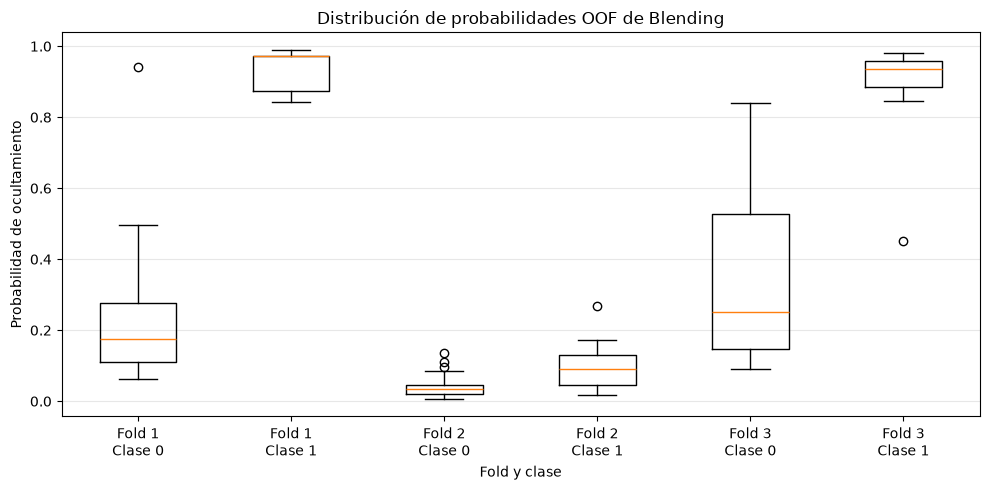

In [59]:
import matplotlib.pyplot as plt

datos_boxplot = []
etiquetas_boxplot = []

for fold in [1, 2, 3]:
    for label in [0, 1]:
        mascara = (
            (oof_blend["fold"] == fold)
            & (oof_blend["label"] == label)
        )

        datos_boxplot.append(
            oof_blend.loc[mascara, "p_blending_oof"].to_numpy(dtype=float)
        )

        etiquetas_boxplot.append(
            f"Fold {fold}\nClase {label}"
        )

plt.figure(figsize=(10, 5))
plt.boxplot(datos_boxplot, tick_labels=etiquetas_boxplot)
plt.ylabel("Probabilidad de ocultamiento")
plt.xlabel("Fold y clase")
plt.title("Distribución de probabilidades OOF de Blending")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

La distribución de las probabilidades OOF muestra una separación clara entre las clases `sin_ocultamiento` y `ocultamiento` en los folds 1 y 3. Esto es consistente con sus valores de Average Precision de 0.9536 y 0.9196, respectivamente. En el fold 2 existe un mayor solapamiento entre ambas clases y su Average Precision disminuye a 0.6586.

También se observan diferencias importantes en la escala de las probabilidades entre folds. La probabilidad media de los casos de `ocultamiento` es 0.9288 en el fold 1, 0.1009 en el fold 2 y 0.8657 en el fold 3. En consecuencia, algunos casos positivos del fold 2 reciben probabilidades inferiores a casos negativos pertenecientes a los otros folds.

Con la transformación logit, el Average Precision OOF agregado obtenido por Blending es 0.6812. Las distribuciones muestran que persisten diferencias importantes de escala entre los meta-modelos entrenados en cada fold. Este comportamiento es consistente con la existencia de inversiones de ranking cuando se combinan todas las predicciones OOF y ayuda a explicar por qué el desempeño agregado es inferior al observado individualmente en los folds 1 y 3.

### 13.5 Selección del punto de operación

La capacidad de discriminación del Blending se compara con los dos modelos RGB que lo componen y con Soft Voting. Debido al desbalance entre las clases, la curva Precision-Recall permite observar cómo cambia la precisión conforme se incrementa la proporción de casos de ocultamiento recuperados.

Para Blending se utilizan exclusivamente las predicciones out-of-fold, evitando evaluar sobre `validation` el meta-modelo definitivo que fue ajustado con toda esta partición.

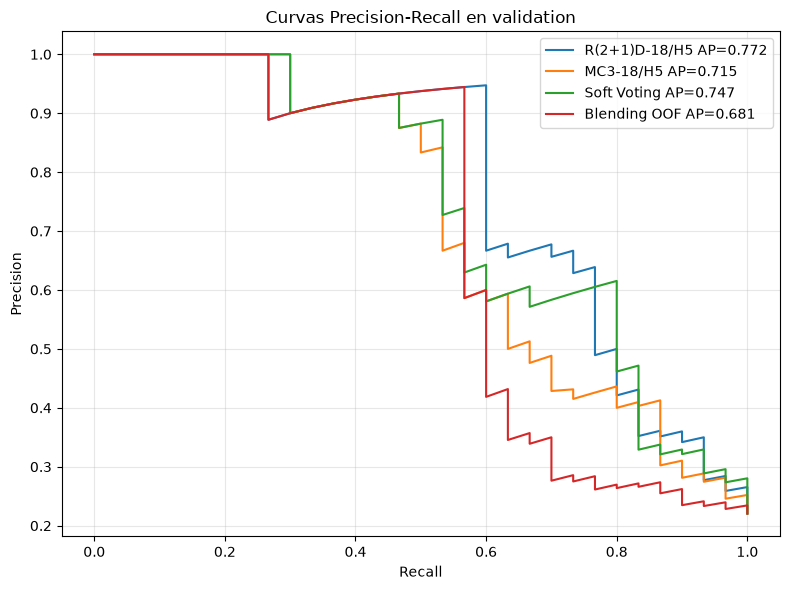

In [60]:
y_val_comparacion = predicciones_rgb_val["label"].to_numpy(dtype=np.int64)

prob_r2plus1d_val = predicciones_rgb_val["p_r2plus1d_h5"].to_numpy(dtype=float)
prob_mc3_val = predicciones_rgb_val["p_mc3_h5"].to_numpy(dtype=float)

precision_r2, recall_r2, _ = precision_recall_curve(
    y_val_comparacion,
    prob_r2plus1d_val
)

precision_mc3, recall_mc3, _ = precision_recall_curve(
    y_val_comparacion,
    prob_mc3_val
)

precision_soft, recall_soft, _ = precision_recall_curve(
    y_val_comparacion,
    prob_soft_voting_val
)

precision_blend, recall_blend, _ = precision_recall_curve(
    y_blend_oof,
    prob_blend_oof
)

plt.figure(figsize=(8, 6))

plt.plot(
    recall_r2,
    precision_r2,
    label=f"R(2+1)D-18/H5 AP={average_precision_score(y_val_comparacion, prob_r2plus1d_val):.3f}"
)

plt.plot(
    recall_mc3,
    precision_mc3,
    label=f"MC3-18/H5 AP={average_precision_score(y_val_comparacion, prob_mc3_val):.3f}"
)

plt.plot(
    recall_soft,
    precision_soft,
    label=f"Soft Voting AP={ap_soft_voting_val:.3f}"
)

plt.plot(
    recall_blend,
    precision_blend,
    label=f"Blending OOF AP={ap_blend_oof:.3f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Curvas Precision-Recall en validation")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

La curva Precision-Recall de Blending se construye utilizando exclusivamente las predicciones out-of-fold del meta-modelo. Con la configuración definitiva, que emplea la transformación logit de las probabilidades producidas por R(2+1)D-18/H5 y MC3-18/H5, Blending alcanza un Average Precision OOF de 0.6812 y un PR-AUC de 0.6783.

El desempeño global permanece por debajo de R(2+1)D-18/H5, con un Average Precision de 0.7720, y de Soft Voting, con 0.7469. Por lo tanto, los resultados obtenidos en `validation` no muestran una ventaja suficiente para seleccionar Blending frente a las alternativas con mejor desempeño.

La comparación debe interpretarse con cautela porque Blending se evalúa mediante predicciones out-of-fold, mientras que las probabilidades de los modelos RGB base y de Soft Voting corresponden a su evaluación directa sobre `validation`. Esta diferencia metodológica limita una comparación completamente simétrica, aunque el procedimiento out-of-fold permite estimar el desempeño del meta-modelo sin ajustarlo sobre las mismas observaciones que se utilizan para evaluarlo.

In [61]:
from sklearn.metrics import confusion_matrix, f1_score, precision_score, recall_score

resultados_umbral_blend = []

for umbral in np.unique(prob_blend_oof):
    pred = (prob_blend_oof >= umbral).astype(np.int64)

    tn, fp, fn, tp = confusion_matrix(
        y_blend_oof,
        pred,
        labels=[0, 1]
    ).ravel()

    resultados_umbral_blend.append({
        "umbral": float(umbral),
        "precision": precision_score(y_blend_oof, pred, zero_division=0),
        "recall": recall_score(y_blend_oof, pred, zero_division=0),
        "f1": f1_score(y_blend_oof, pred, zero_division=0),
        "specificity": tn / (tn + fp),
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp)
    })

tabla_umbral_blend = (
    pd.DataFrame(resultados_umbral_blend)
    .sort_values(
        ["f1", "recall", "precision"],
        ascending=False
    )
    .reset_index(drop=True)
)

mejor_umbral_blend = tabla_umbral_blend.iloc[0]

display(tabla_umbral_blend.head(10))

print("Umbral seleccionado:", round(mejor_umbral_blend["umbral"], 6))
print("F1:", round(mejor_umbral_blend["f1"], 4))
print("Recall:", round(mejor_umbral_blend["recall"], 4))
print("Precision:", round(mejor_umbral_blend["precision"], 4))
print("Specificity:", round(mejor_umbral_blend["specificity"], 4))
print(
    "TN:", int(mejor_umbral_blend["tn"]),
    "FP:", int(mejor_umbral_blend["fp"]),
    "FN:", int(mejor_umbral_blend["fn"]),
    "TP:", int(mejor_umbral_blend["tp"])
)

,umbral,precision,recall,f1,specificity,tn,fp,fn,tp
0,0.841954,0.944444,0.566667,0.708333,0.990566,105,1,13,17
1,0.840479,0.894737,0.566667,0.693878,0.981132,104,2,13,17
2,0.845125,0.941176,0.533333,0.680851,0.990566,105,1,14,16
3,0.771960,0.850000,0.566667,0.680000,0.971698,103,3,13,17
4,0.725733,0.809524,0.566667,0.666667,0.962264,102,4,13,17
5,0.688517,0.772727,0.566667,0.653846,0.952830,101,5,13,17
6,0.849471,0.937500,0.500000,0.652174,0.990566,105,1,15,15
7,0.644099,0.739130,0.566667,0.641509,0.943396,100,6,13,17
8,0.598731,0.708333,0.566667,0.629630,0.933962,99,7,13,17
9,0.849646,0.933333,0.466667,0.622222,0.990566,105,1,16,14


Umbral seleccionado: 0.841954
F1: 0.7083
Recall: 0.5667
Precision: 0.9444
Specificity: 0.9906
TN: 105 FP: 1 FN: 13 TP: 17


### 13.6 Conclusión del experimento de Blending

La configuración definitiva de Blending, utilizando la transformación logit de las probabilidades de R(2+1)D-18/H5 y MC3-18/H5, obtuvo un Average Precision OOF de 0.6812 y un PR-AUC de 0.6783. Estos valores corresponden a la configuración finalmente seleccionada después de la exploración metodológica descrita anteriormente, por lo que deben interpretarse considerando el posible optimismo asociado con decisiones de diseño tomadas sobre la misma partición de `validation`.

En el punto de operación seleccionado, Blending alcanzó un F1 de 0.7083, precision de 0.9444, recall de 0.5667 y specificity de 0.9906. La matriz de confusión correspondiente contiene 1 falso positivo y 13 falsos negativos. Este comportamiento produce pocas falsas alarmas, aunque deja sin detectar una proporción mayor de casos de ocultamiento que Soft Voting.

El análisis por fold mostró además diferencias importantes en la escala de las probabilidades producidas por los meta-modelos. Los folds 1 y 3 presentaron una separación considerablemente mayor que el fold 2, y al combinar las predicciones OOF persistieron inversiones de ranking entre observaciones pertenecientes a folds diferentes. Esta variabilidad limita el desempeño agregado del ensamble.

Blending se conserva en la comparación global de los cuatro ensambles evaluados, pero su Average Precision permanece por debajo de R(2+1)D-18/H5 y Soft Voting. Por ello, los resultados obtenidos no proporcionan evidencia suficiente para seleccionarlo como candidato principal para la evaluación final sobre `test`.

## 14. Comparación global en validation y selección del modelo candidato

Una vez evaluados los cuatro ensambles, se comparan sus resultados con R(2+1)D-18/H5, seleccionado en el Avance 4 como el mejor modelo individual. Esta comparación se realiza utilizando exclusivamente resultados de `validation`, con el propósito de seleccionar el modelo que avanzará a la evaluación final sobre `test`.

Average Precision se mantiene como métrica principal debido al desbalance entre las clases. La comparación incorpora también PR-AUC, ROC-AUC, F1, recall, precision, specificity y tiempo de entrenamiento, ya que el desempeño del sistema debe considerar tanto la capacidad de detectar ocultamientos como la generación de falsas alarmas.

Los resultados de Blending corresponden a predicciones out-of-fold del meta-modelo, mientras que los demás modelos utilizan sus predicciones sobre `validation`. Esta diferencia metodológica se conservará explícita al interpretar la tabla y limita una comparación completamente simétrica entre sus métricas.

In [62]:

#y_comparacion = predicciones_rgb_val["label"].to_numpy(dtype=np.int64)
#prob_r2_comparacion = predicciones_rgb_val["p_r2plus1d_h5"].to_numpy(dtype=float)


y_comparacion = predicciones_rgb_val["label"].to_numpy(dtype=np.int64)
prob_r2_comparacion = predicciones_rgb_val[
    "p_r2plus1d_h5"
].to_numpy(dtype=float)

resultados_threshold_r2 = []

for threshold in np.unique(prob_r2_comparacion):
    pred = (
        prob_r2_comparacion >= threshold
    ).astype(np.int64)

    tn, fp, fn, tp = confusion_matrix(
        y_comparacion,
        pred,
        labels=[0, 1]
    ).ravel()

    resultados_threshold_r2.append({
        "threshold": threshold,
        "f1": f1_score(
            y_comparacion,
            pred,
            zero_division=0
        ),
        "recall": recall_score(
            y_comparacion,
            pred,
            zero_division=0
        ),
        "precision": precision_score(
            y_comparacion,
            pred,
            zero_division=0
        ),
        "specificity": tn / (tn + fp),
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp)
    })

tabla_threshold_r2 = pd.DataFrame(
    resultados_threshold_r2
)

mejor_threshold_r2 = (
    tabla_threshold_r2
    .sort_values(
        ["f1", "recall", "precision"],
        ascending=False
    )
    .iloc[0]
)

THRESHOLD_R2PLUS1D_H5 = float(
    mejor_threshold_r2["threshold"]
)

print(
    "Threshold R(2+1)D-18/H5 seleccionado en validation:",
    THRESHOLD_R2PLUS1D_H5
)


ap_r2_comparacion = average_precision_score(y_comparacion, prob_r2_comparacion)

precision_pr_r2, recall_pr_r2, _ = precision_recall_curve(
    y_comparacion,
    prob_r2_comparacion
)

pr_auc_r2_comparacion = auc(recall_pr_r2, precision_pr_r2)
roc_auc_r2_comparacion = roc_auc_score(y_comparacion, prob_r2_comparacion)

fpr_r2, tpr_r2, _ = roc_curve(y_comparacion, prob_r2_comparacion)
fnr_r2 = 1 - tpr_r2
indice_eer_r2 = np.nanargmin(np.abs(fpr_r2 - fnr_r2))
eer_r2_comparacion = (fpr_r2[indice_eer_r2] + fnr_r2[indice_eer_r2]) / 2

pred_r2_comparacion = (
    prob_r2_comparacion >= THRESHOLD_R2PLUS1D_H5
).astype(np.int64)

tn_r2, fp_r2, fn_r2, tp_r2 = confusion_matrix(
    y_comparacion,
    pred_r2_comparacion,
    labels=[0, 1]
).ravel()

precision_r2_operacion = precision_score(
    y_comparacion,
    pred_r2_comparacion,
    zero_division=0
)

recall_r2_operacion = recall_score(
    y_comparacion,
    pred_r2_comparacion,
    zero_division=0
)

f1_r2_operacion = f1_score(
    y_comparacion,
    pred_r2_comparacion,
    zero_division=0
)

specificity_r2_operacion = tn_r2 / (tn_r2 + fp_r2)

HISTORIAL_R2_H5_PATH = CHECKPOINT_R2PLUS1D_H5_PATH.with_name(
    "r2plus1d_18_avance4_h5_history.csv"
)

df_historial_r2_h5 = pd.read_csv(HISTORIAL_R2_H5_PATH)
tiempo_r2_h5_s = float(df_historial_r2_h5["tiempo_epoca_s"].sum())

tiempo_rf_total_s = (
    resumen_rf["tiempo_busqueda_s"]
    + resumen_rf["tiempo_refit_s"]
)

tiempo_adaboost_total_s = (
    resumen_adaboost["tiempo_busqueda_s"]
    + resumen_adaboost["tiempo_refit_s"]
)

tiempo_blend_total_s = resumen_blend["tiempo_entrenamiento_segundos"]

tabla_comparacion_modelos = pd.DataFrame([
    {
        "modelo": "R(2+1)D-18/H5",
        "tipo": "Individual",
        "AP": ap_r2_comparacion,
        "PR-AUC": pr_auc_r2_comparacion,
        "ROC-AUC": roc_auc_r2_comparacion,
        "EER": eer_r2_comparacion,
        "F1": f1_r2_operacion,
        "recall": recall_r2_operacion,
        "precision": precision_r2_operacion,
        "specificity": specificity_r2_operacion,
        "FP": int(fp_r2),
        "FN": int(fn_r2),
        "tiempo_entrenamiento_seleccion_s": tiempo_r2_h5_s
    },
    {
        "modelo": "Random Forest",
        "tipo": "Homogéneo",
        "AP": ap_rf_val,
        "PR-AUC": pr_auc_rf_val,
        "ROC-AUC": roc_auc_rf_val,
        "EER": eer_rf_val,
        "F1": mejor_threshold_rf["f1"],
        "recall": mejor_threshold_rf["recall"],
        "precision": mejor_threshold_rf["precision"],
        "specificity": mejor_threshold_rf["specificity"],
        "FP": int(mejor_threshold_rf["fp"]),
        "FN": int(mejor_threshold_rf["fn"]),
        "tiempo_entrenamiento_seleccion_s": tiempo_rf_total_s
    },
    {
        "modelo": "AdaBoost",
        "tipo": "Homogéneo",
        "AP": ap_adaboost_val,
        "PR-AUC": pr_auc_adaboost_val,
        "ROC-AUC": roc_auc_adaboost_val,
        "EER": eer_adaboost_val,
        "F1": mejor_threshold_adaboost["f1"],
        "recall": mejor_threshold_adaboost["recall"],
        "precision": mejor_threshold_adaboost["precision"],
        "specificity": mejor_threshold_adaboost["specificity"],
        "FP": int(mejor_threshold_adaboost["fp"]),
        "FN": int(mejor_threshold_adaboost["fn"]),
        "tiempo_entrenamiento_seleccion_s": tiempo_adaboost_total_s
    },
    {
        "modelo": "Soft Voting",
        "tipo": "Heterogéneo",
        "AP": ap_soft_voting_val,
        "PR-AUC": pr_auc_soft_voting_val,
        "ROC-AUC": roc_auc_soft_voting_val,
        "EER": eer_soft_voting_val,
        "F1": mejor_threshold_soft_voting["f1"],
        "recall": mejor_threshold_soft_voting["recall"],
        "precision": mejor_threshold_soft_voting["precision"],
        "specificity": mejor_threshold_soft_voting["specificity"],
        "FP": int(mejor_threshold_soft_voting["fp"]),
        "FN": int(mejor_threshold_soft_voting["fn"]),
        "tiempo_entrenamiento_seleccion_s": 0.0
    },
    {
        "modelo": "Blending",
        "tipo": "Heterogéneo OOF",
        "AP": ap_blend_oof,
        "PR-AUC": pr_auc_blend_oof,
        "ROC-AUC": roc_auc_blend_oof,
        "EER": eer_blend_oof,
        "F1": mejor_umbral_blend["f1"],
        "recall": mejor_umbral_blend["recall"],
        "precision": mejor_umbral_blend["precision"],
        "specificity": mejor_umbral_blend["specificity"],
        "FP": int(mejor_umbral_blend["fp"]),
        "FN": int(mejor_umbral_blend["fn"]),
        "tiempo_entrenamiento_seleccion_s": tiempo_blend_total_s
    }
])

tabla_comparacion_modelos = (
    tabla_comparacion_modelos
    .sort_values("AP", ascending=False)
    .reset_index(drop=True)
)

display(
    tabla_comparacion_modelos.style.format({
        "AP": "{:.4f}",
        "PR-AUC": "{:.4f}",
        "ROC-AUC": "{:.4f}",
        "EER": "{:.4f}",
        "F1": "{:.4f}",
        "recall": "{:.4f}",
        "precision": "{:.4f}",
        "specificity": "{:.4f}",
        "tiempo_entrenamiento_seleccion_s": "{:.4f}"
    })
)

Threshold R(2+1)D-18/H5 seleccionado en validation: 0.99690056


,modelo,tipo,AP,PR-AUC,ROC-AUC,EER,F1,recall,precision,specificity,FP,FN,tiempo_entrenamiento_seleccion_s
0,R(2+1)D-18/H5,Individual,0.7720,0.7692,0.8673,0.2299,0.7347,0.6000,0.9474,0.9906,1,12,3983.1382
1,Soft Voting,Heterogéneo,0.7469,0.7437,0.8591,0.1708,0.6957,0.8000,0.6154,0.8585,15,6,0.0000
2,Blending,Heterogéneo OOF,0.6812,0.6783,0.7519,0.3365,0.7083,0.5667,0.9444,0.9906,1,13,0.0398
3,AdaBoost,Homogéneo,0.5538,0.5442,0.7698,0.2654,0.5542,0.7667,0.4340,0.7170,30,7,201.3734
4,Random Forest,Homogéneo,0.5164,0.4959,0.7519,0.2821,0.5455,0.5000,0.6000,0.9057,10,15,98.8159


La comparación global en `validation` muestra que R(2+1)D-18/H5 obtiene el mejor desempeño de acuerdo con Average Precision, definida como la métrica principal del proyecto, con un AP de 0.7720. También alcanza el F1 más alto, de 0.7347, una precision de 0.9474 y una specificity de 0.9906. En su punto de operación seleccionado produce 1 falso positivo y 12 falsos negativos.

Soft Voting obtiene un AP ligeramente menor, de 0.7469, pero incrementa el recall de 0.6000 a 0.8000. Esto permite detectar una mayor proporción de los casos de ocultamiento presentes en `validation`, reduciendo los falsos negativos de 12 a 6. Sin embargo, esta mejora se acompaña de una reducción de la precision a 0.6154 y de la specificity a 0.8585, además de un incremento de los falsos positivos de 1 a 15.

Para el contexto de BNext, los falsos positivos representan un criterio operativo especialmente relevante. Un número elevado de falsas alertas implicaría más tiempo de revisión para el personal de seguridad y podría generar intervenciones innecesarias, con costos operativos y posibles efectos sobre la experiencia del cliente y la reputación de la tienda. Por esta razón, el incremento de recall obtenido por Soft Voting no compensa suficientemente el aumento de falsas alarmas observado en esta partición.

Considerando conjuntamente el mejor Average Precision, el mayor F1, la alta precision y el control de falsos positivos, se mantiene R(2+1)D-18/H5 como candidato para la evaluación final sobre `test`. La decisión refleja el compromiso buscado entre detectar posibles ocultamientos y mantener un volumen manejable de alertas para revisión humana.

Como criterio complementario se comparó el costo de inferencia de R(2+1)D-18/H5 y Soft Voting mediante una medición controlada del `forward pass` en GPU, con batch de 16 clips y precisión mixta habilitada. R(2+1)D-18/H5 requirió 17.83 ms por clip y alcanzó 56.09 clips/s, mientras que Soft Voting, al ejecutar R(2+1)D-18/H5 y MC3-18/H5, requirió 29.38 ms por clip y alcanzó 34.04 clips/s. Esto representa aproximadamente 1.65 veces el tiempo de cómputo del modelo individual. El mayor costo refuerza la decisión de no seleccionar Soft Voting, ya que su aumento de recall viene acompañado por un incremento importante de falsos positivos y por una mayor demanda computacional. Esta medición considera únicamente el `forward pass` de los modelos y excluye lectura de video, decodificación y preprocesamiento, por lo que se utiliza para comparar arquitecturas bajo condiciones controladas y no como una estimación de latencia completa en producción.

**Nota sobre los tiempos reportados.** Los tiempos de entrenamiento y selección no representan procesos directamente equivalentes entre arquitecturas. Para R(2+1)D-18/H5 se reporta el tiempo acumulado de entrenamiento del experimento H5. Para Random Forest y AdaBoost se incluye la búsqueda de hiperparámetros y el ajuste final sobre embeddings previamente generados. En Blending se reporta el tiempo de entrenamiento del meta-modelo logístico. Soft Voting se registra con 0 s de entrenamiento adicional porque no ajusta parámetros nuevos, sino que combina las probabilidades previamente obtenidas por R(2+1)D-18 y MC3-18. Este valor no incluye el costo de entrenamiento ni de inferencia de los modelos base. Por estas diferencias, los tiempos se utilizan como referencia del costo experimental y no como una comparación directa de velocidad entre arquitecturas.

### Nota sobre la reproducibilidad del AP de R(2+1)D-18/H5

En el Avance 4 se registró para R(2+1)D-18/H5 un Average Precision de 0.7554 en `validation`. Al reevaluar en el Avance 5 el checkpoint actualmente disponible sobre la misma partición de 136 clips, se obtiene de forma reproducible un AP de 0.7720.

Como verificación adicional, se repitió la inferencia sobre `validation` con precisión mixta desactivada (`AMP=False`). El resultado permaneció en 0.7720, por lo que el uso de AMP no explica la diferencia respecto al valor histórico.

También se identificó una discrepancia en `test`. En el Avance 4 se registró un AP de 0.7551, mientras que las predicciones actuales producen un AP de 0.8041. Sin embargo, el comportamiento en el punto de operación permanece igual en términos de clasificación: se obtienen 116 verdaderos negativos, 3 falsos positivos, 6 falsos negativos y 11 verdaderos positivos, con precision de 0.7857, recall de 0.6471 y specificity de 0.9748. Esto muestra que la discrepancia afecta principalmente al ranking de los scores y no a las decisiones binarias observadas alrededor del threshold utilizado.

Se revisó además la distribución numérica de las predicciones actuales de `test`. De los 136 scores, 135 son únicos, ninguno es exactamente igual a 1.0 y únicamente dos observaciones comparten el mismo valor. Aunque existen probabilidades muy próximas a 1.0, los resultados actuales no muestran una acumulación de empates que permita atribuir la diferencia de AP a este factor.

Como comprobación parcial, se compararon los scores actuales con los valores documentados en el Avance 4 para ocho de los nueve errores finales que contaban con una probabilidad numérica explícita. Las diferencias observadas fueron del orden de $10^{-4}$, por lo que esos casos conservan valores muy similares. El noveno caso había sido reportado únicamente como aproximadamente 1.0000 y no permite una comparación con mayor precisión.

No fue posible determinar la causa exacta de las discrepancias de AP. El Avance 4 no conserva el vector completo de predicciones de R(2+1)D-18/H5 ni el hash del archivo de checkpoint utilizado al momento de registrar los resultados originales, por lo que no puede reconstruirse completamente el ranking histórico ni demostrarse que ambos checkpoints sean binariamente idénticos. La saturación de algunos scores cerca de 1.0 podría hacer que pequeñas variaciones numéricas alteren el ranking, pero con la evidencia disponible esta posibilidad se mantiene únicamente como hipótesis.

Para las comparaciones del Avance 5 se utilizan los valores reproducibles obtenidos con los artefactos actuales: AP de 0.7720 en `validation` y 0.8041 en `test`. Los valores 0.7554 y 0.7551 se conservan únicamente como referencias históricas del Avance 4.

In [63]:
try:
    validacion_r2_test = artefactos_avance5.validar_predicciones_r2_test(
        PREDICCIONES_R2_TEST_PATH,
        PREDICCIONES_R2_TEST_RESUMEN_PATH,
        df_test_v2,
        validar_avance5.SHA_DATASET_V2,
        CHECKPOINT_R2PLUS1D_H5_PATH
    )
    predicciones_r2_test_validas = True
    error_r2_test = None

except (FileNotFoundError, ValueError, KeyError, RuntimeError, OSError) as exc:
    validacion_r2_test = None
    predicciones_r2_test_validas = False
    error_r2_test = exc

print("Predicciones R(2+1)D-18 test válidas:", predicciones_r2_test_validas)

if not predicciones_r2_test_validas:
    print("Motivo:", type(error_r2_test).__name__, "-", error_r2_test)

Predicciones R(2+1)D-18 test válidas: True


In [64]:
if predicciones_r2_test_validas:
    transform_r2plus1d_test = None
    dataset_r2_test = None
    loader_r2_test = None

    print(
        "Dataset y DataLoader de test no cargados. "
        "Se reutilizarán las predicciones existentes."
    )

else:
    if not GENERAR_ARTEFACTOS_A5:
        raise RuntimeError(
            "Las predicciones de test no existen o son incompatibles y "
            "GENERAR_ARTEFACTOS_A5=False."
        )

    ruta_clips_test = os.environ.get("BNEXT_CLIPS_DIR")

    if not ruta_clips_test:
        raise RuntimeError(
            "Defina BNEXT_CLIPS_DIR para generar las predicciones de test."
        )

    CLIPS_DIR_TEST = Path(ruta_clips_test)

    if not CLIPS_DIR_TEST.is_dir():
        raise RuntimeError(
            "El directorio configurado en BNEXT_CLIPS_DIR no está disponible."
        )

    transform_r2plus1d_test = (
        video_models.R2Plus1D_18_Weights.DEFAULT.transforms()
    )

    dataset_r2_test = VideoDatasetRGB(
        df_test_v2,
        CLIPS_DIR_TEST,
        transform_r2plus1d_test
    )

    loader_r2_test = DataLoader(
        dataset_r2_test,
        batch_size=BATCH_INFERENCIA,
        shuffle=False,
        num_workers=0,
        pin_memory=torch.cuda.is_available()
    )

    print("Clips test:", len(dataset_r2_test))
    print("Batches test:", len(loader_r2_test))
    print("Shuffle:", False)

Dataset y DataLoader de test no cargados. Se reutilizarán las predicciones existentes.


In [65]:
if not predicciones_r2_test_validas:
    import torch.nn as nn

    if not GENERAR_ARTEFACTOS_A5:
        raise RuntimeError(
            "Las predicciones de test no existen o son incompatibles. "
            "Active temporalmente GENERAR_ARTEFACTOS_A5=True para generarlas."
        )

    checkpoint_r2plus1d_h5_test = torch.load(
        CHECKPOINT_R2PLUS1D_H5_PATH,
        map_location="cpu",
        weights_only=False
    )

    modelo_r2plus1d_h5_test = video_models.r2plus1d_18(weights=None)
    modelo_r2plus1d_h5_test.fc = nn.Linear(
        modelo_r2plus1d_h5_test.fc.in_features,
        2
    )

    modelo_r2plus1d_h5_test.load_state_dict(
        checkpoint_r2plus1d_h5_test["model_state_dict"]
    )

    modelo_r2plus1d_h5_test = (
        modelo_r2plus1d_h5_test
        .to(DEVICE)
        .eval()
    )

    print(
        "R(2+1)D-18/H5 cargado:",
        type(modelo_r2plus1d_h5_test).__name__,
        "device =",
        next(modelo_r2plus1d_h5_test.parameters()).device,
        "training =",
        modelo_r2plus1d_h5_test.training
    )

In [66]:
if not predicciones_r2_test_validas:
    if not GENERAR_ARTEFACTOS_A5:
        raise RuntimeError(
            "Las predicciones de test no existen o son incompatibles. "
            "Active temporalmente GENERAR_ARTEFACTOS_A5=True para generarlas."
        )

    resultado_r2plus1d_h5_test = (
        artefactos_avance5.inferir_probabilidades_rgb(
            modelo_r2plus1d_h5_test,
            loader_r2_test,
            DEVICE,
            usar_amp=True
        )
    )

    etiquetas_test_esperadas = df_test_v2[
        "clase_binaria"
    ].to_numpy(dtype=np.int64)

    if not np.array_equal(
        resultado_r2plus1d_h5_test["y_true"],
        etiquetas_test_esperadas
    ):
        raise RuntimeError(
            "Las etiquetas inferidas no coinciden con df_test_v2."
        )

    predicciones_r2_test = df_test_v2[
        ["clip_id", "grupo_experimental"]
    ].reset_index(drop=True).copy()

    predicciones_r2_test["label"] = etiquetas_test_esperadas
    predicciones_r2_test["p_r2plus1d_h5"] = (
        resultado_r2plus1d_h5_test["y_prob"]
    )

    resumen_r2_test = {
        "dataset_v2_sha256": validar_avance5.SHA_DATASET_V2,
        "split": "test",
        "n_observaciones": len(predicciones_r2_test),
        "checkpoint_r2plus1d_h5": CHECKPOINT_R2PLUS1D_H5_PATH.name,
        "checkpoint_r2plus1d_h5_sha256": validar_avance5.calcular_sha256(
            CHECKPOINT_R2PLUS1D_H5_PATH
        )
    }

    artefactos_avance5.guardar_predicciones_rgb(
        PREDICCIONES_R2_TEST_PATH,
        PREDICCIONES_R2_TEST_RESUMEN_PATH,
        predicciones_r2_test,
        resumen_r2_test
    )

    validacion_r2_test = artefactos_avance5.validar_predicciones_r2_test(
        PREDICCIONES_R2_TEST_PATH,
        PREDICCIONES_R2_TEST_RESUMEN_PATH,
        df_test_v2,
        validar_avance5.SHA_DATASET_V2,
        CHECKPOINT_R2PLUS1D_H5_PATH
    )

    predicciones_r2_test_validas = True

    del modelo_r2plus1d_h5_test
    del checkpoint_r2plus1d_h5_test

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    print("Predicciones de test generadas y validadas.")

else:
    predicciones_r2_test, resumen_r2_test = (
        artefactos_avance5.cargar_predicciones_rgb(
            PREDICCIONES_R2_TEST_PATH,
            PREDICCIONES_R2_TEST_RESUMEN_PATH
        )
    )

    print("Predicciones de test recuperadas desde artefacto validado.")

print(validacion_r2_test)

Predicciones de test recuperadas desde artefacto validado.
{'n_observaciones': 136, 'clips_unicos': 136, 'positivos': 17, 'probabilidades_finitas': True, 'alineacion_dataset': True}


## 15. Evaluación final del modelo seleccionado en test

Una vez seleccionado R(2+1)D-18/H5 mediante los resultados de validation, se evalúa su desempeño sobre la partición test. Para esta evaluación se conserva el umbral de decisión de 0.9969 seleccionado previamente en validation maximizando F1, con recall y precision como criterios sucesivos de desempate. En esta selección no se impuso un presupuesto específico de falsos positivos. Las etiquetas y resultados de test no se utilizan para reajustar el modelo, seleccionar otro candidato ni modificar el punto de operación.

Se calculan métricas independientes del umbral, como Average Precision, PR-AUC, ROC-AUC y EER, junto con métricas asociadas al punto de operación seleccionado, incluyendo precisión, *recall*, F1, especificidad y matriz de confusión.

La partición *test* ya había sido utilizada para evaluación en el Avance 4, por lo que no se presenta como un conjunto completamente no observado durante el proyecto. En el Avance 5 se mantiene separada del proceso de selección entre modelos y del ajuste del umbral.

In [67]:
y_test_final = predicciones_r2_test["label"].to_numpy(dtype=np.int64)
prob_test_final = predicciones_r2_test[
    "p_r2plus1d_h5"
].to_numpy(dtype=float)

ap_test_final = average_precision_score(
    y_test_final,
    prob_test_final
)

precision_pr_test, recall_pr_test, _ = precision_recall_curve(
    y_test_final,
    prob_test_final
)

pr_auc_test_final = auc(
    recall_pr_test,
    precision_pr_test
)

roc_auc_test_final = roc_auc_score(
    y_test_final,
    prob_test_final
)

fpr_test_final, tpr_test_final, _ = roc_curve(
    y_test_final,
    prob_test_final
)

fnr_test_final = 1 - tpr_test_final
indice_eer_test_final = np.nanargmin(
    np.abs(fpr_test_final - fnr_test_final)
)

eer_test_final = (
    fpr_test_final[indice_eer_test_final]
    + fnr_test_final[indice_eer_test_final]
) / 2

pred_test_final = (
    prob_test_final >= THRESHOLD_R2PLUS1D_H5
).astype(np.int64)

tn_test, fp_test, fn_test, tp_test = confusion_matrix(
    y_test_final,
    pred_test_final,
    labels=[0, 1]
).ravel()

precision_test_final = precision_score(
    y_test_final,
    pred_test_final,
    zero_division=0
)

recall_test_final = recall_score(
    y_test_final,
    pred_test_final,
    zero_division=0
)

f1_test_final = f1_score(
    y_test_final,
    pred_test_final,
    zero_division=0
)

specificity_test_final = tn_test / (
    tn_test + fp_test
)

accuracy_test_final = (
    tp_test + tn_test
) / len(y_test_final)

tabla_metricas_test = pd.DataFrame([
    {
        "modelo": "R(2+1)D-18/H5",
        "split": "test",
        "threshold": THRESHOLD_R2PLUS1D_H5,
        "AP": ap_test_final,
        "PR-AUC": pr_auc_test_final,
        "ROC-AUC": roc_auc_test_final,
        "EER": eer_test_final,
        "accuracy": accuracy_test_final,
        "precision": precision_test_final,
        "recall": recall_test_final,
        "F1": f1_test_final,
        "specificity": specificity_test_final,
        "TN": int(tn_test),
        "FP": int(fp_test),
        "FN": int(fn_test),
        "TP": int(tp_test)
    }
])

display(
    tabla_metricas_test.style.format({
        "threshold": "{:.4f}",
        "AP": "{:.4f}",
        "PR-AUC": "{:.4f}",
        "ROC-AUC": "{:.4f}",
        "EER": "{:.4f}",
        "accuracy": "{:.4f}",
        "precision": "{:.4f}",
        "recall": "{:.4f}",
        "F1": "{:.4f}",
        "specificity": "{:.4f}"
    })
)




,modelo,split,threshold,AP,PR-AUC,ROC-AUC,EER,accuracy,precision,recall,F1,specificity,TN,FP,FN,TP
0,R(2+1)D-18/H5,test,0.9969,0.8041,0.7985,0.9461,0.0798,0.9338,0.7857,0.6471,0.7097,0.9748,116,3,6,11


### Incertidumbre del Average Precision en test

Debido al número limitado de grupos experimentales y de casos positivos en `test`, se estima mediante bootstrap por grupo un intervalo de referencia para el Average Precision. El remuestreo se realiza sobre `grupo_experimental` para conservar juntos los clips relacionados y evitar tratarlos como observaciones independientes.

In [68]:
rng_bootstrap_test = np.random.default_rng(SEED)

grupos_test = (
    predicciones_r2_test["grupo_experimental"]
    .astype(str)
    .to_numpy()
)

grupos_unicos_test = np.unique(grupos_test)

ap_bootstrap_test = []

for _ in range(2000):
    muestra_grupos = rng_bootstrap_test.choice(
        grupos_unicos_test,
        size=len(grupos_unicos_test),
        replace=True
    )

    indices_muestra = np.concatenate([
        np.where(grupos_test == grupo)[0]
        for grupo in muestra_grupos
    ])

    y_muestra = y_test_final[indices_muestra]
    p_muestra = prob_test_final[indices_muestra]

    if y_muestra.sum() == 0:
        continue

    ap_bootstrap_test.append(
        average_precision_score(
            y_muestra,
            p_muestra
        )
    )

ap_bootstrap_test = np.asarray(
    ap_bootstrap_test,
    dtype=float
)

intervalo_ap_test = np.percentile(
    ap_bootstrap_test,
    [2.5, 97.5]
)

print(
    "Réplicas bootstrap válidas:",
    len(ap_bootstrap_test)
)

print(
    "AP observado:",
    round(ap_test_final, 4)
)

print(
    "Intervalo bootstrap 95%:",
    np.round(intervalo_ap_test, 4)
)

Réplicas bootstrap válidas: 2000
AP observado: 0.8041
Intervalo bootstrap 95%: [0.3734 0.965 ]


### 15.1 Interpretación de los resultados en test

La evaluación final sobre `test` es consistente con el desempeño observado previamente para R(2+1)D-18/H5. El modelo obtuvo un Average Precision de 0.8041, frente a 0.7720 en `validation`. Sin embargo, el intervalo percentil bootstrap del 95% calculado mediante remuestreo por `grupo_experimental` fue de 0.3734 a 0.9650. La amplitud de este intervalo refleja la incertidumbre asociada con el número reducido de grupos y de casos positivos disponibles en `test`, por lo que la diferencia entre ambos valores de AP no se interpreta como evidencia de una mejora de desempeño. El modelo alcanzó además un recall de 0.6471 y una specificity de 0.9748.

El recall indica que el modelo todavía deja sin detectar aproximadamente una tercera parte de los casos positivos. Esta es una limitación relevante, ya que un falso negativo corresponde a un posible ocultamiento que no generaría una alerta. Sin embargo, la specificity permanece alta y el modelo produjo únicamente 3 falsos positivos en `test`. Este comportamiento es consistente con el criterio de negocio proporcionado por BNext de mantener al mínimo las falsas alarmas, debido al costo operativo y de revisión asociado con alertas incorrectas.

En la matriz de confusión se obtuvieron 116 verdaderos negativos, 3 falsos positivos, 6 falsos negativos y 11 verdaderos positivos. Bajo el criterio operativo definido para este proyecto, los falsos positivos tienen un peso especial en la selección porque generan revisiones innecesarias. Los falsos negativos muestran que todavía existe margen para mejorar la sensibilidad del sistema y deben considerarse como una limitación del modelo seleccionado.

Estos resultados se utilizan únicamente para evaluar la configuración previamente congelada. No se modifica el modelo, el threshold de 0.9969 ni ninguna decisión experimental a partir del desempeño observado en `test`. Además, esta partición ya había sido utilizada para evaluación durante el Avance 4, por lo que los resultados deben interpretarse como evidencia adicional dentro del conjunto de datos disponible y no como una estimación obtenida sobre datos completamente no observados durante el proyecto.

### 15.2 Matriz de confusión del modelo final

La matriz de confusión permite observar directamente los tipos de error producidos por R(2+1)D-18/H5 en `test` utilizando el threshold de 0.9969 seleccionado previamente en `validation`.

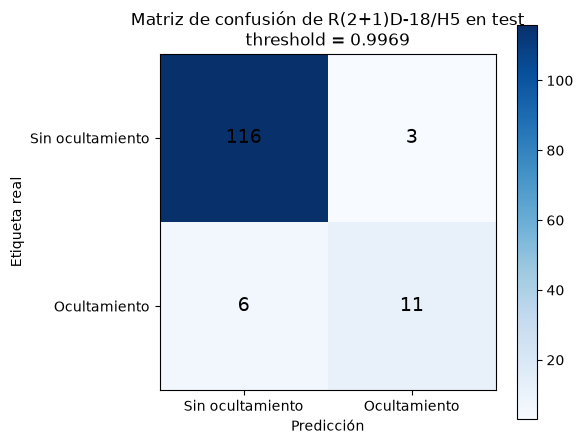

In [69]:
matriz_test_final = np.array([
    [tn_test, fp_test],
    [fn_test, tp_test]
])

fig, ax = plt.subplots(figsize=(6, 5))

imagen = ax.imshow(
    matriz_test_final,
    cmap="Blues"
)

for i in range(2):
    for j in range(2):
        ax.text(
            j,
            i,
            int(matriz_test_final[i, j]),
            ha="center",
            va="center",
            fontsize=14
        )

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])

ax.set_xticklabels([
    "Sin ocultamiento",
    "Ocultamiento"
])

ax.set_yticklabels([
    "Sin ocultamiento",
    "Ocultamiento"
])

ax.set_xlabel("Predicción")
ax.set_ylabel("Etiqueta real")

ax.set_title(
    "Matriz de confusión de R(2+1)D-18/H5 en test\n"
    f"threshold = {THRESHOLD_R2PLUS1D_H5:.4f}"
)

fig.colorbar(imagen, ax=ax)

plt.tight_layout()
plt.show()

La matriz de confusión muestra que R(2+1)D-18/H5 clasifica correctamente 116 de los 119 casos de `sin_ocultamiento` y genera 3 falsos positivos. Esto corresponde a una specificity de 0.9748 y es consistente con el criterio de negocio proporcionado por BNext de mantener al mínimo las falsas alarmas, ya que cada alerta incorrecta puede generar una revisión innecesaria por parte del personal.

Para la clase `ocultamiento`, el modelo identifica correctamente 11 de los 17 casos positivos y deja 6 falsos negativos, lo que corresponde a un recall de 0.6471. Por lo tanto, aunque el modelo mantiene un buen control de falsas alarmas, todavía existe una proporción relevante de ocultamientos que no producirían una alerta.

El resultado muestra el compromiso observado en este punto de operación: presenta una alta especificidad y un número reducido de falsos positivos, junto con una sensibilidad limitada que debe considerarse antes de una eventual aplicación en condiciones reales.

### 15.3 Curva Precision-Recall del modelo final

La curva Precision-Recall muestra el comportamiento de R(2+1)D-18/H5 sobre `test` a través de los diferentes thresholds posibles. Se incluye el punto de operación correspondiente al threshold de 0.9969 seleccionado previamente en `validation`.

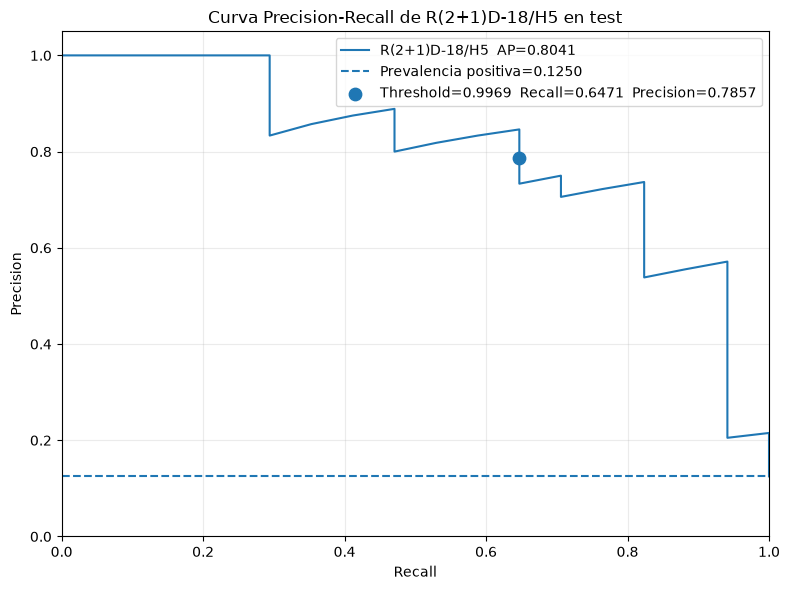

In [70]:
prevalencia_test = y_test_final.mean()

fig, ax = plt.subplots(figsize=(8, 6))

ax.plot(
    recall_pr_test,
    precision_pr_test,
    label=f"R(2+1)D-18/H5  AP={ap_test_final:.4f}"
)

ax.axhline(
    prevalencia_test,
    linestyle="--",
    label=f"Prevalencia positiva={prevalencia_test:.4f}"
)

ax.scatter(
    recall_test_final,
    precision_test_final,
    s=80,
    zorder=5,
    label=(
        f"Threshold={THRESHOLD_R2PLUS1D_H5:.4f}  "
        f"Recall={recall_test_final:.4f}  "
        f"Precision={precision_test_final:.4f}"
    )
)

ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Curva Precision-Recall de R(2+1)D-18/H5 en test")

ax.set_xlim(0, 1)
ax.set_ylim(0, 1.05)

ax.grid(alpha=0.25)
ax.legend()

plt.tight_layout()
plt.show()

La curva Precision-Recall muestra que R(2+1)D-18/H5 mantiene una capacidad de discriminación favorable sobre `test`. El Average Precision de 0.8041 constituye la métrica principal de referencia del proyecto y debe interpretarse considerando que la prevalencia positiva de esta partición es de 0.1250, consistente con el desbalance de clases observado a lo largo de los experimentos.

El punto de operación correspondiente al threshold de 0.9969 alcanza una precision de 0.7857 y un recall de 0.6471. El comportamiento observado es compatible con la prioridad comunicada por BNext de mantener bajo el número de falsas alarmas, aunque este criterio de negocio no fue utilizado directamente para seleccionar el threshold. Desde la perspectiva operativa, las alertas incorrectas pueden ocasionar revisiones innecesarias sobre clientes.

La forma de la curva muestra además el compromiso entre precision y recall: recuperar una mayor proporción de casos de ocultamiento requiere desplazarse hacia puntos con menor precision. El threshold de 0.9969 permanece congelado porque fue seleccionado previamente en `validation` mediante la regla definida para el experimento y no se reajusta utilizando los resultados de `test`.

### 15.4 Curva ROC del modelo final

La curva ROC complementa la evaluación del modelo al mostrar la relación entre la tasa de verdaderos positivos y la tasa de falsos positivos para los diferentes thresholds posibles. Se incluye el punto de operación correspondiente al threshold de 0.9969 seleccionado previamente en `validation`.

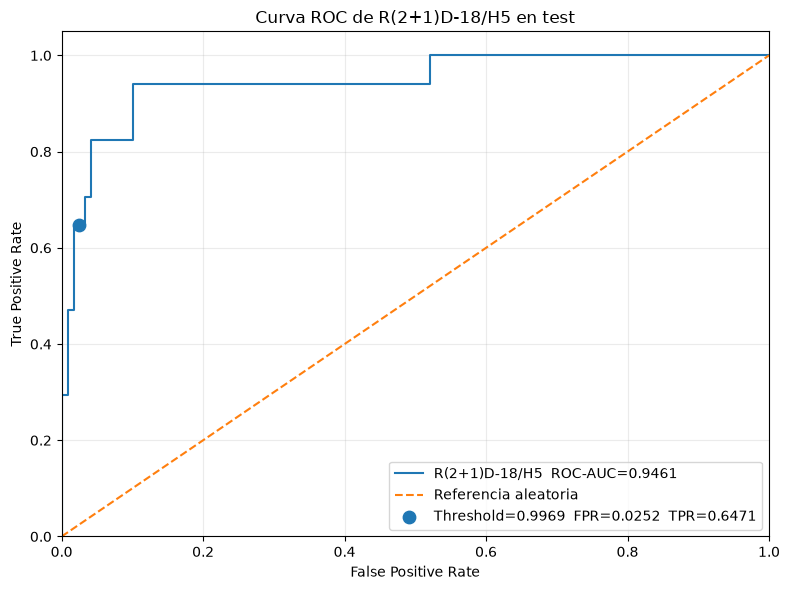

In [71]:
fpr_operacion_test = 1 - specificity_test_final

fig, ax = plt.subplots(figsize=(8, 6))

ax.plot(
    fpr_test_final,
    tpr_test_final,
    label=f"R(2+1)D-18/H5  ROC-AUC={roc_auc_test_final:.4f}"
)

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Referencia aleatoria"
)

ax.scatter(
    fpr_operacion_test,
    recall_test_final,
    s=80,
    zorder=5,
    label=(
        f"Threshold={THRESHOLD_R2PLUS1D_H5:.4f}  "
        f"FPR={fpr_operacion_test:.4f}  "
        f"TPR={recall_test_final:.4f}"
    )
)

ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title(
    "Curva ROC de R(2+1)D-18/H5 en test"
)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1.05)

ax.grid(alpha=0.25)
ax.legend()

plt.tight_layout()
plt.show()

La curva ROC muestra una capacidad alta de discriminación entre las clases `ocultamiento` y `sin_ocultamiento`. El ROC-AUC de 0.9461 indica que el modelo mantiene una separación favorable entre ambas clases a través de los distintos thresholds posibles. Esta métrica describe la capacidad de ranking del modelo y no debe interpretarse como una medida directa de confianza o calibración de las probabilidades individuales.

En el punto de operación seleccionado, el modelo alcanza un False Positive Rate de 0.0252 y un True Positive Rate de 0.6471. Esto significa que aproximadamente 2.52% de los casos reales de `sin_ocultamiento` generan una predicción positiva, mientras que se detecta aproximadamente 64.71% de los casos de `ocultamiento`.

Este comportamiento es consistente con la prioridad comunicada por BNext de minimizar falsas alarmas, incluso aceptando una menor sensibilidad. El modelo opera en una región con una tasa baja de falsos positivos, aunque todavía deja sin generar alerta aproximadamente una tercera parte de los casos positivos.

### 15.5 Distribución de scores del modelo final

La distribución de las probabilidades estimadas permite analizar la separación entre las clases y observar la concentración de los scores alrededor del punto de operación seleccionado. Se muestra el threshold de 0.9969 definido previamente en `validation`.

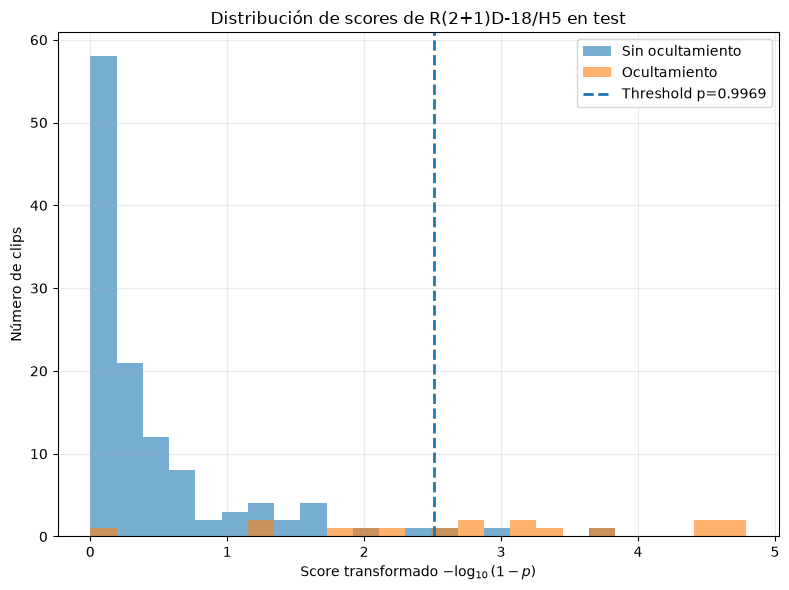

In [72]:
scores_negativos_test = prob_test_final[y_test_final == 0]
scores_positivos_test = prob_test_final[y_test_final == 1]

epsilon_scores = np.finfo(float).eps

scores_negativos_transformados = -np.log10(
    np.clip(
        1.0 - scores_negativos_test,
        epsilon_scores,
        1.0
    )
)

scores_positivos_transformados = -np.log10(
    np.clip(
        1.0 - scores_positivos_test,
        epsilon_scores,
        1.0
    )
)

threshold_transformado = -np.log10(
    max(
        1.0 - THRESHOLD_R2PLUS1D_H5,
        epsilon_scores
    )
)

bins_scores = np.histogram_bin_edges(
    np.concatenate([
        scores_negativos_transformados,
        scores_positivos_transformados
    ]),
    bins=25
)

fig, ax = plt.subplots(figsize=(8, 6))

ax.hist(
    scores_negativos_transformados,
    bins=bins_scores,
    alpha=0.6,
    label="Sin ocultamiento"
)

ax.hist(
    scores_positivos_transformados,
    bins=bins_scores,
    alpha=0.6,
    label="Ocultamiento"
)

ax.axvline(
    threshold_transformado,
    linestyle="--",
    linewidth=2,
    label=(
        f"Threshold p={THRESHOLD_R2PLUS1D_H5:.4f}"
    )
)

ax.set_xlabel(r"Score transformado $-\log_{10}(1-p)$")
ax.set_ylabel("Número de clips")
ax.set_title("Distribución de scores de R(2+1)D-18/H5 en test")

ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

La distribución transformada de scores muestra que una proporción importante de los casos de `sin_ocultamiento` se concentra en valores bajos, correspondientes a probabilidades alejadas de 1.0. En contraste, varios casos de `ocultamiento` se extienden hacia valores transformados altos, asociados con probabilidades muy próximas a 1.0. La transformación $-\log_{10}(1-p)$ conserva el orden de las probabilidades y expande la región superior, permitiendo observar con mayor detalle el comportamiento de los clips próximos al threshold.

La separación entre clases no es completa. Algunos casos de `sin_ocultamiento` alcanzan scores altos y se ubican en la región donde también aparecen varios casos positivos. Estos clips corresponden a observaciones con mayor riesgo de ser clasificadas como positivas cuando superan el punto de operación. De forma complementaria, algunos casos de `ocultamiento` permanecen claramente por debajo del threshold, lo que es consistente con los falsos negativos observados en la matriz de confusión.

En el punto de operación previamente seleccionado en `validation`, el modelo presenta una specificity de 0.9748 y genera 3 falsos positivos en `test`, mientras que 6 casos positivos quedan por debajo del threshold. Este comportamiento observado resulta compatible con la prioridad operativa comunicada por BNext de mantener bajo el número de falsas alarmas, aunque dicha prioridad no fue utilizada como criterio directo para seleccionar el threshold.

### 15.6 Sensibilidad local del punto de operación

Debido a la concentración de los scores cerca de 1.0, se analiza con mayor detalle cómo cambia el número de falsos positivos y falsos negativos ante pequeñas variaciones del threshold alrededor del punto de operación seleccionado.

Este análisis es exclusivamente descriptivo. El threshold de 0.9969 permanece congelado porque fue seleccionado previamente utilizando `validation`. Los resultados de `test` no se utilizan para elegir un nuevo punto de operación.

In [73]:
umbrales_sensibilidad_test = [
    0.9900,
    0.9950,
    THRESHOLD_R2PLUS1D_H5,
    0.9990
]

resultados_sensibilidad_test = []

for threshold in umbrales_sensibilidad_test:
    pred = (
        prob_test_final >= threshold
    ).astype(np.int64)

    tn, fp, fn, tp = confusion_matrix(
        y_test_final,
        pred,
        labels=[0, 1]
    ).ravel()

    resultados_sensibilidad_test.append({
        "threshold": float(threshold),
        "FP": int(fp),
        "FN": int(fn),
        "recall": recall_score(
            y_test_final,
            pred,
            zero_division=0
        )
    })

tabla_sensibilidad_test = pd.DataFrame(
    resultados_sensibilidad_test
)

display(
    tabla_sensibilidad_test.style.format({
        "threshold": "{:.4f}",
        "recall": "{:.4f}"
    })
)

,threshold,FP,FN,recall
0,0.9900,5,4,0.7647
1,0.9950,4,6,0.6471
2,0.9969,3,6,0.6471
3,0.9990,2,9,0.4706


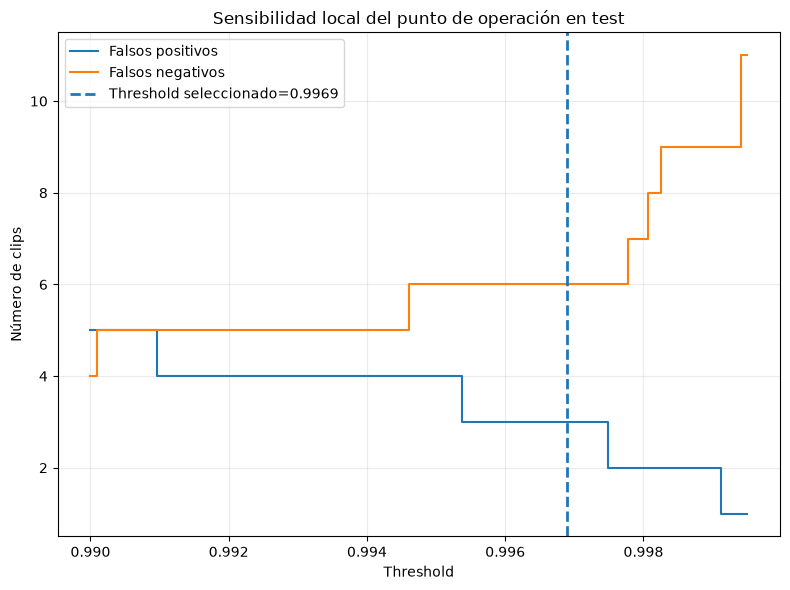

In [74]:
umbrales_locales_test = np.linspace(
    0.9900,
    0.9995,
    100
)

sensibilidad_local_test = []

for threshold in umbrales_locales_test:
    pred = (
        prob_test_final >= threshold
    ).astype(np.int64)

    tn, fp, fn, tp = confusion_matrix(
        y_test_final,
        pred,
        labels=[0, 1]
    ).ravel()

    sensibilidad_local_test.append({
        "threshold": float(threshold),
        "FP": int(fp),
        "FN": int(fn)
    })

df_sensibilidad_local_test = pd.DataFrame(
    sensibilidad_local_test
)

fig, ax = plt.subplots(figsize=(8, 6))

ax.step(
    df_sensibilidad_local_test["threshold"],
    df_sensibilidad_local_test["FP"],
    where="post",
    label="Falsos positivos"
)

ax.step(
    df_sensibilidad_local_test["threshold"],
    df_sensibilidad_local_test["FN"],
    where="post",
    label="Falsos negativos"
)

ax.axvline(
    THRESHOLD_R2PLUS1D_H5,
    linestyle="--",
    linewidth=2,
    label=f"Threshold seleccionado={THRESHOLD_R2PLUS1D_H5:.4f}"
)

ax.set_xlabel("Threshold")
ax.set_ylabel("Número de clips")

ax.set_title("Sensibilidad local del punto de operación en test")

ax.grid(alpha=0.25)
ax.legend()

plt.tight_layout()
plt.show()

En el threshold de 0.9969, definido previamente en `validation`, se observan 3 falsos positivos y 6 falsos negativos sobre `test`. Al examinar descriptivamente thresholds cercanos, la curva muestra cambios escalonados en ambos tipos de error debido al número finito de clips y a la concentración de varios scores en la región superior.

En algunos valores ligeramente superiores a 0.9969 se observan 2 falsos positivos mientras los falsos negativos permanecen temporalmente en 6. Este resultado se reporta únicamente como caracterización de la sensibilidad local. No se utiliza para seleccionar un nuevo threshold porque dicha decisión requeriría utilizar información de `test`.

Al continuar incrementando el threshold, los falsos negativos aumentan con rapidez. En un intervalo del orden de unas milésimas, el número de falsos negativos pasa de 6 a valores progresivamente mayores mientras los falsos positivos disminuyen. Esto muestra que pequeñas variaciones del threshold pueden producir cambios apreciables en el patrón de errores cuando los scores se concentran cerca de 1.0.

Este comportamiento puede orientar futuros experimentos de calibración utilizando nuevos datos de validación o un conjunto independiente específicamente destinado a seleccionar el punto de operación. Los resultados observados en `test` se mantienen únicamente como descripción del comportamiento de la configuración ya congelada.

## 16. Conclusiones

Los experimentos realizados en este avance muestran que los ensambles homogéneos y heterogéneos ofrecen una oportunidad interesante para continuar mejorando el desempeño mediante estrategias que pueden aprovechar modelos preentrenados, representaciones ya disponibles y resultados de modelos previamente ajustados. Aunque ninguno de los cuatro ensambles evaluados superó el Average Precision de R(2+1)D-18/H5, su evaluación permitió identificar comportamientos y compromisos distintos entre recall, precision y generación de falsos positivos. Por lo tanto, su principal aportación en esta etapa fue metodológica y proporciona aprendizajes útiles para experimentos posteriores.

Al igual que en el Avance 4, los resultados del modelo seleccionado muestran que el enfoque utilizado es viable para continuar con la experimentación, aunque todavía no existen elementos suficientes para considerar una implementación productiva. R(2+1)D-18/H5 obtuvo un Average Precision de 0.8041 en `test`, con precision de 0.7857, recall de 0.6471 y specificity de 0.9748. Estas métricas muestran capacidad para discriminar entre casos de ocultamiento y comportamiento normal dentro de los datos disponibles. Sin embargo, la incertidumbre observada en la estimación del Average Precision y el número todavía limitado de ejemplos positivos obligan a interpretar estos resultados como evidencia experimental y no como una estimación definitiva del desempeño que tendría el sistema en tiendas reales de BNext.

La principal limitación identificada continúa siendo la disponibilidad de datasets reales, más amplios y representativos de las condiciones donde eventualmente operaría el sistema. Durante los diferentes experimentos aparecieron de forma recurrente casos visualmente complejos, como el video de las mujeres vestidas de verde y rojo analizado en distintas etapas del proyecto, lo que muestra la importancia de contar con más observaciones de situaciones similares. Como siguientes pasos, sería conveniente incorporar videos reales y más diversos, aumentar la cantidad de ejemplos de ocultamiento y disponer de mayor capacidad de cómputo para evaluar un espacio más amplio de configuraciones e hiperparámetros. Estos elementos permitirían estudiar con mayor solidez la generalización del modelo y determinar hasta qué punto el desempeño observado puede mantenerse frente a condiciones reales de operación.

## 17. Distribución de actividades del equipo

El desarrollo del Avance 5 se realizó de manera colaborativa. La revisión metodológica y discusión de alternativas se distribuyó de forma equivalente entre **Nélida Silva Cabrera** y **José Luis Tinajero Guerrero**, mientras que **Jesús Alberto Jiménez Ramos** realizó el desarrollo técnico, integración y ejecución del notebook. Las decisiones finales fueron revisadas por el equipo antes de incorporarse al avance.

| Integrante | Responsabilidades principales | Actividades realizadas |
|---|---|---|
| **Nélida Silva Cabrera** | Revisión metodológica de ensambles homogéneos, consistencia experimental y documentación | Revisión del uso de embeddings para Random Forest y AdaBoost. Análisis del riesgo de utilizar representaciones provenientes de R(2+1)D-18/H5 ajustado con las etiquetas de `train`. Revisión de la estrategia de validación cruzada agrupada y del espacio de hiperparámetros de los modelos homogéneos. Revisión de tablas, métricas, consistencia entre resultados históricos y actuales, trazabilidad de artefactos y claridad de la documentación metodológica. |
| **José Luis Tinajero Guerrero** | Revisión metodológica de ensambles heterogéneos, evaluación y criterios de selección | Revisión del riesgo de optimismo en Soft Voting y Blending al utilizar `validation`. Análisis de la conveniencia de mantener pesos uniformes en Soft Voting y utilizar predicciones out-of-fold en Blending. Revisión de la transformación logit, selección y sensibilidad del threshold, comparación entre modelos, incertidumbre de las métricas en `test` y relación de los resultados con las prioridades operativas comunicadas por BNext. |
| **Jesús Alberto Jiménez Ramos** | Desarrollo técnico, integración experimental y ejecución del notebook | Implementación de Random Forest, AdaBoost, Soft Voting y Blending. Desarrollo y ajuste de scripts auxiliares, extracción y validación de embeddings, generación y recuperación de artefactos, implementación de validación cruzada agrupada, generación de predicciones out-of-fold, cálculo de métricas y thresholds, construcción de tablas y visualizaciones, benchmark de inferencia, análisis bootstrap, integración de correcciones metodológicas y ejecución final del pipeline mediante `Restart Kernel` y `Run All`. |

Aunque las actividades de revisión se presentan agrupadas para documentar responsabilidades, Nélida Silva Cabrera y José Luis Tinajero Guerrero participaron con un nivel equivalente en la discusión y revisión crítica del avance. La implementación técnica fue concentrada en Jesús Alberto Jiménez Ramos para mantener consistencia en la integración del pipeline y en la ejecución de los experimentos. Las conclusiones y decisiones metodológicas fueron revisadas de manera conjunta por el equipo.

## 18. Decisiones principales y alternativas consideradas

Durante el Avance 5 se tomaron decisiones para mantener la validez experimental de los ensambles, limitar el riesgo de sobreajuste y seleccionar un modelo final considerando desempeño y costo computacional. Las tres decisiones con mayor impacto fueron las siguientes.

### 1. Uso de embeddings preentrenados en Kinetics-400

**Decisión.** Para Random Forest y AdaBoost se utilizaron embeddings obtenidos de R(2+1)D-18 con pesos preentrenados en Kinetics-400, sin utilizar el fine-tuning H5 del proyecto.

**Alternativa considerada.** Utilizar embeddings de R(2+1)D-18/H5, que están mejor adaptados al problema de ocultamiento.

Esta alternativa se descartó porque H5 fue ajustado utilizando las etiquetas de `train`. Realizar posteriormente validación cruzada dentro de esa misma partición produciría embeddings que ya contienen información aprendida de los grupos reservados. Una solución completamente rigurosa requeriría volver a ajustar el extractor dentro de cada fold, con un costo computacional considerablemente mayor.

Los embeddings de Kinetics-400 permitieron aplicar `StratifiedGroupKFold` sin esta fuente específica de fuga. Random Forest obtuvo un AP de **0.5164** y AdaBoost de **0.5538** en `validation`, por debajo del **0.7720** reproducible de R(2+1)D-18/H5. El resultado sugiere que las representaciones genéricas son útiles, pero que el fine-tuning aporta una adaptación relevante al problema.

### 2. Diseño conservador de Soft Voting y Blending

**Decisión.** Soft Voting utilizó pesos uniformes de **0.5 y 0.5** para R(2+1)D-18/H5 y MC3-18/H5. Blending utilizó regresión logística y predicciones out-of-fold generadas mediante `StratifiedGroupKFold` dentro de `validation`.

**Alternativas consideradas.** Optimizar los pesos de Soft Voting sobre `validation` o ajustar y evaluar directamente el meta-modelo de Blending sobre las mismas observaciones.

Ambas alternativas aumentaban el riesgo de obtener estimaciones optimistas debido al tamaño de `validation`, con 136 clips y solo 30 positivos, y porque los modelos base ya habían sido seleccionados utilizando esa partición. Por ello, Soft Voting se mantuvo sin pesos ajustados y Blending se evaluó mediante predicciones out-of-fold.

Soft Voting alcanzó un AP de **0.7469** y recall de **0.8000**, pero generó **15 falsos positivos**. Blending obtuvo un AP OOF de **0.6812**. La transformación logit utilizada en Blending se conservó como decisión de diseño debido a la saturación de las probabilidades de los modelos base, aunque su elección debe interpretarse considerando que se realizó después de una exploración preliminar sobre `validation`.

### 3. Selección de R(2+1)D-18/H5 como modelo final

**Decisión.** Se conservó **R(2+1)D-18/H5** como modelo candidato para la evaluación final sobre `test`.

**Alternativa considerada.** Seleccionar Soft Voting, que presentó un recall mayor y combinó los dos mejores modelos individuales.

En `validation`, R(2+1)D-18/H5 obtuvo un AP de **0.7720**, frente a **0.7469** de Soft Voting. La diferencia de AP fue relativamente pequeña, por lo que también se consideraron las características del punto de operación y el costo computacional. R(2+1)D-18/H5 produjo **1 falso positivo** y una specificity de **0.9906**, mientras que Soft Voting produjo **15 falsos positivos** y una specificity de **0.8585**.

El modelo individual requirió aproximadamente **17.83 ms por clip**, mientras que Soft Voting necesitó **29.38 ms por clip**, aproximadamente **1.65 veces** el costo de inferencia. Soft Voting ofreció mayor recall, pero requirió ejecutar dos CNN y produjo un número considerablemente mayor de falsas alarmas.

Por estas razones se conservó R(2+1)D-18/H5. Su evaluación posterior sobre `test` produjo AP de **0.8041**, precision de **0.7857**, recall de **0.6471** y specificity de **0.9748**, con **3 falsos positivos y 6 falsos negativos**. El intervalo bootstrap del 95% para AP fue amplio, de **0.3734 a 0.9650**, por lo que estos resultados se interpretan como evidencia experimental y no como una estimación definitiva del desempeño en condiciones reales.

En conjunto, los experimentos muestran que los ensambles ofrecen alternativas útiles para modificar el compromiso entre detección, falsas alarmas y costo computacional, aunque en este avance ninguno proporcionó evidencia suficiente para reemplazar al mejor modelo individual.

## 19. Declaración de uso de inteligencia artificial

Durante el desarrollo del Avance 5 se utilizó **ChatGPT de OpenAI** como herramienta de apoyo, de acuerdo con un esquema de asistencia y revisión. Su uso incluyó:

- explicación y discusión de conceptos técnicos;
- consulta y aclaración de sintaxis y documentación;
- identificación y depuración de errores puntuales;
- propuesta de fragmentos de código para tablas, visualizaciones y validaciones;
- revisión de consistencia metodológica;
- apoyo en la interpretación de resultados experimentales;
- revisión y mejora de redacción en celdas Markdown.

El apoyo de IA se utilizó principalmente en las secciones relacionadas con la construcción y comparación de ensambles homogéneos y heterogéneos, generación y validación de embeddings, validación cruzada por grupos, Random Forest, AdaBoost, Soft Voting, Blending, generación de predicciones out-of-fold, transformación logit, selección y análisis del threshold, comparación global de modelos, análisis del costo computacional, evaluación final sobre `test`, análisis de incertidumbre mediante bootstrap por `grupo_experimental`, curvas Precision-Recall y ROC, matrices de confusión, análisis de distribución de scores, sensibilidad local del punto de operación, reproducibilidad y validación de artefactos experimentales.

Los fragmentos de código y propuestas de redacción obtenidos mediante la herramienta fueron **revisados, adaptados e integrados al notebook por el equipo**. Los resultados numéricos utilizados en el análisis provienen de las ejecuciones y artefactos experimentales del proyecto. Las interpretaciones se contrastaron con los outputs correspondientes y se modificaron cuando una afirmación no podía sostenerse directamente con la evidencia disponible.

Durante la revisión del avance, el equipo verificó adicionalmente la consistencia entre los resultados históricos del Avance 4 y los obtenidos en el Avance 5, la trazabilidad de checkpoints y artefactos, la separación entre `validation` y `test`, el procedimiento de selección del threshold y la correcta interpretación de las métricas de los modelos individuales y de ensamble. José Luis Tinajero Guerrero participó en la revisión de criterios experimentales y de interpretación de resultados; Nélida Silva Cabrera revisó elementos de documentación, trazabilidad y consistencia de los resultados; y Jesús Alberto Jiménez Ramos realizó la integración técnica y experimental, además de la ejecución y validación del pipeline completo.

Como comprobación final, el notebook fue ejecutado mediante **`Restart Kernel` y `Run All`**, sin inicializar previamente variables ni ejecutar celdas manualmente. La ejecución terminó sin errores y reutilizó los checkpoints y artefactos previamente validados mediante los controles de generación definidos en el notebook. Esta prueba permitió verificar que la secuencia de preparación de datos, carga de modelos, recuperación de artefactos, evaluación de los ensambles, selección del modelo final y generación de resultados puede ejecutarse en el orden documentado.

La herramienta de IA **no sustituyó la ejecución de los experimentos ni la validación de sus resultados**. Las decisiones incorporadas al avance fueron revisadas por el equipo y deben poder ser explicadas, justificadas y modificadas por sus integrantes.

### Referencia

OpenAI. (2026). *ChatGPT* [Modelo de lenguaje de gran escala]. https://chatgpt.com/

## 20. Repositorio del proyecto

El notebook correspondiente al Avance 5 se encuentra en el repositorio privado de GitHub utilizado por el equipo para el desarrollo del proyecto:

**Repositorio:**  
https://github.com/joseluistinajero/MNA---Proyecto-Integrador

**Notebook del Avance 5:**  
https://github.com/joseluistinajero/MNA---Proyecto-Integrador/blob/main/Notebooks/Avance5_Equipo41.ipynb